In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
import os
from scipy import stats
from matplotlib.ticker import MaxNLocator

In [2]:
warnings.filterwarnings("ignore")
pd.set_option("display.max.columns", None)
pd.set_option("display.width", 200)

In [3]:
# One main colour, one highlight colour, one neutral

BLUE, ORANGE, GREY, INK, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#8a8a85", "#52514e", "#1baf7a", "#eda100", "#e87ba4"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#b9b8b2", "#52514e"]

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": INK,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})

In [4]:
# STACK_ORDER keeps orange away from yellow and pink so neighbouring segments stay easy to tell apart.

MODE_COLOR = {"caught": BLUE, "run out": ORANGE, "bowled": AQUA, "lbw": YELLOW, "stumped": MAGENTA, "other": GREY}
STACK_ORDER = ["caught", "run out", "bowled", "lbw", "stumped", "other"]
BOWLER_ORDER = ["caught", "bowled", "lbw", "stumped", "other"]
MODE_LABEL = {"caught": "Caught", "run out": "Run out", "bowled": "Bowled", "lbw": "LBW",
              "stumped": "Stumped", "other": "Other (hit wicket, obstructing)"}

In [5]:
# Bowler and fielder names are often surnames only ("Sharma", "Singh", "Kumar"). A name shared by this many
# batters in the file is treated as several different people and left out of the bowler/fielder rankings.
# Set EXCLUDE_AMBIGUOUS = False to keep them (they are then marked with * in the charts).

AMBIGUOUS_MIN = 3
EXCLUDE_AMBIGUOUS = True

In [6]:
MIN_BALLS = 500
MIN_TEAM_INNINGS = 40

In [7]:
# Where the raw data is, and where results are saved.
# Works from a GitHub clone (data/ipl_batting.csv) and in Colab (ipl_batting.csv uploaded next to the notebook).
if os.path.basename(os.getcwd()) == "outputs":      # makes it safe to re-run this cell
    os.chdir("..")
DATA_PATH = os.path.abspath(next((p for p in ["data/ipl_batting.csv", "ipl_batting.csv"] if os.path.exists(p)), "ipl_batting.csv"))
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.chdir(OUTPUT_DIR)                                # every CSV and chart the notebook saves goes into outputs/
print("Data file:", os.path.relpath(DATA_PATH, ".."))

Data file: data/ipl_batting.csv


In [8]:
ipl_batting = pd.read_csv(DATA_PATH)
ipl_cricket = ipl_batting.copy()
print(f"Loaded {ipl_cricket.shape[0]:,} rows x {ipl_cricket.shape[1]} columns")

Loaded 11,546 rows x 17 columns


In [9]:
ipl_cricket.head()

,match_no,team_1,team_2,batsmen,wicket_status,R,B,M,fours,sixes,SR,special_role,dismissal_mode,bowler_name,fielder,is_fielder_involved,match_date
0,1,Mumbai Indians,Chennai Super Kings,ST Jayasuriya,c Hayden b Thushara,26.0,20.0,0.0,5.0,0.0,130.00,normal player,caught,Thushara,Hayden,1,2009-04-18
1,1,Mumbai Indians,Chennai Super Kings,SR Tendulkar,not out,59.0,49.0,0.0,7.0,0.0,120.40,captain,not out,no bowler,no fielder,0,2009-04-18
2,1,Mumbai Indians,Chennai Super Kings,S Dhawan,c Dhoni b Gony,22.0,21.0,0.0,2.0,0.0,104.76,normal player,caught,Gony,Dhoni,1,2009-04-18
3,1,Mumbai Indians,Chennai Super Kings,JP Duminy,c & b Gony,9.0,7.0,0.0,1.0,0.0,128.57,normal player,caught,Gony,Gony,1,2009-04-18
4,1,Mumbai Indians,Chennai Super Kings,DJ Bravo,c Hayden b Joginder Sharma,5.0,4.0,0.0,1.0,0.0,125.00,normal player,caught,Joginder Sharma,Hayden,1,2009-04-18


In [10]:
ipl_cricket = pd.read_csv(DATA_PATH, parse_dates=["match_date"])
print(f"Loaded {ipl_cricket.shape[0]:,} rows x {ipl_cricket.shape[1]} columns, with {ipl_cricket['match_date'].nunique()} unique match dates")

Loaded 11,546 rows x 17 columns, with 546 unique match dates


In [11]:
# Cricket definitions:
#  - Innings          : every row except 'absent hurt' (those players were listed but never batted)
#  - Dismissed        : out by caught, bowled, lbw, run out, stumped, hit wicket or obstructing the field.
#                       'not out' and 'retired' count as not out, as in official statistics.
#  - Batting average  : runs / dismissals          (undefined if the player was never dismissed)
#  - Strike rate      : total runs / total balls x 100   (NOT the mean of the per-innings SR column)

ipl_cricket["batted"] = ipl_cricket["dismissal_mode"] != "absent hurt"
ipl_cricket["dismissed"] = ~ipl_cricket["dismissal_mode"].isin(["not out", "retired", "absent hurt"])
ipl_cricket["is_fifty"] = ipl_cricket["R"].between(50, 99)
ipl_cricket["is_hundred"] = ipl_cricket["R"] >= 100
ipl_cricket["is_captain"] = ipl_cricket["special_role"].str.contains("captain")
ipl_cricket["is_keeper"] = ipl_cricket["special_role"].str.contains("wicket")

# Safely extract season from match_date if not already defined
if "season" not in ipl_cricket.columns:
    ipl_cricket["season"] = pd.to_datetime(ipl_cricket["match_date"], errors="coerce").dt.year

bat = ipl_cricket[ipl_cricket["batted"]].copy()
print(f"Innings used: {len(bat):,} (dropped {int((~ipl_cricket['batted']).sum())} 'absent hurt' rows)")

def summarise(frame, by):
    """One row per group with the standard batting measures."""
    t = frame.groupby(by).agg(
        innings=("R", "size"),
        dismissals=("dismissed", "sum"),
        runs=("R", "sum"),
        balls=("B", "sum"),
        highest=("R", "max"),
        fifties=("is_fifty", "sum"),
        hundreds=("is_hundred", "sum"),
        fours=("fours", "sum"),
        sixes=("sixes", "sum"),
        seasons=("season", "nunique"),
    )

    balls = t["balls"].replace(0, np.nan)
    boundaries = (t["fours" ] + t["sixes"]).replace(0, np.nan)
    t["not_outs"] = t["innings"] - t["dismissals"]
    t["average"] = t["runs"] / t["dismissals"].replace(0, np.nan)
    t["strike_rate"] = t["runs"] / balls * 100
    t["runs_per_innings"] = t["runs"] / t["innings"]
    t["boundary_runs"] = t["fours"] * 4 + t["sixes"] * 6
    t["boundary_pct"] = t["boundary_runs"] / t["runs"].replace(0, np.nan) * 100
    t["balls_per_boundary"] = t["balls"] / boundaries
    t["balls_per_six"] = t["balls"] / t["sixes"].replace(0, np.nan)
    t["fours_per100"] = t["fours"] / balls * 100
    t["sixes_per100"] = t["sixes"] / balls * 100
    return t

def hbar(ax, labels, values, title, xlabel, fmt="%d", color=BLUE):
    """Horizontal bar chart, largest at the top, value labels at the bar ends."""
    y = np.arange(len(labels))
    bars = ax.barh(y, values, color=color, height=0.65)
    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()
    ax.bar_label(bars, fmt=fmt, padding=3, fontsize=9, color=INK)
    ax.set_xlim(0, max(values) * 1.15)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)

players = summarise(bat, "batsmen")                  # every batter
MIN_BALLS = 500                                      # rate stats (SR, average, boundaries) need a fair sample
qualified = players[players["balls"] >= MIN_BALLS].copy()
print(f"{len(players)} batters in total; {len(qualified)} faced at least {MIN_BALLS} balls and are used for rate comparisons")

Innings used: 11,540 (dropped 6 'absent hurt' rows)


518 batters in total; 92 faced at least 500 balls and are used for rate comparisons


In [12]:
def stacked_share(ax, share, order, title, xlabel=""):
    """100% stacked bars. 'share' has one row per bar and one column per category (values in %)."""
    bottom = np.zeros(len(share))
    for k in order:
        ax.bar(share.index.astype(str), share[k], bottom=bottom, color=MODE_COLOR[k], width=0.72,
               edgecolor="white", linewidth=1.5, label=MODE_LABEL[k])
        bottom += share[k].values
    ax.set_ylim(0, 100)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("% of dismissals")
    ax.tick_params(axis="x", labelsize=8, rotation=45)

def stacked_hbar(ax, table, cols, colors, labels, title, xlabel):
    """Horizontal stacked counts with the total printed at the end of each bar."""
    y = np.arange(len(table))
    left = np.zeros(len(table))
    for c, col, lab in zip(cols, colors, labels):
        if table[c].sum() == 0:
            continue
        ax.barh(y, table[c].values, left=left, color=col, edgecolor="white", linewidth=1.5, height=0.65, label=lab)
        left += table[c].values
    ax.set_yticks(y)
    ax.set_yticklabels(table.index)
    ax.invert_yaxis()
    for yi, tot in zip(y, left):
        ax.text(tot + left.max() * 0.015, yi, f"{int(tot)}", va="center", fontsize=9, color=INK)
    ax.set_xlim(0, left.max() * 1.12)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    ax.legend(frameon=False, fontsize=9, loc="lower right")

In [13]:
# Definitions:

ipl_cricket["batted"] = ipl_cricket["dismissal_mode"] != "absent hurt"
ipl_cricket["dismissed"] = ~ipl_cricket["dismissal_mode"].isin(["not out", "retired", "absent hurt"])
ipl_cricket["is_fifty"] = ipl_cricket["R"].between(50, 99)
ipl_cricket["is_hundred"] = ipl_cricket["R"] >= 100
ipl_cricket["is_captain"] = ipl_cricket["special_role"].str.contains("captain")

def summarise(frame, by):
    """One row per group with the standard batting measures."""
    t = frame.groupby(by).agg(
        innings=("R", "size"), dismissals=("dismissed", "sum"), runs=("R", "sum"), balls=("B", "sum"),
        highest=("R", "max"), fifties=("is_fifty", "sum"), hundreds=("is_hundred", "sum"),
        fours=("fours", "sum"), sixes=("sixes", "sum"), seasons=("season", "nunique"),
        pct_30_plus=("R", lambda s: (s >= 30).mean() * 100),
    )
    t["average"] = t["runs"] / t["dismissals"].replace(0, np.nan)
    t["strike_rate"] = t["runs"] / t["balls"].replace(0, np.nan) * 100
    t["runs_per_innings"] = t["runs"] / t["innings"]
    t["boundary_pct"] = (t["fours"] * 4 + t["sixes"] * 6) / t["runs"].replace(0, np.nan) * 100
    t["fours_per100"] = t["fours"] / t["balls"].replace(0, np.nan) * 100
    t["sixes_per100"] = t["sixes"] / t["balls"].replace(0, np.nan) * 100
    return t

def hbar(ax, labels, values, title, xlabel, fmt="%d", color=BLUE):
    """Horizontal bar chart, largest at the top, value labels at the bar ends."""
    y = np.arange(len(labels))
    bars = ax.barh(y, values, color=color, height=0.65)
    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()
    ax.bar_label(bars, fmt=fmt, padding=3, fontsize=9, color=INK)
    ax.set_xlim(0, max(values) * 1.15)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)

# **Objective 1: Understand the IPL Data**

# **Task 1: Understand the matches, teams, and players**

In [14]:
# Look at the data

print("Shape: ", ipl_cricket.shape)

Shape:  (11546, 24)


In [15]:
display(ipl_cricket.head())

,match_no,team_1,team_2,batsmen,wicket_status,R,B,M,fours,sixes,SR,special_role,dismissal_mode,bowler_name,fielder,is_fielder_involved,match_date,batted,dismissed,is_fifty,is_hundred,is_captain,is_keeper,season
0,1,Mumbai Indians,Chennai Super Kings,ST Jayasuriya,c Hayden b Thushara,26.0,20.0,0.0,5.0,0.0,130.00,normal player,caught,Thushara,Hayden,1,2009-04-18,True,True,False,False,False,False,2009.0
1,1,Mumbai Indians,Chennai Super Kings,SR Tendulkar,not out,59.0,49.0,0.0,7.0,0.0,120.40,captain,not out,no bowler,no fielder,0,2009-04-18,True,False,True,False,True,False,2009.0
2,1,Mumbai Indians,Chennai Super Kings,S Dhawan,c Dhoni b Gony,22.0,21.0,0.0,2.0,0.0,104.76,normal player,caught,Gony,Dhoni,1,2009-04-18,True,True,False,False,False,False,2009.0
3,1,Mumbai Indians,Chennai Super Kings,JP Duminy,c & b Gony,9.0,7.0,0.0,1.0,0.0,128.57,normal player,caught,Gony,Gony,1,2009-04-18,True,True,False,False,False,False,2009.0
4,1,Mumbai Indians,Chennai Super Kings,DJ Bravo,c Hayden b Joginder Sharma,5.0,4.0,0.0,1.0,0.0,125.00,normal player,caught,Joginder Sharma,Hayden,1,2009-04-18,True,True,False,False,False,False,2009.0


In [16]:
ipl_cricket.info()

<class 'pandas.DataFrame'>
RangeIndex: 11546 entries, 0 to 11545
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   match_no             11546 non-null  str    
 1   team_1               11546 non-null  str    
 2   team_2               11546 non-null  str    
 3   batsmen              11546 non-null  str    
 4   wicket_status        11546 non-null  str    
 5   R                    11546 non-null  float64
 6   B                    11546 non-null  float64
 7   M                    11546 non-null  float64
 8   fours                11546 non-null  float64
 9   sixes                11546 non-null  float64
 10  SR                   11546 non-null  float64
 11  special_role         11546 non-null  str    
 12  dismissal_mode       11546 non-null  str    
 13  bowler_name          11546 non-null  str    
 14  fielder              11546 non-null  str    
 15  is_fielder_involved  11546 non-null  int64  
 1

In [17]:
# Column guide: What each column holds

meaning = {
    "match_no": "Match label inside a season (league match number or play-off stage)",
    "team_1": "First team of the match",
    "team_2": "Second team of the match",
    "batsmen": "Batter name",
    "wicket_status": "Scorecard dismissal text",
    "R": "Runs scored",
    "B": "Balls scored",
    "M": "Mintues batted",
    "fours": "Number of fours hit",
    "sixes": "Numbers of sixes hit",
    "SR": "Strike Rate",
    "special_role": "captain / wicket keeper / captain & wicket keeper / normal player",
    "dismissal_mode": "How the batter was out (or 'not out')",
    "bowler_name": "Bowler credited with the wicket ('no bowler' if none)",
    "fielder": "Fielder involved in the catch or stumping ('no fielder' if none)",
    "is_fielder_involved": "1 if a fielder was involved in the dismissal, else 0",
    "match_date": "Date of the match"
}

column_guide = pd.DataFrame({
    "dtype": ipl_cricket.dtypes.astype(str),
    "unique_values": ipl_cricket.nunique(),
    "example": [ipl_cricket[c].iloc[0] for c in ipl_cricket.columns],
    "meaning": [meaning.get(c, "") for c in ipl_cricket.columns],
})

display(column_guide)

,dtype,unique_values,example,meaning
match_no,str,210,1,Match label inside a season (league match numb...
team_1,str,15,Mumbai Indians,First team of the match
team_2,str,15,Chennai Super Kings,Second team of the match
batsmen,str,518,ST Jayasuriya,Batter name
wicket_status,str,4593,c Hayden b Thushara,Scorecard dismissal text
R,float64,126,26.0,Runs scored
B,float64,70,20.0,Balls scored
M,float64,111,0.0,Mintues batted
fours,float64,18,5.0,Number of fours hit
sixes,float64,15,0.0,Numbers of sixes hit


In [18]:
# Matches: The file has no match id, so one match = one (date, team_1, team_2) combination.

ipl_cricket["match_id"] = ipl_cricket.groupby(["match_date", "team_1", "team_2"], sort=False).ngroup() + 1

valid_dates = pd.to_datetime(ipl_cricket["match_date"], errors="coerce")
print("Batting records (rows)  :", f"{len(ipl_cricket):,}")
print("Matches                 :", ipl_cricket["match_id"].nunique())
print("Unique batters          :", ipl_cricket["batsmen"].nunique())
print("Unique team names       :", pd.concat([ipl_cricket["team_1"], ipl_cricket["team_2"]]).nunique())
print("Date range (valid dates):", valid_dates.min().date(), "to", valid_dates.max().date())

batters_per_match = ipl_cricket.groupby("match_id").size()
print("\nBatting records per match (both innings together):")
display(batters_per_match.describe().round(1).to_frame("batters_per_match").T)

# Matches per season. The year is read from the text of match_date, so a bad date stays visible.

matches_per_year = ipl_cricket.groupby(ipl_cricket["match_date"].str[:4])["match_id"].nunique().rename("matches")
display(matches_per_year.to_frame().T)

Batting records (rows)  : 11,546
Matches                 : 756
Unique batters          : 518
Unique team names       : 15
Date range (valid dates): 2008-04-18 to 2019-05-12

Batting records per match (both innings together):


,count,mean,std,min,25%,50%,75%,max
batters_per_match,756.0,15.3,2.9,5.0,13.0,15.0,17.0,22.0


match_date,---,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
matches,1,58,57,60,73,74,76,59,59,60,59,60,60


In [19]:
# Teams: names as they appear in the raw file, and how many matches each played

team_matches = (
    pd.concat([ipl_cricket[["match_id", "team_1"]].rename(columns={"team_1": "team"}),
               ipl_cricket[["match_id", "team_2"]].rename(columns={"team_2": "team"})])
    .drop_duplicates()
    .groupby("team")["match_id"].nunique()
    .sort_values(ascending=False)
    .rename("matches_played")
    .to_frame()
)

display(team_matches)

,matches_played
team,
Mumbai Indians,187
Royal Challengers Bangalore,180
Kolkata Knight Riders,178
Kings XI Punjab,176
Chennai Super Kings,164
Delhi Daredevils,161
Rajasthan Royals,147
Sunrisers Hyderabad,108
Deccan Chargers,75


In [20]:
# Players: how often each batter appears, roles, and how innings end

innings_per_player = ipl_cricket["batsmen"].value_counts()

print("Most frequent batters:")
display(innings_per_player.head(10).rename("innings").to_frame())

print(f"Batters with only one batting record: {(innings_per_player == 1).sum()} of {len(innings_per_player)}")

print("\nSpecial roles:")
display(ipl_cricket["special_role"].value_counts().rename("rows").to_frame())

print("Dismissal modes:")
display(ipl_cricket["dismissal_mode"].value_counts().rename("rows").to_frame())

print("Numeric columns at a glance:")
display(ipl_cricket[["R", "B", "M", "fours", "sixes", "SR"]].describe().T.round(2))

Most frequent batters:


,innings
batsmen,
SK Raina,189
RG Sharma,183
MS Dhoni,170
RV Uthappa,170
V Kohli,169
KD Karthik,163
S Dhawan,158
YK Pathan,154
G Gambhir,153


Batters with only one batting record: 64 of 518

Special roles:


,rows
special_role,
normal player,9107
captain,1088
wicket keeper,1061
captain & wicket keeper,290


Dismissal modes:


,rows
dismissal_mode,
caught,5552
not out,2713
bowled,1578
run out,850
lbw,540
stumped,284
retired,11
hit wicket,10
absent hurt,6


Numeric columns at a glance:


,count,mean,std,min,25%,50%,75%,max
R,11546.0,19.18,20.95,0.0,3.00,12.00,28.00,175.0
B,11546.0,15.03,13.57,0.0,5.00,11.00,22.00,73.0
M,11546.0,14.18,20.65,0.0,0.00,4.00,21.00,112.0
fours,11546.0,1.76,2.29,0.0,0.00,1.00,3.00,19.0
sixes,11546.0,0.71,1.30,0.0,0.00,0.00,1.00,17.0
SR,11546.0,108.16,67.57,0.0,66.66,107.14,146.15,600.0


## **Task 2: Check missing and duplicate information**

In [21]:
# Missing Values

missing = pd.DataFrame({
    "Missing": ipl_cricket.isna().sum(),
    "Percent": (ipl_cricket.isna().mean() * 100). round(2),
})

display(missing)

print("Total NaN cells: ", int(ipl_cricket.isna().sum().sum()))

,Missing,Percent
match_no,0,0.00
team_1,0,0.00
team_2,0,0.00
batsmen,0,0.00
wicket_status,0,0.00
R,0,0.00
B,0,0.00
M,0,0.00
fours,0,0.00
sixes,0,0.00


Total NaN cells:  20


In [22]:
# Hidden missing values: placeholders that pandas does not count as NaN

hidden = pd.DataFrame([
    ["match_date", "'---' instead of a date",
     int((ipl_cricket["match_date"].str.strip() == "---").sum()),
     "Convert to a missing date; fill the season from neighbouring matches"],
    ["M (minutes)", "0 minutes although balls were faced",
     int(((ipl_cricket["M"] == 0) & (ipl_cricket["B"] > 0)).sum()),
     "Not recorded, set to NaN"],
    ["SR", "0.00 when no ball was faced (strike rate is undefined)",
     int(((ipl_cricket["B"] == 0) & (ipl_cricket["SR"] == 0)).sum()),
     "Set to NaN, add a faced_ball flag"],
    ["bowler_name", "'no bowler' (not applicable: not out, run out, retired ...)",
     int((ipl_cricket["bowler_name"] == "no bowler").sum()),
     "Set to NaN"],
    ["fielder", "'no fielder' (not applicable)",
     int((ipl_cricket["fielder"] == "no fielder").sum()),
     "Set to NaN"],
], columns=["column", "hidden problem", "rows", "treatment"])

display(hidden)

,column,hidden problem,rows,treatment
0,match_date,'---' instead of a date,20,Convert to a missing date; fill the season fro...
1,M (minutes),0 minutes although balls were faced,4630,"Not recorded, set to NaN"
2,SR,0.00 when no ball was faced (strike rate is un...,254,"Set to NaN, add a faced_ball flag"
3,bowler_name,"'no bowler' (not applicable: not out, run out,...",3582,Set to NaN
4,fielder,'no fielder' (not applicable),5710,Set to NaN


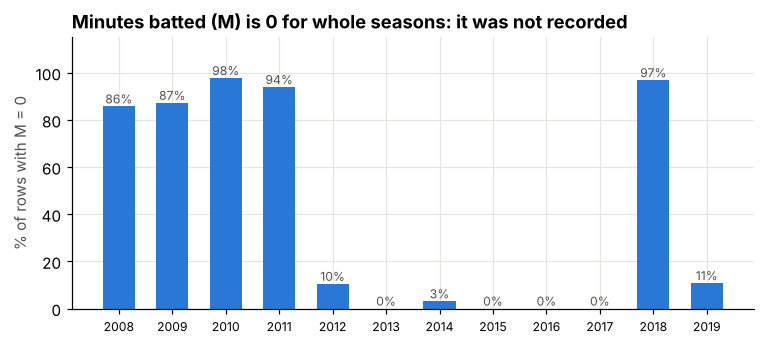

In [23]:
# Evidence for the minutes column: is it missing at random, or missing for whole seasons?

year = ipl_cricket["match_date"].str[:4]
m_zero_by_year = (((ipl_cricket["M"] == 0) & (ipl_cricket["B"] > 0)).groupby(year).mean() * 100).round(1)
m_zero_by_year = m_zero_by_year.drop("---", errors="ignore")      # the undated match is not a season

fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.bar(m_zero_by_year.index, m_zero_by_year.values, color=BLUE, width=0.6)
ax.bar_label(bars, fmt="%.0f%%", fontsize=8, color=INK)
ax.set_title("Minutes batted (M) is 0 for whole seasons: it was not recorded")
ax.set_ylabel("% of rows with M = 0")
ax.set_ylim(0, 115)
ax.tick_params(axis="x", labelsize=8)
plt.show()

In [24]:
# Duplicate information

print("Fully duplicated rows                         :", int(ipl_cricket.duplicated().sum()))
print("Same batter listed twice in one match         :", int(ipl_cricket.duplicated(subset=["match_id", "batsmen"]).sum()))
print("Matches carrying more than one match_no label :", int((ipl_cricket.groupby("match_id")["match_no"].nunique() > 1).sum()))

Fully duplicated rows                         : 0
Same batter listed twice in one match         : 0
Matches carrying more than one match_no label : 0


In [25]:
# Same player spelled two ways (differences in case, spaces or punctuation only)?

def squash(name):
    return re.sub(r"[^a-z]", "", name.lower())

names = pd.Series(ipl_cricket["batsmen"].unique())
variants = names.groupby(names.map(squash)).apply(list)
print("Batter names that differ only by case/space/punctuation:", int((variants.map(len) > 1).sum()))

Batter names that differ only by case/space/punctuation: 0


In [26]:
# Treat missing values and duplicates

ipl_cricket = ipl_cricket.drop_duplicates().reset_index(drop=True)    # nothing to drop here; kept so the notebook also works on refreshed data

# Dates: '---' becomes NaT

ipl_cricket["match_date"] = pd.to_datetime(ipl_cricket["match_date"], format="%Y-%m-%d", errors="coerce")

# Season = year of the match. For a match without a date, borrow the season only when the # matches just before and just after it agree (the file is in date order).

ipl_cricket["season"] = ipl_cricket["match_date"].dt.year
prev_season, next_season = ipl_cricket["season"].ffill(), ipl_cricket["season"].bfill()

ipl_cricket["season"] = ipl_cricket["season"].fillna(prev_season.where(prev_season == next_season)).astype("Int64")

print("Matches with a missing date:")
display(ipl_cricket.loc[ipl_cricket["match_date"].isna(), ["match_id", "match_no", "team_1", "team_2", "season"]].drop_duplicates())

# Minutes: 0 with balls faced means "not recorded"

ipl_cricket.loc[(ipl_cricket["M"] == 0) & (ipl_cricket["B"] > 0), "M"] = np.nan

# Strike rate is undefined when no ball was faced

ipl_cricket["faced_ball"] = ipl_cricket["B"] > 0
ipl_cricket.loc[~ipl_cricket["faced_ball"], "SR"] = np.nan

# "Not applicable" placeholders become real missing values

ipl_cricket[["bowler_name", "fielder"]] = ipl_cricket[["bowler_name", "fielder"]].replace({"no bowler": np.nan, "no fielder": np.nan})

remaining = ipl_cricket.isna().sum()

print("\nMissing values after treatment (only columns that have any):")
display(remaining[remaining > 0].rename("missing").to_frame())

Matches with a missing date:


,match_id,match_no,team_1,team_2,season
5112,337,Qualifier 1 (D/N),Kolkata Knight Riders,Kings XI Punjab,2014



Missing values after treatment (only columns that have any):


,missing
M,4630
SR,254
bowler_name,3582
fielder,5710
match_date,20


# Task 3: Check and correct inconsistent data

In [27]:
# 3.1 Text hygiene: stray spaces and inconsistent letter case

text_cols = [c for c in ipl_cricket.columns
             if not pd.api.types.is_numeric_dtype(ipl_cricket[c])
             and not pd.api.types.is_datetime64_any_dtype(ipl_cricket[c])
             and not pd.api.types.is_bool_dtype(ipl_cricket[c])]

before = ipl_cricket[text_cols].copy()
for c in text_cols:
    ipl_cricket[c] = ipl_cricket[c].str.strip().str.replace(r"\s+", " ", regex=True)
print("Text cells changed by trimming spaces:", int((before.fillna("") != ipl_cricket[text_cols].fillna("")).sum().sum()))

print("\ndismissal_mode before:", sorted(ipl_cricket["dismissal_mode"].unique()))
ipl_cricket["dismissal_mode"] = ipl_cricket["dismissal_mode"].str.lower()      # 'Obstructing the field' was the only capitalised value
print("dismissal_mode after :", sorted(ipl_cricket["dismissal_mode"].unique()))

Text cells changed by trimming spaces: 0

dismissal_mode before: ['Obstructing the field', 'absent hurt', 'bowled', 'caught', 'hit wicket', 'lbw', 'not out', 'retired', 'run out', 'stumped']
dismissal_mode after : ['absent hurt', 'bowled', 'caught', 'hit wicket', 'lbw', 'not out', 'obstructing the field', 'retired', 'run out', 'stumped']


In [28]:
# Team names
# - 'Rising Pune Supergiant' / 'Rising Pune Supergiants' are one franchise spelled two ways.
# - 'Delhi Daredevils' was renamed 'Delhi Capitals' in 2019 (same franchise). Set the flag to False to keep both names.
# - Deccan Chargers and Sunrisers Hyderabad are different franchises, so they stay separate.

MERGE_DELHI_RENAME = True

team_fix = {"Rising Pune Supergiants": "Rising Pune Supergiant"}

if MERGE_DELHI_RENAME:
    team_fix["Delhi Daredevils"] = "Delhi Capitals"

print("Team names before:", pd.concat([ipl_cricket["team_1"], ipl_cricket["team_2"]]).nunique())

for c in ["team_1", "team_2"]:
    ipl_cricket[c] = ipl_cricket[c].replace(team_fix)

print("Team names after :", pd.concat([ipl_cricket["team_1"], ipl_cricket["team_2"]]).nunique())

team_long = pd.concat([ipl_cricket[["season", "team_1"]].rename(columns={"team_1": "team"}),
                       ipl_cricket[["season", "team_2"]].rename(columns={"team_2": "team"})])

display(team_long.groupby("team")["season"].agg(first_season="min", last_season="max", seasons="nunique"))

Team names before: 15
Team names after : 13


,first_season,last_season,seasons
team,,,
Chennai Super Kings,2008,2019,10
Deccan Chargers,2008,2012,5
Delhi Capitals,2008,2019,12
Gujarat Lions,2016,2017,2
Kings XI Punjab,2008,2019,12
Kochi Tuskers Kerala,2011,2011,1
Kolkata Knight Riders,2008,2019,12
Mumbai Indians,2008,2019,12
Pune Warriors,2011,2013,3


In [29]:
# Match_no is a mix of formats ('1', '3rd match', '2nd Match (D/N)', 'Qualifier 1 (N)', 'Final (D/N)' ...)
# Split it into three clean columns: match_number, stage, day_night

def parse_match_label(label):

    low = label.lower()
    if "place play-off" in low:
        stage = "Third-place play-off"
    elif "semi" in low:
        stage = "Semi-final"
    elif "elimin" in low:
        stage = "Eliminator"
    elif "qualif" in low:
        stage = "Qualifier"
    elif "final" in low:
        stage = "Final"
    else:
        stage = "League"

    number = re.match(r"\d+", label)

    match_number = int(number.group()) if (stage == "League" and number) else np.nan

    if "(d/n)" in low:
        day_night = "Day/Night"
    elif "(n)" in low:
        day_night = "Night"
    else:
        day_night = "Not specified"
    return match_number, stage, day_night

labels = pd.Series(ipl_cricket["match_no"].unique(), name="match_no")
parsed = pd.DataFrame([parse_match_label(x) for x in labels], columns=["match_number", "stage", "day_night"])
parsed["match_no"] = labels

ipl_cricket = ipl_cricket.merge(parsed, on="match_no", how="left")
ipl_cricket["match_number"] = ipl_cricket["match_number"].astype("Int64")

# The plain labels '1', '21', '31' ... look like '1st match', '21st match' ... with the rest of the text lost.
# So a label of '1' can be league match 1 OR the first play-off game of an early season ('1st Semi-Final' etc.).
# Rule: in a season that has a '2nd Semi-Final' / '2nd Qualifying ...' game, a second '1' (the later one) is its
# first play-off partner, and it takes the same stage.

one_match_each = ipl_cricket.drop_duplicates("match_id")
partner_stage = (one_match_each[one_match_each["match_no"].str.match(r"^2nd (?:Semi|Qualifying)", case=False)]
                 .groupby("season")["stage"].first().to_dict())
league_ones = (one_match_each[(one_match_each["stage"] == "League") & (one_match_each["match_number"] == 1).fillna(False)]
               .sort_values("match_date"))
later_ones = league_ones[league_ones.duplicated("season", keep="first") & league_ones["season"].isin(list(partner_stage))]

fix = ipl_cricket["match_id"].isin(later_ones["match_id"])
ipl_cricket.loc[fix, "stage"] = ipl_cricket.loc[fix, "season"].map(partner_stage)
ipl_cricket.loc[fix, "match_number"] = pd.NA

print("Matches relabelled from 'league match 1' to a play-off game:")
display(later_ones[["match_id", "season", "match_date", "team_1", "team_2"]]
        .assign(new_stage=later_ones["season"].map(partner_stage)))

match_level = ipl_cricket.drop_duplicates("match_id")
stage_order = ["League", "Qualifier", "Eliminator", "Semi-final", "Third-place play-off", "Final"]

print("Matches per season by stage:")
display(pd.crosstab(match_level["season"], match_level["stage"]).reindex(columns=stage_order, fill_value=0))

print("Matches by day/night tag:")
display(match_level["day_night"].value_counts().rename("matches").to_frame())

league = match_level[match_level["stage"] == "League"]

clash = int((league.groupby(["season", "match_number"])["match_id"].nunique() > 1).sum())

print("League match numbers shared by two different matches in one season (should be 0):", clash)

Matches relabelled from 'league match 1' to a play-off game:


,match_id,season,match_date,team_1,team_2,new_stage
11495,754,2008,2008-05-30,Rajasthan Royals,Delhi Capitals,Semi-final
856,55,2009,2009-05-22,Delhi Capitals,Deccan Chargers,Semi-final
10581,695,2010,2010-04-21,Mumbai Indians,Royal Challengers Bangalore,Semi-final
1916,127,2011,2011-05-24,Royal Challengers Bangalore,Chennai Super Kings,Qualifier
3039,201,2012,2012-05-22,Kolkata Knight Riders,Delhi Capitals,Qualifier


Matches per season by stage:


stage,League,Qualifier,Eliminator,Semi-final,Third-place play-off,Final
season,,,,,,
2008,55,0,0,2,0,1
2009,54,0,0,2,0,1
2010,56,0,0,2,1,1
2011,69,2,1,0,0,1
2012,70,2,1,0,0,1
2013,72,2,1,0,0,1
2014,56,2,1,0,0,1
2015,55,2,1,0,0,1
2016,56,2,1,0,0,1


Matches by day/night tag:


,matches
day_night,
Night,453
Day/Night,209
Not specified,94


League match numbers shared by two different matches in one season (should be 0): 0


In [30]:
# Bowler names: compare bowler_name with the bowler named in the scorecard text (wicket_status)
# For 'bowled' dismissals of a few players the first name is cut off (e.g. 'Shakib Al Hasan' -> 'Al Hasan'),
# so the same bowler ends up under two labels. The scorecard text has the full name.

bowler_in_text = ipl_cricket["wicket_status"].str.extract(r"(?:^|\s)b\s+(.+)$")[0]
has_bowler = ipl_cricket["bowler_name"].notna()
mismatch = has_bowler & (bowler_in_text != ipl_cricket["bowler_name"])

print("Rows where bowler_name differs from the scorecard text:", int(mismatch.sum()))
display(ipl_cricket.loc[mismatch, ["wicket_status", "dismissal_mode", "bowler_name"]].drop_duplicates())

ipl_cricket.loc[mismatch, "bowler_name"] = bowler_in_text[mismatch]
print("After the fix:", int((has_bowler & (bowler_in_text != ipl_cricket["bowler_name"])).sum()))

Rows where bowler_name differs from the scorecard text: 16


,wicket_status,dismissal_mode,bowler_name
529,b Shoaib Ahmed,bowled,Ahmed
1062,b Shakib Al Hasan,bowled,Al Hasan
7999,b Mujeeb Ur Rahman,bowled,Ur Rahman


After the fix: 0


In [31]:
# Fielder column: re-read the fielder from the scorecard text (wicket_status)
# Problems in the raw column:
#   - 32 rows hold the bowler instead of the fielder (e.g. 'st †Gilchrist b Ojha' -> fielder 'b Ojha')
#   - '†' marks a wicket keeper and 'sub (Name)' marks a substitute, both glued onto the name
#   - run-out fielders are only in the text, e.g. 'run out (Kohli/†Uthappa)'

bad_fielder_rows = ipl_cricket["fielder"].str.startswith("b ", na=False)
print("Rows where fielder actually holds a bowler:", int(bad_fielder_rows.sum()))
examples_before = ipl_cricket.loc[bad_fielder_rows, ["wicket_status", "fielder"]].head(4)

caught_stumped = ipl_cricket["dismissal_mode"].isin(["caught", "stumped"])
caught_and_bowled = ipl_cricket["wicket_status"].str.startswith("c & b")

fielder = ipl_cricket["wicket_status"].str.extract(r"^(?:c|st)\s+(.+?)\s+b\s+")[0]
fielder = fielder.str.replace("†", "", regex=False).str.strip()
is_sub = fielder.str.match(r"sub \(").fillna(False).astype(bool)
fielder = fielder.str.replace(r"^sub \((.+)\)$", r"\1", regex=True)      # 'sub (DA Warner)' -> 'DA Warner'
fielder = fielder.where(~caught_and_bowled, ipl_cricket["bowler_name"])          # 'c & b X': the bowler took the catch
fielder = fielder.where(caught_stumped)

ipl_cricket["fielder"] = fielder
ipl_cricket["is_substitute_fielder"] = is_sub & caught_stumped

runout = ipl_cricket["wicket_status"].str.extract(r"^run out \((.+)\)$")[0]
ipl_cricket["runout_fielders"] = runout.str.replace("†", "", regex=False)         # e.g. 'Kohli/Uthappa'

print("\nBefore -> after:")

display(examples_before.assign(fielder_fixed=ipl_cricket.loc[examples_before.index, "fielder"]))

print("Catches/stumpings taken by a substitute:", int(ipl_cricket["is_substitute_fielder"].sum()))
print("Rows with a run-out fielder extracted   :", int(ipl_cricket["runout_fielders"].notna().sum()))
print("is_fielder_involved disagrees with fielder column:",

      int(((ipl_cricket["is_fielder_involved"] == 1) != ipl_cricket["fielder"].notna()).sum()))

Rows where fielder actually holds a bowler: 32

Before -> after:


,wicket_status,fielder,fielder_fixed
53,st †Gilchrist b Ojha,b Ojha,Gilchrist
54,st †Gilchrist b Ojha,b Ojha,Gilchrist
103,st †Gilchrist b Ojha,b Ojha,Gilchrist
476,st †Gilchrist b Sharma,b Sharma,Gilchrist


Catches/stumpings taken by a substitute: 96
Rows with a run-out fielder extracted   : 850
is_fielder_involved disagrees with fielder column: 0


In [32]:
# Does dismissal_mode agree with the scorecard text?

s = ipl_cricket["wicket_status"].str.lower()

expected_mode = pd.Series(np.select(
    [s == "not out", s.str.startswith("lbw"), s.str.startswith("st "), s.str.startswith("run out"),
     s.str.startswith("c "), s.str.startswith("b "), s.str.startswith("hit wicket"),
     s.str.startswith("retired"), s.str.startswith("absent"), s.str.startswith("obstructing")],
    ["not out", "lbw", "stumped", "run out", "caught", "bowled", "hit wicket",
     "retired", "absent hurt", "obstructing the field"],
    default="unknown"), index=ipl_cricket.index)

print("wicket_status vs dismissal_mode disagree:", int((expected_mode != ipl_cricket["dismissal_mode"]).sum()))

wicket_status vs dismissal_mode disagree: 0


In [33]:
# Are the numbers logically possible?

reported_sr = ipl_cricket["R"] / ipl_cricket["B"].where(ipl_cricket["faced_ball"]) * 100

checks = pd.Series({
    "negative values": int((ipl_cricket[["R", "B", "fours", "sixes"]] < 0).any(axis=1).sum()),
    "runs scored without facing a ball": int(((ipl_cricket["R"] > 0) & (ipl_cricket["B"] == 0)).sum()),
    "boundary runs (4s + 6s) larger than total runs": int(((ipl_cricket["fours"] * 4 + ipl_cricket["sixes"] * 6) > ipl_cricket["R"]).sum()),
    "more than 6 runs per ball faced": int((ipl_cricket["R"] > 6 * ipl_cricket["B"]).sum()),
    "SR differs from R / B * 100 by more than 0.1": int(((reported_sr - ipl_cricket["SR"]).abs() > 0.1).sum()),
}, name="rows failing")

display(checks.to_frame())

# Extreme but valid values:

cols = ["season", "batsmen", "R", "B", "fours", "sixes", "SR"]

print("Highest scores:")
display(ipl_cricket.nlargest(5, "R")[cols])

print("Highest strike rates (10+ balls faced):")
display(ipl_cricket[ipl_cricket["B"] >= 10].nlargest(5, "SR")[cols])

,rows failing
negative values,0
runs scored without facing a ball,0
boundary runs (4s + 6s) larger than total runs,0
more than 6 runs per ball faced,0
SR differs from R / B * 100 by more than 0.1,0


Highest scores:


,season,batsmen,R,B,fours,sixes,SR
3583,2013,CH Gayle,175.0,66.0,13.0,17.0,265.15
10652,2008,BB McCullum,158.0,73.0,10.0,13.0,216.43
5852,2015,AB de Villiers,133.0,59.0,19.0,4.0,225.42
6703,2016,AB de Villiers,129.0,52.0,10.0,12.0,248.07
2949,2012,CH Gayle,128.0,62.0,7.0,13.0,206.45


Highest strike rates (10+ balls faced):


,season,batsmen,R,B,fours,sixes,SR
5414,2015,AB de Villiers,41.0,11.0,5.0,3.0,372.72
9064,2019,AD Russell,48.0,13.0,1.0,7.0,369.23
5945,2015,CH Gayle,35.0,10.0,4.0,3.0,350.00
6124,2016,SN Khan,35.0,10.0,5.0,2.0,350.00
5156,2014,SK Raina,87.0,25.0,12.0,6.0,348.00


In [34]:
# Correct data types and save the cleaned file

for c in ["R", "B", "fours", "sixes"]:

    ipl_cricket[c] = ipl_cricket[c].astype(int)

ipl_cricket["M"] = ipl_cricket["M"].astype("Int64")                # whole minutes, with real missing values

ipl_cricket["season"] = ipl_cricket["season"].astype("Int64")

ordered = ["match_id", "season", "match_date", "match_no", "match_number", "stage", "day_night",
           "team_1", "team_2", "batsmen", "special_role", "R", "B", "M", "fours", "sixes", "SR", "faced_ball",
           "wicket_status", "dismissal_mode", "bowler_name", "fielder", "is_substitute_fielder",
           "is_fielder_involved", "runout_fielders"]

ipl_cricket = ipl_cricket[ordered]

ipl_cricket.to_csv("ipl_batting_clean.csv", index=False)

original_cols = list(ipl_cricket.columns)

summary = pd.DataFrame({
    "raw": [ipl_cricket.shape[0], ipl_cricket.shape[1], pd.concat([ipl_cricket["team_1"], ipl_cricket["team_2"]]).nunique(),
            int(ipl_cricket.isna().sum().sum())],
    "clean": [ipl_cricket.shape[0], ipl_cricket.shape[1], pd.concat([ipl_cricket["team_1"], ipl_cricket["team_2"]]).nunique(),
              int(ipl_cricket[original_cols].isna().sum().sum())],
}, index=["rows", "columns", "team names", "NaN cells in the original 17 columns"])

display(summary)

ipl_cricket.info()

,raw,clean
rows,11546,11546
columns,25,25
team names,13,13
NaN cells in the original 17 columns,25658,25658


<class 'pandas.DataFrame'>
RangeIndex: 11546 entries, 0 to 11545
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   match_id               11546 non-null  int64         
 1   season                 11546 non-null  Int64         
 2   match_date             11526 non-null  datetime64[us]
 3   match_no               11546 non-null  str           
 4   match_number           10780 non-null  Int64         
 5   stage                  11546 non-null  str           
 6   day_night              11546 non-null  str           
 7   team_1                 11546 non-null  str           
 8   team_2                 11546 non-null  str           
 9   batsmen                11546 non-null  str           
 10  special_role           11546 non-null  str           
 11  R                      11546 non-null  int64         
 12  B                      11546 non-null  int64         
 13  M           

# Task 4: Understand overall scoring patterns (EDA and visualizations)

In [35]:
# Summary statistics on the cleaned data

faced = ipl_cricket[ipl_cricket["faced_ball"]]       # innings where at least one ball was faced (use this for strike-rate work)

display(ipl_cricket[["R", "B", "M", "fours", "sixes"]].astype(float).describe().T.round(2))

display(faced["SR"].describe().round(2).to_frame("SR (innings with 1+ ball faced)").T)

,count,mean,std,min,25%,50%,75%,max
R,11546.0,19.18,20.95,0.0,3.0,12.0,28.0,175.0
B,11546.0,15.03,13.57,0.0,5.0,11.0,22.0,73.0
M,6916.0,23.67,22.08,0.0,7.0,17.0,34.0,112.0
fours,11546.0,1.76,2.29,0.0,0.0,1.0,3.0,19.0
sixes,11546.0,0.71,1.30,0.0,0.0,0.0,1.0,17.0


,count,mean,std,min,25%,50%,75%,max
SR (innings with 1+ ball faced),11292.0,110.59,66.33,0.0,66.66,109.09,147.64,600.0


Strike-rate panel hides 13 innings above 400 (none lasted more than 9 balls).


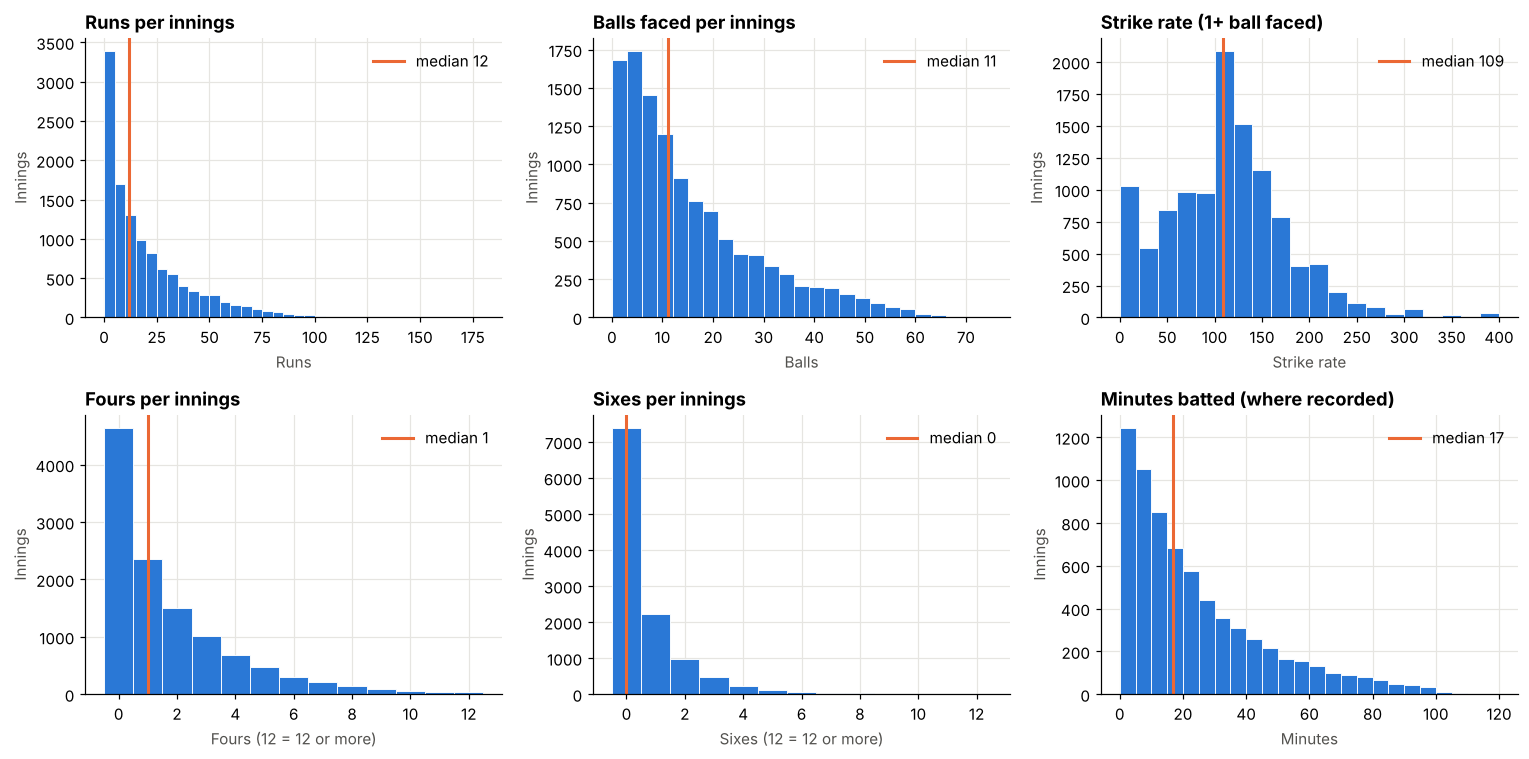

In [36]:
# How are runs, balls, strike rate, fours and sixes distributed?

def hist_panel(ax, series, bins, title, xlabel, cap=None):

    s = pd.to_numeric(series, errors="coerce").dropna().astype(float)

    if cap is not None:
        s = s.clip(upper=cap)

    ax.hist(s, bins=bins, color=BLUE, edgecolor="white", linewidth=0.6)
    ax.axvline(s.median(), color=ORANGE, lw=2, label=f"median {s.median():.0f}")
    ax.legend(frameon=False, loc="upper right")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Innings")

sr_view = faced.loc[faced["SR"] <= 400, "SR"]

above_400 = faced[faced["SR"] > 400]

print(f"Strike-rate panel hides {len(above_400)} innings above 400 (none lasted more than {above_400['B'].max()} balls).")

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
hist_panel(axes[0, 0], ipl_cricket["R"], np.arange(0, 181, 5), "Runs per innings", "Runs")
hist_panel(axes[0, 1], ipl_cricket["B"], np.arange(0, 76, 3), "Balls faced per innings", "Balls")
hist_panel(axes[0, 2], sr_view, np.arange(0, 401, 20), "Strike rate (1+ ball faced)", "Strike rate")
hist_panel(axes[1, 0], ipl_cricket["fours"], np.arange(-0.5, 12.6, 1), "Fours per innings", "Fours (12 = 12 or more)", cap=12)
hist_panel(axes[1, 1], ipl_cricket["sixes"], np.arange(-0.5, 12.6, 1), "Sixes per innings", "Sixes (12 = 12 or more)", cap=12)
hist_panel(axes[1, 2], ipl_cricket["M"], np.arange(0, 121, 5), "Minutes batted (where recorded)", "Minutes")
plt.tight_layout()
plt.show()

,matches,runs_per_match,fours_per_match,sixes_per_match
season,,,,
2008,58,289.8,29.4,10.7
2009,57,269.2,23.1,8.9
2010,60,295.6,28.5,9.8
2011,73,273.0,26.2,8.8
2012,74,288.1,25.8,9.9
2013,76,281.9,27.0,8.8
2014,60,298.7,26.0,11.9
2015,59,295.1,27.2,11.7
2016,60,299.4,27.2,10.6


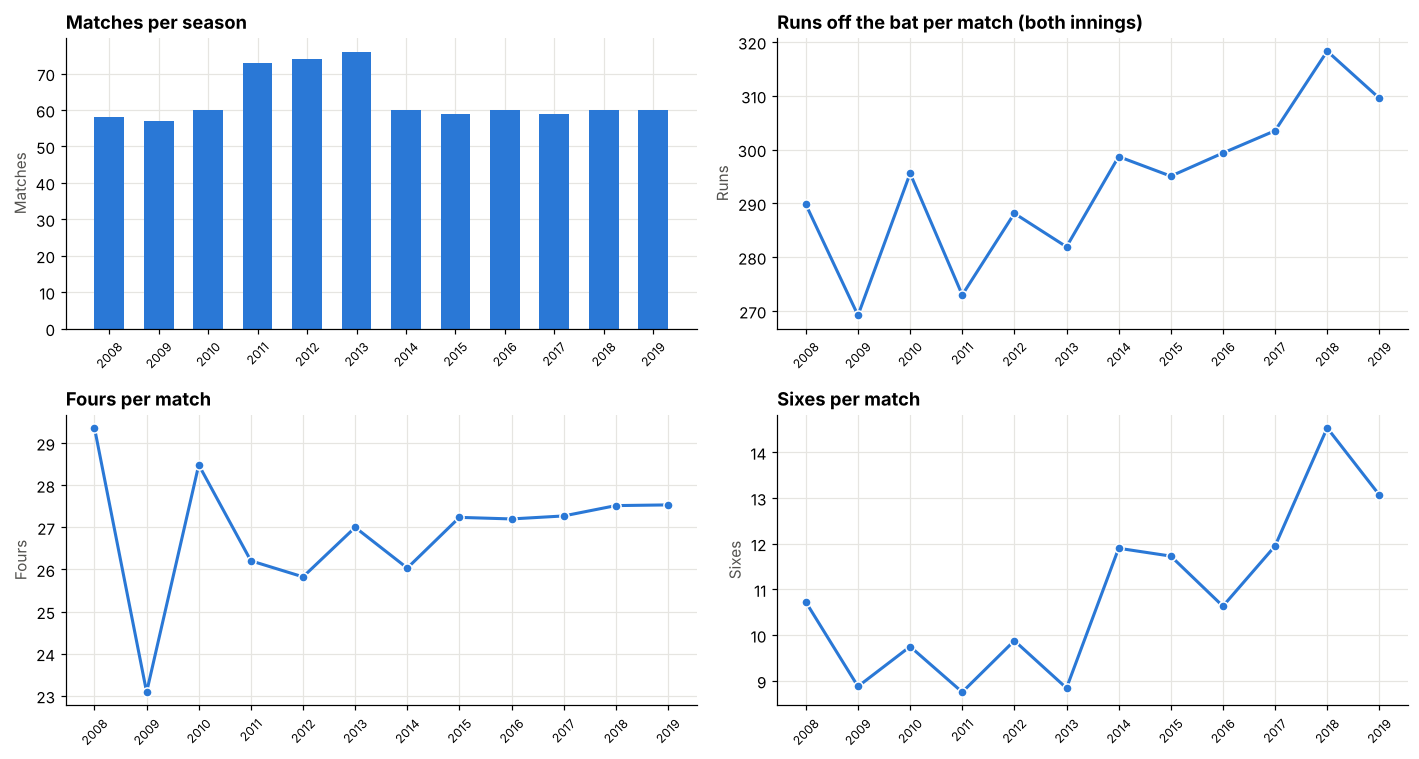

In [37]:
# How has scoring changed from season to season?

match_totals = (ipl_cricket.groupby(["season", "match_id"])
                  .agg(runs=("R", "sum"), fours=("fours", "sum"), sixes=("sixes", "sum"))
                  .reset_index())

season_stats = match_totals.groupby("season").agg(
    matches=("match_id", "nunique"),
    runs_per_match=("runs", "mean"),
    fours_per_match=("fours", "mean"),
    sixes_per_match=("sixes", "mean"),
)

display(season_stats.round(1))

x = season_stats.index.to_numpy(dtype=int)

fig, axes = plt.subplots(2, 2, figsize=(13, 7))

axes[0, 0].bar(x, season_stats["matches"], color=BLUE, width=0.6)
axes[0, 0].set_title("Matches per season")
axes[0, 0].set_ylabel("Matches")

for ax, col, title, ylab in [
    (axes[0, 1], "runs_per_match", "Runs off the bat per match (both innings)", "Runs"),
    (axes[1, 0], "fours_per_match", "Fours per match", "Fours"),
    (axes[1, 1], "sixes_per_match", "Sixes per match", "Sixes"),
]:
    ax.plot(x, season_stats[col], color=BLUE, lw=2, marker="o", ms=6, mfc=BLUE, mec="white")
    ax.set_title(title)
    ax.set_ylabel(ylab)

for ax in axes.ravel():
    ax.set_xticks(x)
    ax.tick_params(axis="x", labelsize=8, rotation=45)

plt.tight_layout()

plt.show()

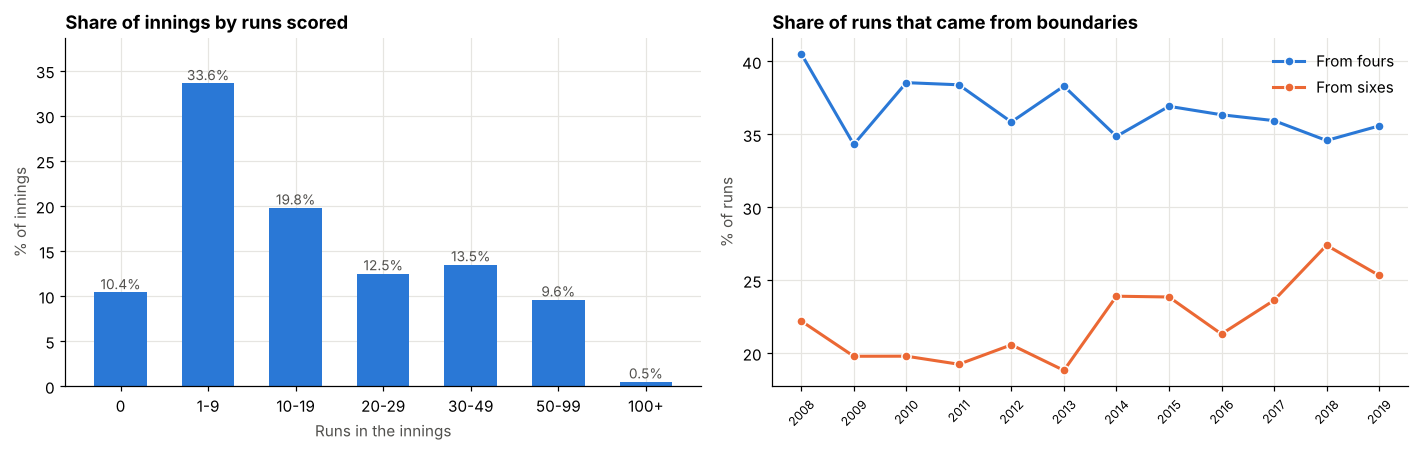

In [38]:
# How are runs made? Size of innings, and how much of the scoring comes from boundaries

bands = pd.cut(ipl_cricket["R"], bins=[-1, 0, 9, 19, 29, 49, 99, 500],
               labels=["0", "1-9", "10-19", "20-29", "30-49", "50-99", "100+"])

band_share = (bands.value_counts(normalize=True).sort_index() * 100).round(1)

ipl_cricket["runs_from_fours"] = ipl_cricket["fours"] * 4

ipl_cricket["runs_from_sixes"] = ipl_cricket["sixes"] * 6

season_runs = ipl_cricket.groupby("season")[["R", "runs_from_fours", "runs_from_sixes"]].sum()

share_fours = season_runs["runs_from_fours"] / season_runs["R"] * 100

share_sixes = season_runs["runs_from_sixes"] / season_runs["R"] * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

bars = axes[0].bar(band_share.index.astype(str), band_share.values, color=BLUE, width=0.6)

axes[0].bar_label(bars, fmt="%.1f%%", fontsize=9, color=INK)
axes[0].set_title("Share of innings by runs scored")
axes[0].set_xlabel("Runs in the innings")
axes[0].set_ylabel("% of innings")
axes[0].set_ylim(0, band_share.max() * 1.15)

xs = share_fours.index.to_numpy(dtype=int)

axes[1].plot(xs, share_fours.values, color=BLUE, lw=2, marker="o", ms=6, mfc=BLUE, mec="white", label="From fours")
axes[1].plot(xs, share_sixes.values, color=ORANGE, lw=2, marker="o", ms=6, mfc=ORANGE, mec="white", label="From sixes")
axes[1].set_title("Share of runs that came from boundaries")
axes[1].set_ylabel("% of runs")
axes[1].set_xticks(xs)
axes[1].tick_params(axis="x", labelsize=8, rotation=45)
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

ipl_cricket = ipl_cricket.drop(columns=["runs_from_fours", "runs_from_sixes"])

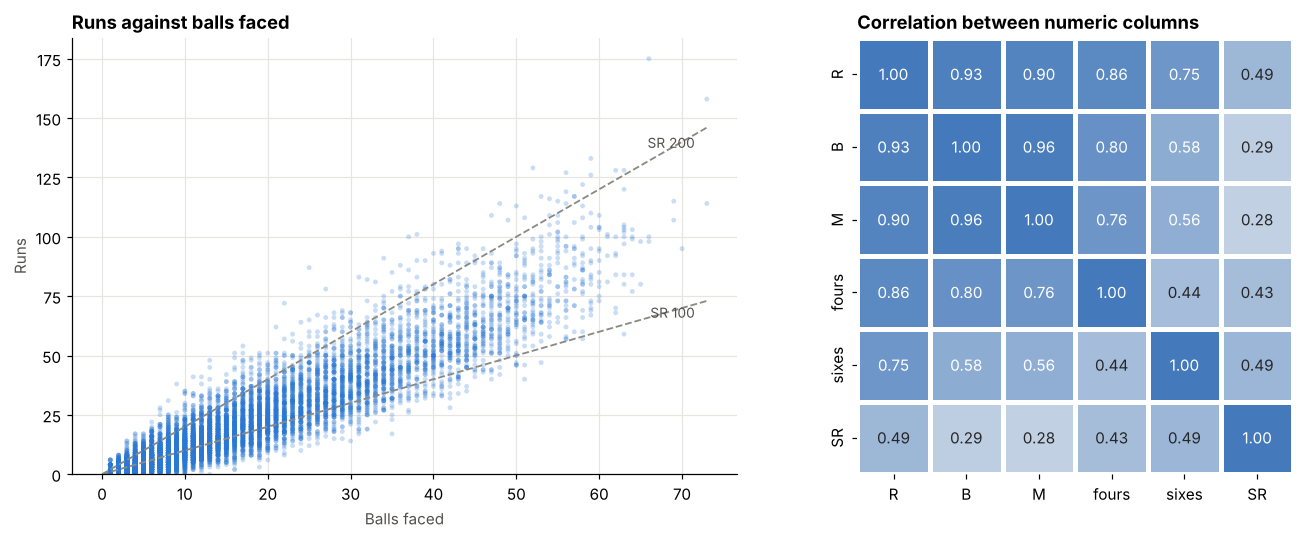

In [39]:
# How do runs, balls and strike rate relate?

corr = ipl_cricket[["R", "B", "M", "fours", "sixes", "SR"]].astype(float).corr()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(faced["B"], faced["R"], s=10, alpha=0.25, color=BLUE, edgecolors="none")

top = faced["B"].max()

for rate, name in [(1, "SR 100"), (2, "SR 200")]:
    axes[0].plot([0, top], [0, top * rate], color=GREY, lw=1.2, ls="--")
    axes[0].text(top * 0.98, min(top * rate, faced["R"].max()) * 0.98, name, color=INK, fontsize=9, ha="right", va="top")

axes[0].set_title("Runs against balls faced")
axes[0].set_xlabel("Balls faced")

axes[0].set_ylabel("Runs")
axes[0].set_ylim(0, faced["R"].max() * 1.05)

sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.diverging_palette(25, 250, as_cmap=True),
            center=0, vmin=-1, vmax=1, square=True, cbar=False, linewidths=2, linecolor="white",
            ax=axes[1])

axes[1].set_title("Correlation between numeric columns")
axes[1].grid(False)

plt.tight_layout()
plt.show()

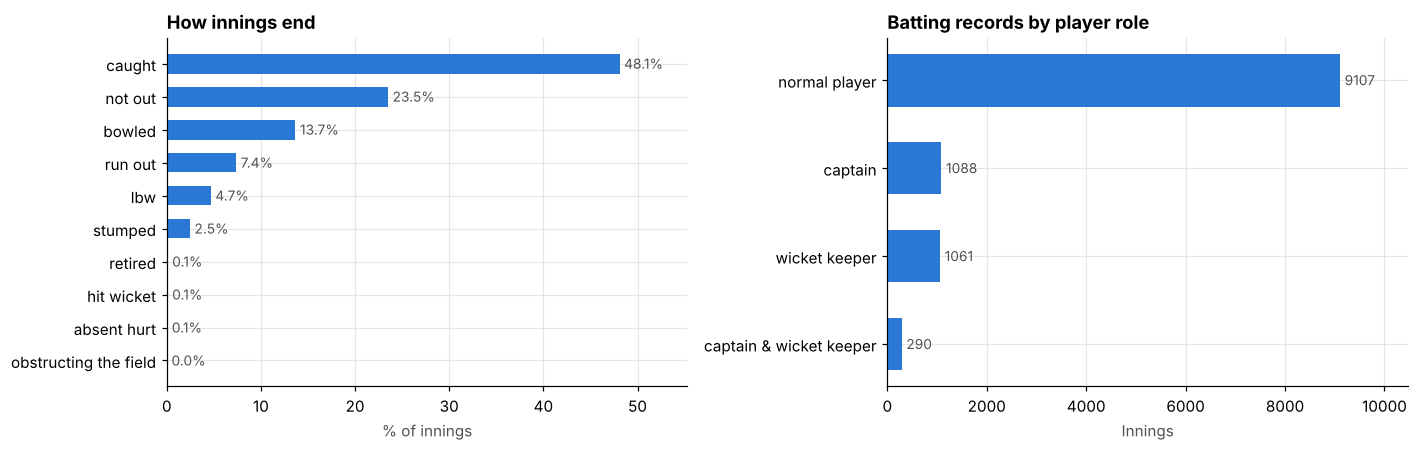

In [40]:
# Who bats, and how do innings end?

dismissal_share = (ipl_cricket["dismissal_mode"].value_counts(normalize=True) * 100).sort_values()

role_counts = ipl_cricket["special_role"].value_counts().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

bars = axes[0].barh(dismissal_share.index, dismissal_share.values, color=BLUE, height=0.6)

axes[0].bar_label(bars, fmt="%.1f%%", fontsize=9, color=INK, padding=3)
axes[0].set_title("How innings end")
axes[0].set_xlabel("% of innings")
axes[0].set_xlim(0, dismissal_share.max() * 1.15)

bars = axes[1].barh(role_counts.index, role_counts.values, color=BLUE, height=0.6)

axes[1].bar_label(bars, fmt="%d", fontsize=9, color=INK, padding=3)
axes[1].set_title("Batting records by player role")
axes[1].set_xlabel("Innings")
axes[1].set_xlim(0, role_counts.max() * 1.15)

plt.tight_layout()
plt.show()

In [41]:
# Key facts from the EDA (calculated from the data, so they update if the data changes)

first, last = season_stats.index.min(), season_stats.index.max()

print(f"Data covers {len(ipl_cricket):,} batting records, {ipl_cricket['match_id'].nunique()} matches, {ipl_cricket['season'].nunique()} seasons ({first}-{last}).")

print(f"Typical innings: median {ipl_cricket['R'].median():.0f} runs off {ipl_cricket['B'].median():.0f} balls (mean {ipl_cricket['R'].mean():.1f} runs).")

print(f"{(ipl_cricket['R'] < 10).mean() * 100:.1f}% of innings end below 10 runs; {(ipl_cricket['R'] >= 50).mean() * 100:.1f}% reach 50; {(ipl_cricket['R'] >= 100).sum()} innings reach 100.")

print(f"Median strike rate (1+ ball faced): {faced['SR'].median():.1f}.")

print(f"Sixes per match: {season_stats.loc[first, 'sixes_per_match']:.1f} in {first} vs {season_stats.loc[last, 'sixes_per_match']:.1f} in {last}.")

print(f"Runs off the bat per match: {season_stats.loc[first, 'runs_per_match']:.0f} in {first} vs {season_stats.loc[last, 'runs_per_match']:.0f} in {last}.")

print(f"{(ipl_cricket['dismissal_mode'] == 'not out').mean() * 100:.1f}% of innings end not out; the most common dismissal is '{ipl_cricket.loc[ipl_cricket['dismissal_mode'] != 'not out', 'dismissal_mode'].mode()[0]}'.")

print(f"Correlation of runs with balls faced: {corr.loc['R', 'B']:.2f}; with sixes: {corr.loc['R', 'sixes']:.2f}; with fours: {corr.loc['R', 'fours']:.2f}.")

Data covers 11,546 batting records, 756 matches, 12 seasons (2008-2019).
Typical innings: median 12 runs off 11 balls (mean 19.2 runs).
44.0% of innings end below 10 runs; 10.1% reach 50; 58 innings reach 100.
Median strike rate (1+ ball faced): 109.1.
Sixes per match: 10.7 in 2008 vs 13.1 in 2019.
Runs off the bat per match: 290 in 2008 vs 310 in 2019.
23.5% of innings end not out; the most common dismissal is 'caught'.
Correlation of runs with balls faced: 0.93; with sixes: 0.75; with fours: 0.86.


In [42]:
# 'bat' (the batting table used in Objectives 2 and 3) was built before cleaning, so it still has no season for the one undated match.
# Copy the cleaned season across (cleaning fills it in) and refresh the season counts that were calculated earlier.
same_rows = (ipl_cricket.loc[bat.index, "batsmen"].values == bat["batsmen"].values).all() and (ipl_cricket.loc[bat.index, "R"].values == bat["R"].values).all()
assert same_rows, "bat and the cleaned table no longer line up row by row"
bat["season"] = ipl_cricket.loc[bat.index, "season"].astype(int)
players["seasons"] = bat.groupby("batsmen")["season"].nunique()
qualified["seasons"] = players.loc[qualified.index, "seasons"]
print(f"Season is now filled for all {len(bat):,} innings.")

Season is now filled for all 11,540 innings.


# Objective 2: Analyse Player Performance

,innings,not_outs,runs,highest,average,strike_rate,fifties,hundreds,fours,sixes
batsmen,,,,,,,,,,
V Kohli,169,26,5412.0,113.0,37.8,131.6,36,5,480.0,190.0
SK Raina,189,28,5368.0,100.0,33.3,137.1,38,1,493.0,194.0
RG Sharma,183,28,4898.0,109.0,31.6,130.8,36,1,431.0,194.0
DA Warner,126,17,4706.0,126.0,43.2,142.4,44,4,458.0,181.0
S Dhawan,158,21,4579.0,97.0,33.4,124.8,37,0,524.0,96.0
CH Gayle,124,15,4484.0,175.0,41.1,151.0,28,6,368.0,326.0
MS Dhoni,170,65,4432.0,84.0,42.2,137.9,23,0,297.0,209.0
RV Uthappa,170,17,4411.0,87.0,28.8,130.5,24,0,435.0,156.0
AB de Villiers,142,32,4395.0,133.0,40.0,151.2,33,3,357.0,212.0


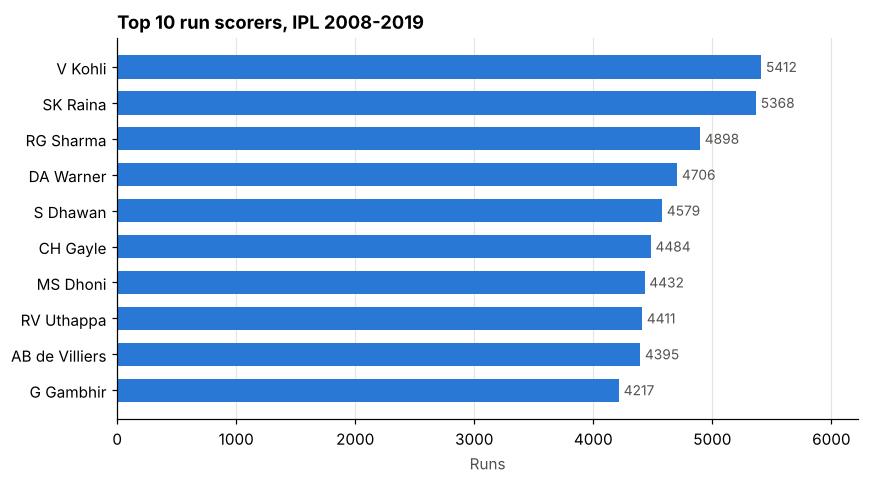

In [43]:
# Top 10 run scorers of all time (2008-2019)

cols = ["innings", "not_outs", "runs", "highest", "average", "strike_rate", "fifties", "hundreds", "fours", "sixes"]
top10 = players.sort_values("runs", ascending=False).head(10)
display(top10[cols].round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
hbar(ax, top10.index, top10["runs"], "Top 10 run scorers, IPL 2008-2019", "Runs")
plt.tight_layout()
plt.show()

,batsmen,runs,innings
season,,,
2008,SE Marsh,616.0,11
2009,ML Hayden,572.0,12
2010,SR Tendulkar,618.0,15
2011,CH Gayle,608.0,12
2012,CH Gayle,733.0,14
2013,MEK Hussey,733.0,17
2014,RV Uthappa,660.0,16
2015,DA Warner,562.0,14
2016,V Kohli,973.0,16


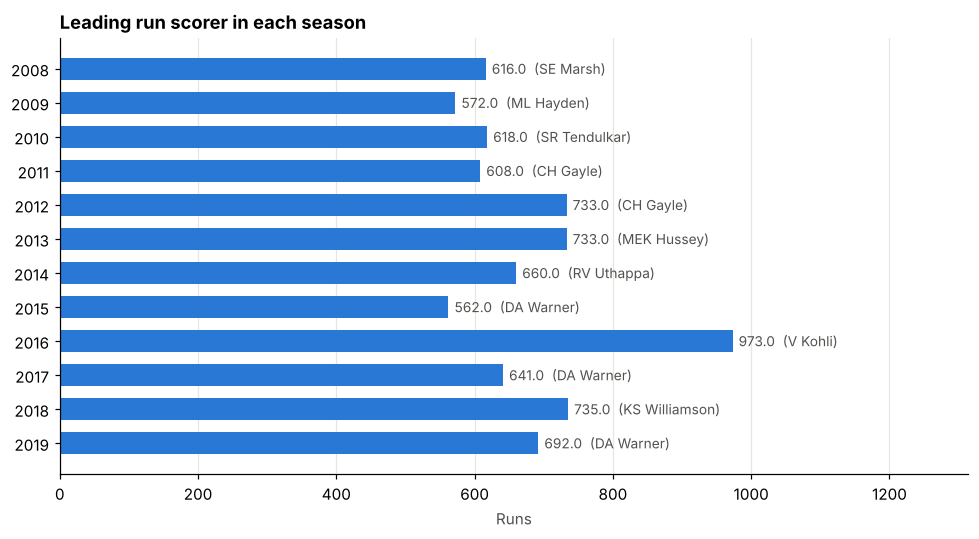

In [44]:
# Top run scorer of every season (the 'Orange Cap')

season_runs = bat.groupby(["season", "batsmen"]).agg(runs=("R", "sum"), innings=("R", "size")).reset_index()
orange_cap = (season_runs.sort_values(["season", "runs"], ascending=[True, False])
                         .groupby("season").head(1).set_index("season"))
display(orange_cap)

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(orange_cap))
bars = ax.barh(y, orange_cap["runs"], color=BLUE, height=0.65)
ax.set_yticks(y)
ax.set_yticklabels(orange_cap.index)
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{r}  ({n})" for r, n in zip(orange_cap["runs"], orange_cap["batsmen"])],
             padding=4, fontsize=9, color=INK)
ax.set_xlim(0, orange_cap["runs"].max() * 1.35)
ax.set_title("Leading run scorer in each season")
ax.set_xlabel("Runs")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Top  10 batters scored 21.2% of all runs
Top  25 batters scored 41.2% of all runs
Top  50 batters scored 61.5% of all runs
Top 100 batters scored 82.6% of all runs

Runs per season, top 5 run scorers (blank = did not play that season):


batsmen,V Kohli,SK Raina,RG Sharma,DA Warner,S Dhawan
season,,,,,
2008,165.0,421.0,404.0,NaN,340.0
2009,246.0,434.0,362.0,163.0,40.0
2010,307.0,520.0,404.0,282.0,191.0
2011,557.0,438.0,372.0,324.0,400.0
2012,364.0,441.0,433.0,256.0,569.0
2013,634.0,548.0,538.0,410.0,311.0
2014,359.0,523.0,390.0,528.0,377.0
2015,505.0,374.0,482.0,562.0,353.0
2016,973.0,399.0,489.0,848.0,501.0


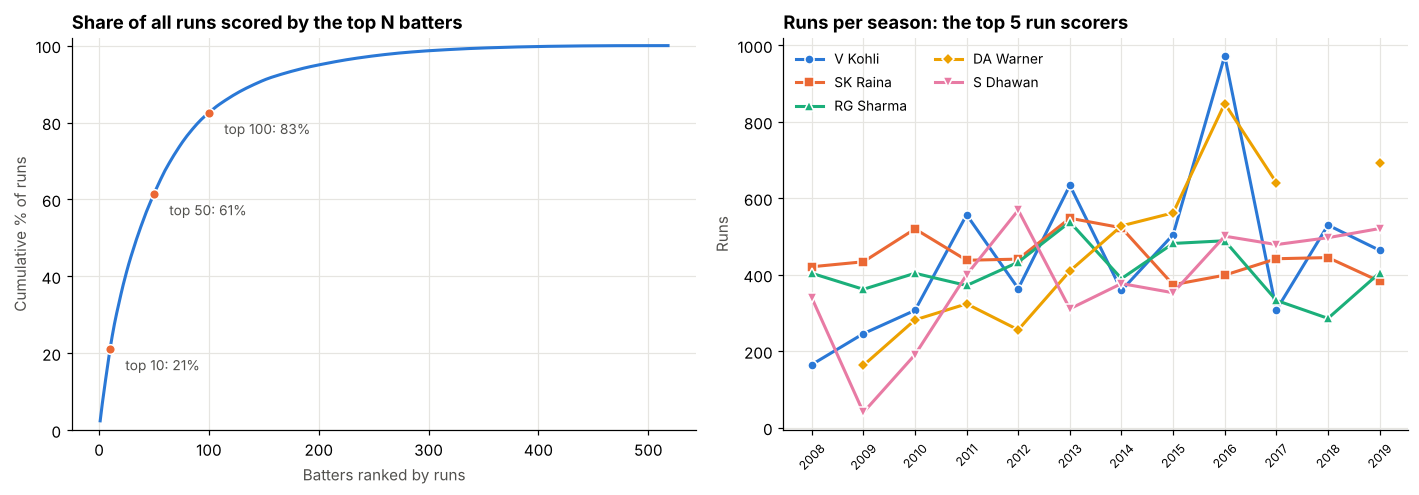

In [45]:
# How concentrated is scoring? And how did the top 5 score season by season?

ranked = players["runs"].sort_values(ascending=False)
cum_share = ranked.cumsum() / ranked.sum() * 100
for n in (10, 25, 50, 100):
    print(f"Top {n:>3} batters scored {cum_share.iloc[n - 1]:.1f}% of all runs")

top5 = list(top10.index[:5])
season_pivot = (season_runs[season_runs["batsmen"].isin(top5)]
                .pivot(index="season", columns="batsmen", values="runs")[top5])
print("\nRuns per season, top 5 run scorers (blank = did not play that season):")
display(season_pivot)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

axes[0].plot(np.arange(1, len(cum_share) + 1), cum_share.values, color=BLUE, lw=2)

for n in (10, 50, 100):
    axes[0].scatter(n, cum_share.iloc[n - 1], color=ORANGE, s=40, zorder=3, edgecolor="white")
    axes[0].annotate(f"top {n}: {cum_share.iloc[n - 1]:.0f}%", (n, cum_share.iloc[n - 1]),
                     textcoords="offset points", xytext=(10, -14), fontsize=9, color=INK)
axes[0].set_title("Share of all runs scored by the top N batters")
axes[0].set_xlabel("Batters ranked by runs")
axes[0].set_ylabel("Cumulative % of runs")
axes[0].set_ylim(0, 102)

markers = ["o", "s", "^", "D", "v"]

for name, color, marker in zip(top5, SERIES, markers):
    axes[1].plot(season_pivot.index, season_pivot[name], color=color, lw=2, marker=marker, ms=6,
                 mec="white", label=name)
axes[1].set_title("Runs per season: the top 5 run scorers")
axes[1].set_ylabel("Runs")
axes[1].set_xticks(season_pivot.index)
axes[1].tick_params(axis="x", labelsize=8, rotation=45)
axes[1].legend(frameon=False, fontsize=9, ncol=2)
plt.tight_layout()
plt.show()

In [46]:
# Biggest individual innings, and who reaches 50 and 100 most often

best_innings = bat.nlargest(10, "R")[["season", "batsmen", "R", "B", "fours", "sixes", "SR", "team_1", "team_2"]]
best_innings.index = range(1, 11)
print("10 highest individual scores:")
display(best_innings)

print("Most 50s and 100s:")
milestones = players.assign(fifty_plus=players["fifties"] + players["hundreds"])
display(milestones.sort_values(["fifty_plus", "hundreds"], ascending=False).head(10)
        [["innings", "fifties", "hundreds", "fifty_plus"]])

print(f"{(bat['R'] >= 50).sum()} scores of 50+ in {len(bat):,} innings ({(bat['R'] >= 50).mean() * 100:.1f}%); "
      f"{(bat['R'] >= 100).sum()} hundreds ({(bat['R'] >= 100).mean() * 100:.2f}%).")

10 highest individual scores:


,season,batsmen,R,B,fours,sixes,SR,team_1,team_2
1,2013,CH Gayle,175.0,66.0,13.0,17.0,265.15,Royal Challengers Bangalore,Pune Warriors
2,2008,BB McCullum,158.0,73.0,10.0,13.0,216.43,Kolkata Knight Riders,Royal Challengers Bangalore
3,2015,AB de Villiers,133.0,59.0,19.0,4.0,225.42,Royal Challengers Bangalore,Mumbai Indians
4,2016,AB de Villiers,129.0,52.0,10.0,12.0,248.07,Royal Challengers Bangalore,Gujarat Lions
5,2012,CH Gayle,128.0,62.0,7.0,13.0,206.45,Royal Challengers Bangalore,Delhi Daredevils
6,2018,RR Pant,128.0,63.0,15.0,7.0,203.17,Delhi Daredevils,Sunrisers Hyderabad
7,2010,M Vijay,127.0,56.0,8.0,11.0,226.78,Chennai Super Kings,Rajasthan Royals
8,2017,DA Warner,126.0,59.0,10.0,8.0,213.55,Sunrisers Hyderabad,Kolkata Knight Riders
9,2014,V Sehwag,122.0,58.0,12.0,8.0,210.34,Kings XI Punjab,Chennai Super Kings
10,2011,PC Valthaty,120.0,63.0,19.0,2.0,190.47,Chennai Super Kings,Kings XI Punjab


Most 50s and 100s:


,innings,fifties,hundreds,fifty_plus
batsmen,,,,
DA Warner,126,44,4,48
V Kohli,169,36,5,41
SK Raina,189,38,1,39
RG Sharma,183,36,1,37
S Dhawan,158,37,0,37
AB de Villiers,142,33,3,36
G Gambhir,152,36,0,36
CH Gayle,124,28,6,34
AM Rahane,132,27,2,29


1171 scores of 50+ in 11,540 innings (10.1%); 58 hundreds (0.50%).


# Task 2: Compare scoring efficiency and strike rate

In [47]:
# Why aggregated strike rate: compare the two ways of calculating it for the whole league?

faced = bat[bat["B"] > 0]
print(f"Mean of the per-innings SR column : {faced['SR'].mean():.1f}")
print(f"Total runs / total balls x 100    : {faced['R'].sum() / faced['B'].sum() * 100:.1f}")

Mean of the per-innings SR column : 110.6
Total runs / total balls x 100    : 127.6



Qualified batters (>= 500 balls): 92
Top 10 strike rates:


,innings,runs,balls,strike_rate,average
batsmen,,,,,
AD Russell,52,1400.0,751.0,186.4,33.3
RR Pant,54,1736.0,1067.0,162.7,36.2
GJ Maxwell,68,1397.0,867.0,161.1,22.9
V Sehwag,104,2728.0,1755.0,155.4,27.6
HH Pandya,61,1068.0,690.0,154.8,28.9
AB de Villiers,142,4395.0,2906.0,151.2,40.0
CH Gayle,124,4484.0,2969.0,151.0,41.1
JC Buttler,45,1386.0,919.0,150.8,35.5
KA Pollard,135,2755.0,1877.0,146.8,28.7


Top 10 batting averages:


,innings,runs,dismissals,average,strike_rate
batsmen,,,,,
DA Warner,126,4706.0,109,43.2,142.4
MS Dhoni,170,4432.0,105,42.2,137.9
KL Rahul,58,1977.0,47,42.1,138.2
CH Gayle,124,4484.0,109,41.1,151.0
LMP Simmons,29,1079.0,27,40.0,126.6
AB de Villiers,142,4395.0,110,40.0,151.2
SE Marsh,69,2477.0,62,40.0,132.7
JP Duminy,77,2029.0,51,39.8,124.0
MEK Hussey,58,1977.0,51,38.8,122.6


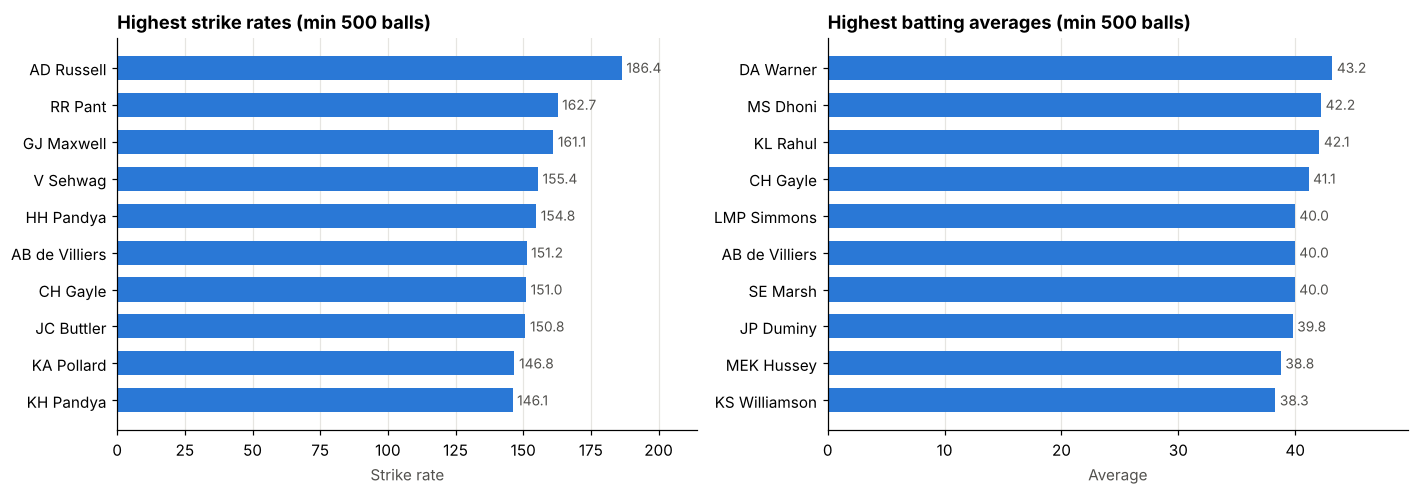

In [48]:
# Fastest scorers and best averages (qualified batters only)

top_sr = qualified.sort_values("strike_rate", ascending=False).head(10)
top_avg = qualified.sort_values("average", ascending=False).head(10)
print(f"\nQualified batters (>= {MIN_BALLS} balls): {len(qualified)}")
print("Top 10 strike rates:")
display(top_sr[["innings", "runs", "balls", "strike_rate", "average"]].round(1))
print("Top 10 batting averages:")
display(top_avg[["innings", "runs", "dismissals", "average", "strike_rate"]].round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
hbar(axes[0], top_sr.index, top_sr["strike_rate"], f"Highest strike rates (min {MIN_BALLS} balls)", "Strike rate", fmt="%.1f")
hbar(axes[1], top_avg.index, top_avg["average"], f"Highest batting averages (min {MIN_BALLS} balls)", "Average", fmt="%.1f")
plt.tight_layout()
plt.show()

Cut-offs (median of qualified batters): average 28.3, strike rate 128.4


,batters
style,
Fast and consistent,27
Below median on both,27
Fast but less consistent,19
Steady but slower,19


Fast and consistent batters (most runs first):


,innings,runs,average,strike_rate
batsmen,,,,
V Kohli,169,5412.0,37.8,131.6
SK Raina,189,5368.0,33.3,137.1
RG Sharma,183,4898.0,31.6,130.8
DA Warner,126,4706.0,43.2,142.4
CH Gayle,124,4484.0,41.1,151.0
MS Dhoni,170,4432.0,42.2,137.9
RV Uthappa,170,4411.0,28.8,130.5
AB de Villiers,142,4395.0,40.0,151.2
SR Watson,130,3575.0,31.1,139.5


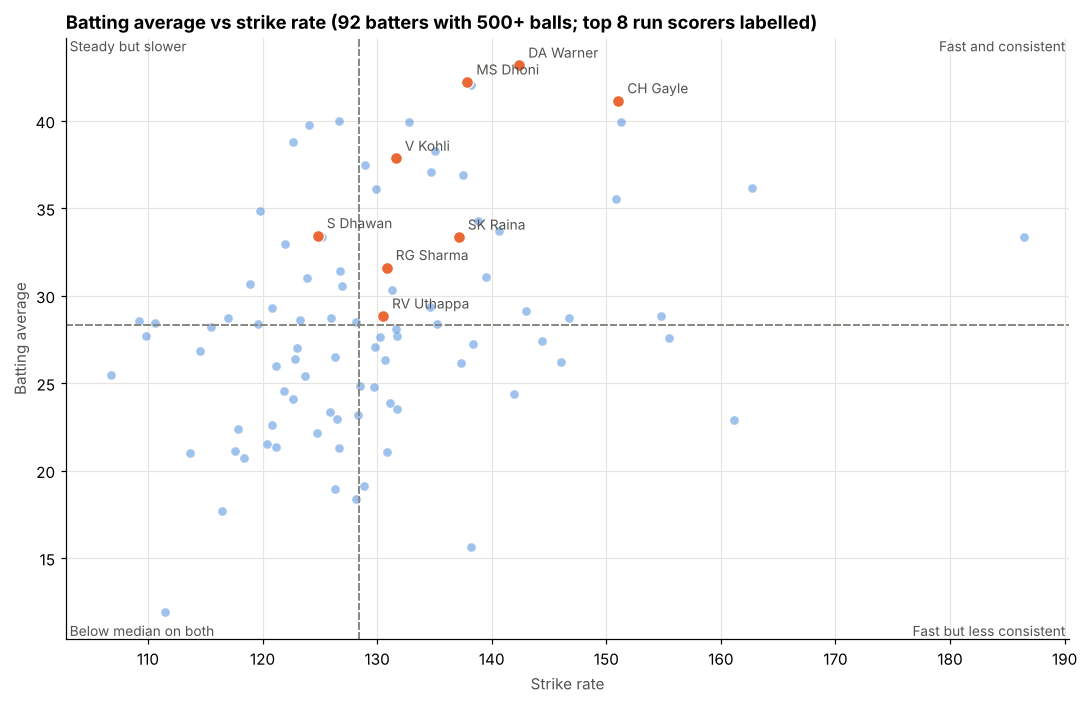

In [49]:
# Efficiency map: batting average (consistency) against strike rate (speed)

avg_cut, sr_cut = qualified["average"].median(), qualified["strike_rate"].median()

qualified["style"] = np.select(
    [(qualified["average"] >= avg_cut) & (qualified["strike_rate"] >= sr_cut),
     (qualified["average"] < avg_cut) & (qualified["strike_rate"] >= sr_cut),
     (qualified["average"] >= avg_cut) & (qualified["strike_rate"] < sr_cut)],
    ["Fast and consistent", "Fast but less consistent", "Steady but slower"],
    default="Below median on both")

print(f"Cut-offs (median of qualified batters): average {avg_cut:.1f}, strike rate {sr_cut:.1f}")

display(qualified["style"].value_counts().rename("batters").to_frame())

best_both = qualified[qualified["style"] == "Fast and consistent"].sort_values("runs", ascending=False)

print("Fast and consistent batters (most runs first):")

display(best_both[["innings", "runs", "average", "strike_rate"]].head(12).round(1))

label_names = list(qualified.sort_values("runs", ascending=False).index[:8])

fig, ax = plt.subplots(figsize=(10, 6.5))

rest = qualified.drop(label_names)

ax.scatter(rest["strike_rate"], rest["average"], s=35, color=BLUE, alpha=0.45, edgecolor="white", linewidth=0.5)

lab = qualified.loc[label_names]

ax.scatter(lab["strike_rate"], lab["average"], s=60, color=ORANGE, edgecolor="white", linewidth=0.8, zorder=3)

for name, r in lab.iterrows():
    ax.annotate(name, (r["strike_rate"], r["average"]), textcoords="offset points", xytext=(6, 5), fontsize=9, color=INK)
    ax.axvline(sr_cut, color=GREY, ls="--", lw=1.2)
    ax.axhline(avg_cut, color=GREY, ls="--", lw=1.2)

xl, yl = ax.get_xlim(), ax.get_ylim()
ax.text(xl[1], yl[1], "Fast and consistent ", ha="right", va="top", fontsize=9, color=INK)
ax.text(xl[1], yl[0], "Fast but less consistent ", ha="right", va="bottom", fontsize=9, color=INK)
ax.text(xl[0], yl[1], " Steady but slower", ha="left", va="top", fontsize=9, color=INK)
ax.text(xl[0], yl[0], " Below median on both", ha="left", va="bottom", fontsize=9, color=INK)
ax.set_xlim(xl)
ax.set_ylim(yl)
ax.set_title(f"Batting average vs strike rate ({len(qualified)} batters with {MIN_BALLS}+ balls; top 8 run scorers labelled)")
ax.set_xlabel("Strike rate")
ax.set_ylabel("Batting average")
plt.tight_layout()
plt.show()

,innings,runs,balls,strike_rate,share_of_innings_%
B,,,,,
1-5,3167,7725.0,8983.0,86.0,28.0
6-10,2274,19562.0,17901.0,109.3,20.1
11-20,2743,50935.0,41281.0,123.4,24.3
21-30,1452,47302.0,36453.0,129.8,12.9
31-40,848,39942.0,29617.0,134.9,7.5
41+,808,55971.0,39315.0,142.4,7.2


season,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
runs,16809.0,15344.0,17735.0,19928.0,21323.0,21427.0,17922.0,17409.0,17962.0,17907.0,19098.0,18573.0
balls,13032.0,13158.0,13991.0,16508.0,17270.0,17674.0,13888.0,13191.0,13667.0,13428.0,13847.0,13896.0
strike_rate,129.0,116.6,126.8,120.7,123.5,121.2,129.0,132.0,131.4,133.4,137.9,133.7


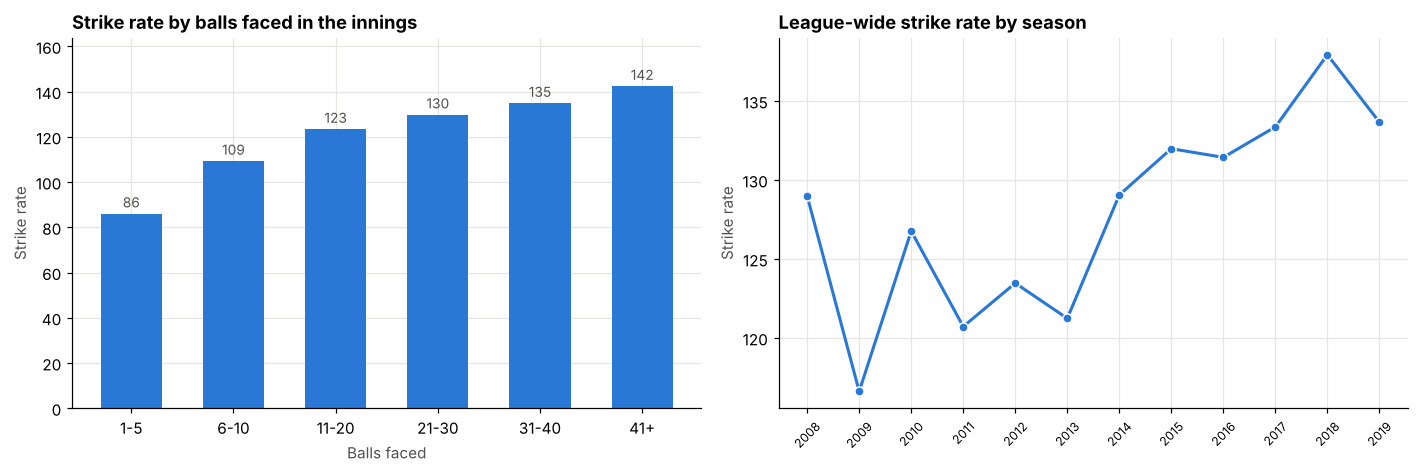

In [50]:
# How does scoring speed change with the length of the innings, and from season to season?

bands = pd.cut(faced["B"], bins=[0, 5, 10, 20, 30, 40, 100], labels=["1-5", "6-10", "11-20", "21-30", "31-40", "41+"])
by_band = faced.groupby(bands, observed=True).agg(innings=("R", "size"), runs=("R", "sum"), balls=("B", "sum"))
by_band["strike_rate"] = by_band["runs"] / by_band["balls"] * 100
by_band["share_of_innings_%"] = by_band["innings"] / by_band["innings"].sum() * 100
display(by_band.round(1))

season_sr = bat.groupby("season").agg(runs=("R", "sum"), balls=("B", "sum"))
season_sr["strike_rate"] = season_sr["runs"] / season_sr["balls"] * 100
display(season_sr.round(1).T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
bars = axes[0].bar(by_band.index.astype(str), by_band["strike_rate"], color=BLUE, width=0.6)
axes[0].bar_label(bars, fmt="%.0f", fontsize=9, color=INK, padding=2)
axes[0].set_title("Strike rate by balls faced in the innings")
axes[0].set_xlabel("Balls faced")
axes[0].set_ylabel("Strike rate")
axes[0].set_ylim(0, by_band["strike_rate"].max() * 1.15)

axes[1].plot(season_sr.index, season_sr["strike_rate"], color=BLUE, lw=2, marker="o", ms=6, mec="white")
axes[1].set_title("League-wide strike rate by season")
axes[1].set_ylabel("Strike rate")
axes[1].set_xticks(season_sr.index)
axes[1].tick_params(axis="x", labelsize=8, rotation=45)
plt.tight_layout()
plt.show()

# Task 3: Analyse fours and sixes

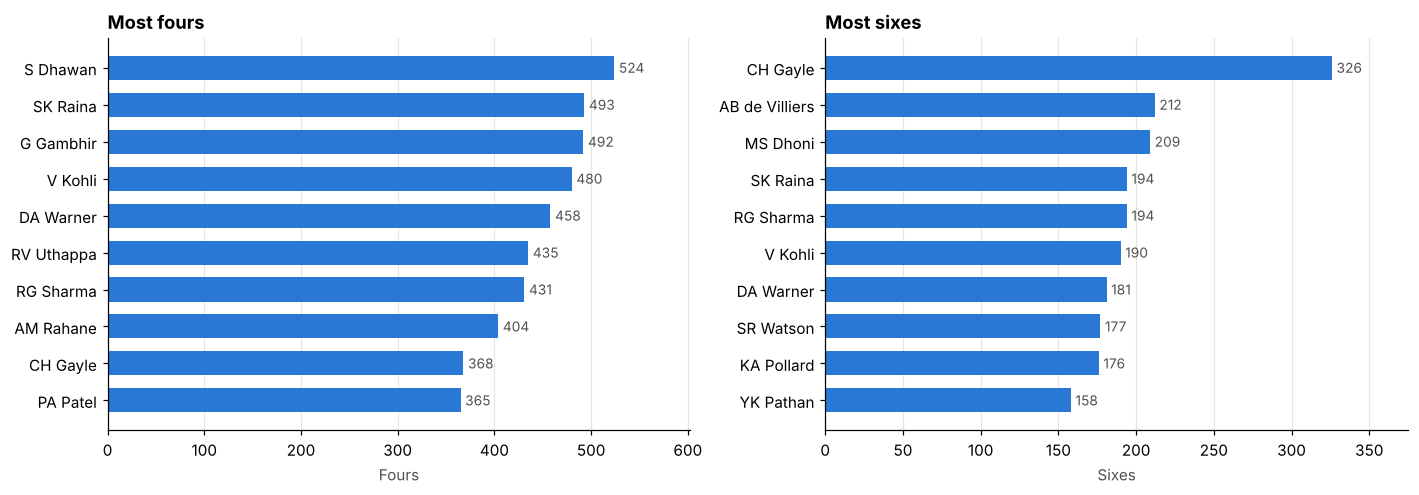

All batters: 20,317.0 fours and 8,160.0 sixes.
The 10 leading six hitters hit 24.7% of all sixes.


In [51]:
# Who hits the most fours and sixes?

top_fours = players.sort_values("fours", ascending=False).head(10)
top_sixes = players.sort_values("sixes", ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
hbar(axes[0], top_fours.index, top_fours["fours"], "Most fours", "Fours")
hbar(axes[1], top_sixes.index, top_sixes["sixes"], "Most sixes", "Sixes")
plt.tight_layout()
plt.show()

total_sixes = players["sixes"].sum()
print(f"All batters: {players['fours'].sum():,} fours and {total_sixes:,} sixes.")
print(f"The 10 leading six hitters hit {top_sixes['sixes'].sum() / total_sixes * 100:.1f}% of all sixes.")

Hit a six most often (fewest balls per six):


,balls,fours_per100,sixes_per100,balls_per_boundary,balls_per_six,boundary_pct
batsmen,,,,,,
AD Russell,751.0,12.8,16.0,3.5,6.3,78.9
CH Gayle,2969.0,12.4,11.0,4.3,9.1,76.4
GJ Maxwell,867.0,12.6,10.5,4.3,9.5,70.3
HH Pandya,690.0,10.4,9.9,4.9,10.1,65.2
KA Pollard,1877.0,9.6,9.4,5.3,10.7,64.6
RR Pant,1067.0,14.2,8.8,4.3,11.4,67.5
JA Morkel,686.0,8.9,8.0,5.9,12.5,58.9
N Rana,806.0,10.4,7.4,5.6,13.4,64.1
ST Jayasuriya,532.0,15.8,7.3,4.3,13.6,74.2


Hit a four most often (most fours per 100 balls):


,balls,fours_per100,sixes_per100,balls_per_boundary,balls_per_six,boundary_pct
batsmen,,,,,,
V Sehwag,1755.0,19.0,6.0,4.0,16.6,72.3
AC Gilchrist,1495.0,16.0,6.2,4.5,16.2,72.9
ST Jayasuriya,532.0,15.8,7.3,4.3,13.6,74.2
PA Patel,2358.0,15.5,2.1,5.7,48.1,61.6
JC Buttler,919.0,15.2,6.6,4.6,15.1,66.8
SR Tendulkar,1948.0,15.1,1.5,6.0,67.2,58.0
ML Hayden,805.0,15.0,5.5,4.9,18.3,67.6
G Gambhir,3404.0,14.5,1.7,6.2,57.7,55.1
S Dhawan,3669.0,14.3,2.6,5.9,38.2,58.4


Hit a boundary most often (fewest balls per four or six):


,balls,fours_per100,sixes_per100,balls_per_boundary,balls_per_six,boundary_pct
batsmen,,,,,,
AD Russell,751.0,12.8,16.0,3.5,6.3,78.9
V Sehwag,1755.0,19.0,6.0,4.0,16.6,72.3
CH Gayle,2969.0,12.4,11.0,4.3,9.1,76.4
ST Jayasuriya,532.0,15.8,7.3,4.3,13.6,74.2
GJ Maxwell,867.0,12.6,10.5,4.3,9.5,70.3
RR Pant,1067.0,14.2,8.8,4.3,11.4,67.5
AC Gilchrist,1495.0,16.0,6.2,4.5,16.2,72.9
JC Buttler,919.0,15.2,6.6,4.6,15.1,66.8
CA Lynn,910.0,14.1,6.9,4.8,14.4,69.5


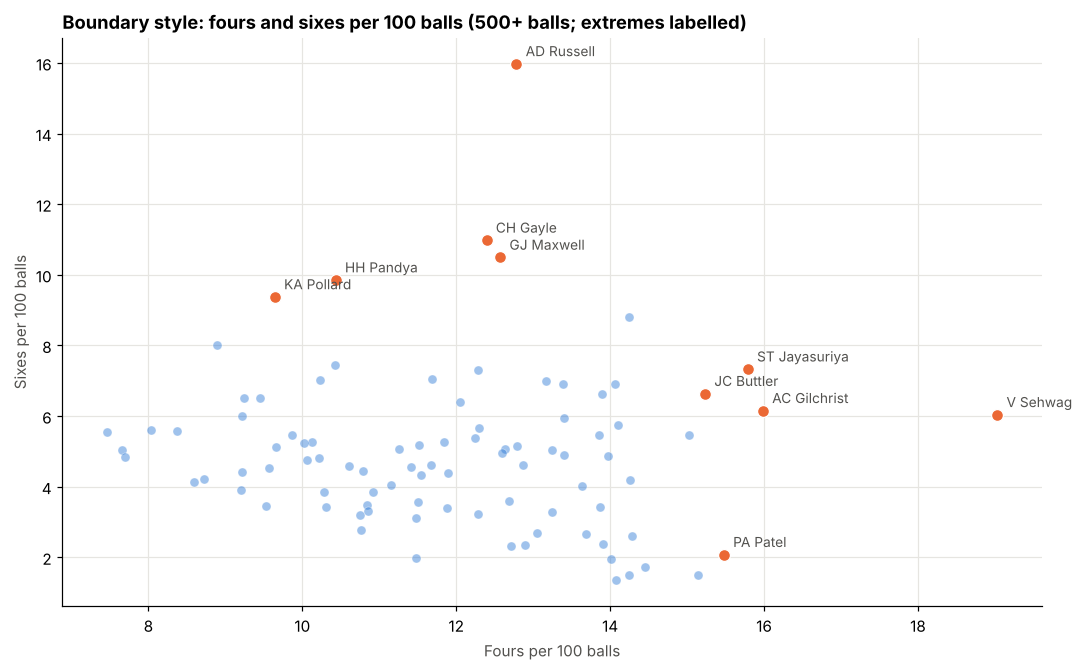

In [52]:
# Counts reward long careers, so also look at rates (batters with 500+ balls)

# balls_per_boundary: balls faced for each four or six. boundary_pct: share of the player's runs from fours and sixes.

rate_cols = ["balls", "fours_per100", "sixes_per100", "balls_per_boundary", "balls_per_six", "boundary_pct"]

print("Hit a six most often (fewest balls per six):")
display(qualified.sort_values("balls_per_six").head(10)[rate_cols].round(1))

print("Hit a four most often (most fours per 100 balls):")
display(qualified.sort_values("fours_per100", ascending=False).head(10)[rate_cols].round(1))

print("Hit a boundary most often (fewest balls per four or six):")
display(qualified.sort_values("balls_per_boundary").head(10)[rate_cols].round(1))

label_names = set(qualified.nlargest(5, "sixes_per100").index) | set(qualified.nlargest(5, "fours_per100").index)
fig, ax = plt.subplots(figsize=(10, 6.2))
rest = qualified.drop(list(label_names))
lab = qualified.loc[list(label_names)]
ax.scatter(rest["fours_per100"], rest["sixes_per100"], s=35, color=BLUE, alpha=0.45, edgecolor="white", linewidth=0.5)
ax.scatter(lab["fours_per100"], lab["sixes_per100"], s=60, color=ORANGE, edgecolor="white", linewidth=0.8, zorder=3)

for name, r in lab.iterrows():
    ax.annotate(name, (r["fours_per100"], r["sixes_per100"]), textcoords="offset points", xytext=(6, 5), fontsize=9, color=INK)
    ax.set_title("Boundary style: fours and sixes per 100 balls (500+ balls; extremes labelled)")
    ax.set_xlabel("Fours per 100 balls")
    ax.set_ylabel("Sixes per 100 balls")

plt.tight_layout()
plt.show()

Share of all runs: fours 36.7%, sixes 22.1%, running 41.2%


,Fours,Sixes,"Running (1s, 2s, 3s)"
band,,,
1-9,30.5,7.9,61.6
10-19,36.3,17.9,45.8
20-29,37.3,21.3,41.4
30-49,37.5,22.8,39.7
50-99,37.5,25.7,36.8
100+,35.0,37.0,28.0


season,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
fours,1703.0,1316.0,1709.0,1913.0,1911.0,2052.0,1562.0,1607.0,1632.0,1609.0,1651.0,1652.0
sixes,622.0,506.0,585.0,639.0,731.0,672.0,714.0,692.0,638.0,705.0,872.0,784.0
fours_per100,13.1,10.0,12.2,11.6,11.1,11.6,11.2,12.2,11.9,12.0,11.9,11.9
sixes_per100,4.8,3.8,4.2,3.9,4.2,3.8,5.1,5.2,4.7,5.3,6.3,5.6


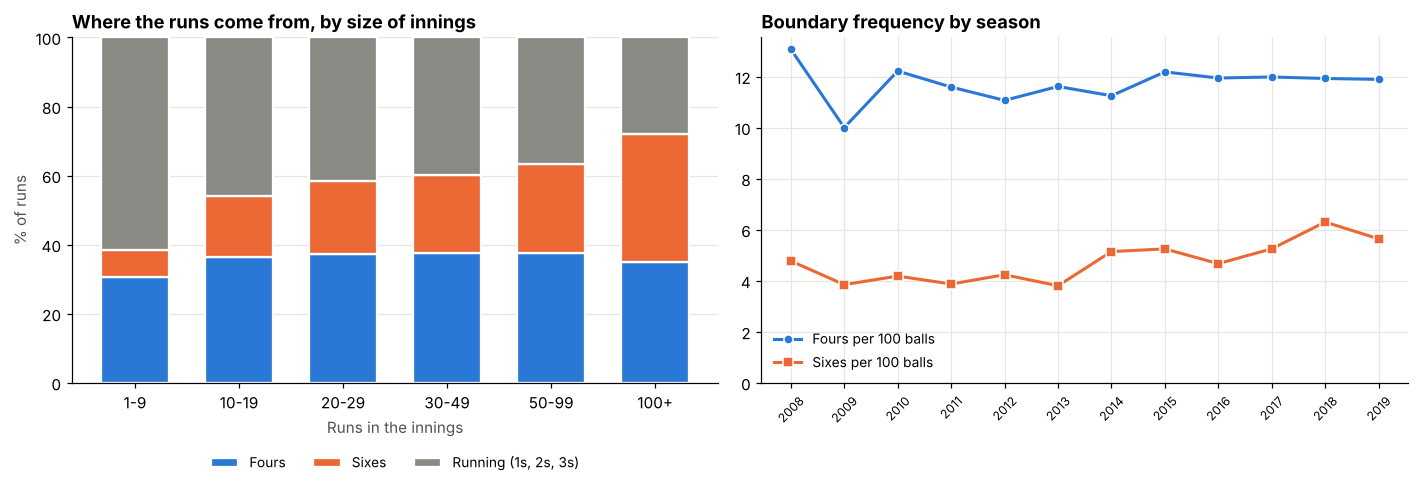

In [53]:
# Where do runs come from? Fours, sixes or running between the wickets, by size of innings

scoring = bat[bat["R"] > 0].copy()
scoring["from_fours"] = scoring["fours"] * 4
scoring["from_sixes"] = scoring["sixes"] * 6
scoring["from_running"] = scoring["R"] - scoring["from_fours"] - scoring["from_sixes"]
scoring["band"] = pd.cut(scoring["R"], bins=[0, 9, 19, 29, 49, 99, 500],
                         labels=["1-9", "10-19", "20-29", "30-49", "50-99", "100+"])

parts = scoring.groupby("band", observed=True)[["from_fours", "from_sixes", "from_running"]].sum()
share = parts.div(parts.sum(axis=1), axis=0) * 100
share.columns = ["Fours", "Sixes", "Running (1s, 2s, 3s)"]
overall = scoring[["from_fours", "from_sixes", "from_running"]].sum()
print("Share of all runs: " + ", ".join(f"{k} {v:.1f}%" for k, v in
      zip(["fours", "sixes", "running"], overall / overall.sum() * 100)))
display(share.round(1))

# Season view: fours and sixes per 100 balls

season_rates = bat.groupby("season")[["fours", "sixes", "B"]].sum()
season_rates["fours_per100"] = season_rates["fours"] / season_rates["B"] * 100
season_rates["sixes_per100"] = season_rates["sixes"] / season_rates["B"] * 100
display(season_rates[["fours", "sixes", "fours_per100", "sixes_per100"]].round(1).T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
bottom = np.zeros(len(share))

for col, color in zip(share.columns, [BLUE, ORANGE, GREY]):
    axes[0].bar(share.index.astype(str), share[col], bottom=bottom, color=color, width=0.65,
                edgecolor="white", linewidth=1.5, label=col)
    bottom += share[col].values

axes[0].set_title("Where the runs come from, by size of innings")
axes[0].set_xlabel("Runs in the innings")
axes[0].set_ylabel("% of runs")
axes[0].set_ylim(0, 100)
axes[0].legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3)

axes[1].plot(season_rates.index, season_rates["fours_per100"], color=BLUE, lw=2, marker="o", ms=6, mec="white", label="Fours per 100 balls")
axes[1].plot(season_rates.index, season_rates["sixes_per100"], color=ORANGE, lw=2, marker="s", ms=6, mec="white", label="Sixes per 100 balls")
axes[1].set_title("Boundary frequency by season")
axes[1].set_xticks(season_rates.index)
axes[1].tick_params(axis="x", labelsize=8, rotation=45)
axes[1].set_ylim(0, None)
axes[1].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

In [54]:
# Innings built on boundaries

print("Most sixes in an innings:")
most_sixes = bat.nlargest(10, "sixes")[["season", "batsmen", "R", "B", "fours", "sixes", "SR", "team_1", "team_2"]]
most_sixes.index = range(1, 11)
display(most_sixes)

print("Most fours in an innings:")
most_fours = bat.nlargest(10, "fours")[["season", "batsmen", "R", "B", "fours", "sixes", "SR", "team_1", "team_2"]]
most_fours.index = range(1, 11)
display(most_fours)

def boundary_share(frame):
    return (frame["fours"] * 4 + frame["sixes"] * 6).sum() / frame["R"].sum() * 100

share_50_plus = boundary_share(bat[bat["R"] >= 50])
share_under_50 = boundary_share(bat[bat["R"] < 50])

print(f"In innings of 50+ runs, boundaries made {share_50_plus:.1f}% of the runs; in innings under 50 they made {share_under_50:.1f}%.")
print(f"Innings with 5 or more sixes: {(bat['sixes'] >= 5).sum()}; innings with 10 or more fours: {(bat['fours'] >= 10).sum()}.")

Most sixes in an innings:


,season,batsmen,R,B,fours,sixes,SR,team_1,team_2
1,2013,CH Gayle,175.0,66.0,13.0,17.0,265.15,Royal Challengers Bangalore,Pune Warriors
2,2012,CH Gayle,128.0,62.0,7.0,13.0,206.45,Royal Challengers Bangalore,Delhi Daredevils
3,2008,BB McCullum,158.0,73.0,10.0,13.0,216.43,Kolkata Knight Riders,Royal Challengers Bangalore
4,2015,CH Gayle,117.0,57.0,7.0,12.0,205.26,Royal Challengers Bangalore,Kings XI Punjab
5,2016,AB de Villiers,129.0,52.0,10.0,12.0,248.07,Royal Challengers Bangalore,Gujarat Lions
6,2018,AD Russell,88.0,36.0,1.0,11.0,244.44,Kolkata Knight Riders,Chennai Super Kings
7,2018,CH Gayle,104.0,63.0,1.0,11.0,165.07,Kings XI Punjab,Sunrisers Hyderabad
8,2010,M Vijay,127.0,56.0,8.0,11.0,226.78,Chennai Super Kings,Rajasthan Royals
9,2008,ST Jayasuriya,114.0,48.0,9.0,11.0,237.50,Chennai Super Kings,Mumbai Indians
10,2018,SV Samson,92.0,45.0,2.0,10.0,204.44,Rajasthan Royals,Royal Challengers Bangalore


Most fours in an innings:


,season,batsmen,R,B,fours,sixes,SR,team_1,team_2
1,2011,PC Valthaty,120.0,63.0,19.0,2.0,190.47,Chennai Super Kings,Kings XI Punjab
2,2015,AB de Villiers,133.0,59.0,19.0,4.0,225.42,Royal Challengers Bangalore,Mumbai Indians
3,2012,AM Rahane,98.0,66.0,16.0,1.0,148.48,Rajasthan Royals,Kings XI Punjab
4,2010,MJ Lumb,83.0,43.0,16.0,2.0,193.02,Kings XI Punjab,Rajasthan Royals
5,2012,M Vijay,113.0,58.0,15.0,4.0,194.82,Chennai Super Kings,Delhi Daredevils
6,2014,GJ Maxwell,95.0,43.0,15.0,2.0,220.93,Chennai Super Kings,Kings XI Punjab
7,2016,Q de Kock,108.0,51.0,15.0,3.0,211.76,Royal Challengers Bangalore,Delhi Daredevils
8,2017,SS Iyer,96.0,57.0,15.0,2.0,168.42,Gujarat Lions,Delhi Daredevils
9,2018,RR Pant,128.0,63.0,15.0,7.0,203.17,Delhi Daredevils,Sunrisers Hyderabad
10,2011,S Dhawan,95.0,57.0,14.0,1.0,166.66,Deccan Chargers,Kings XI Punjab


In innings of 50+ runs, boundaries made 64.0% of the runs; in innings under 50 they made 56.0%.
Innings with 5 or more sixes: 269; innings with 10 or more fours: 134.


# Task 4: Compare performance by player roles

In [55]:
# Role summary

ROLE_ORDER = ["normal player", "captain", "wicket keeper", "captain & wicket keeper"]
ROLE_LABEL = {"normal player": "Normal player", "captain": "Captain",
              "wicket keeper": "Wicket keeper", "captain & wicket keeper": "Captain & keeper"}

roles = summarise(bat, "special_role").loc[ROLE_ORDER]

extra = bat.groupby("special_role").agg(
    players=("batsmen", "nunique"),
    median_runs=("R", "median"),
    median_balls=("B", "median"),
    pct_50_plus=("R", lambda s: (s >= 50).mean() * 100),
    pct_not_out=("dismissed", lambda s: (1 - s.mean()) * 100),
).loc[ROLE_ORDER]

roles = roles.join(extra)

roles["boundaries_per_innings"] = (roles["fours"] + roles["sixes"]) / roles["innings"]

# Calculate balls_per_boundary explicitly as done in standard batting summaries

roles["balls_per_boundary"] = roles["balls"] / (roles["fours"] + roles["sixes"]).replace(0, np.nan)

role_view = roles[["players", "innings", "runs", "runs_per_innings", "median_runs", "average", "strike_rate",
                   "pct_30_plus", "pct_50_plus", "pct_not_out", "boundaries_per_innings",
                   "boundary_pct", "balls_per_boundary"]].round(1)

role_view.index = [ROLE_LABEL[r] for r in role_view.index]

display(role_view)

,players,innings,runs,runs_per_innings,median_runs,average,strike_rate,pct_30_plus,pct_50_plus,pct_not_out,boundaries_per_innings,boundary_pct,balls_per_boundary
Normal player,502,9102,161253.0,17.7,11.0,23.8,126.6,21.2,8.7,25.7,2.3,58.6,6.2
Captain,46,1087,28928.0,26.6,19.0,31.0,128.9,37.2,18.8,14.3,3.5,58.5,5.9
Wicket keeper,51,1061,23653.0,22.3,16.0,26.1,129.9,28.1,12.4,14.7,3.0,60.0,5.8
Captain & keeper,6,290,7603.0,26.2,23.0,35.2,137.6,36.6,14.5,25.5,3.4,60.4,5.6


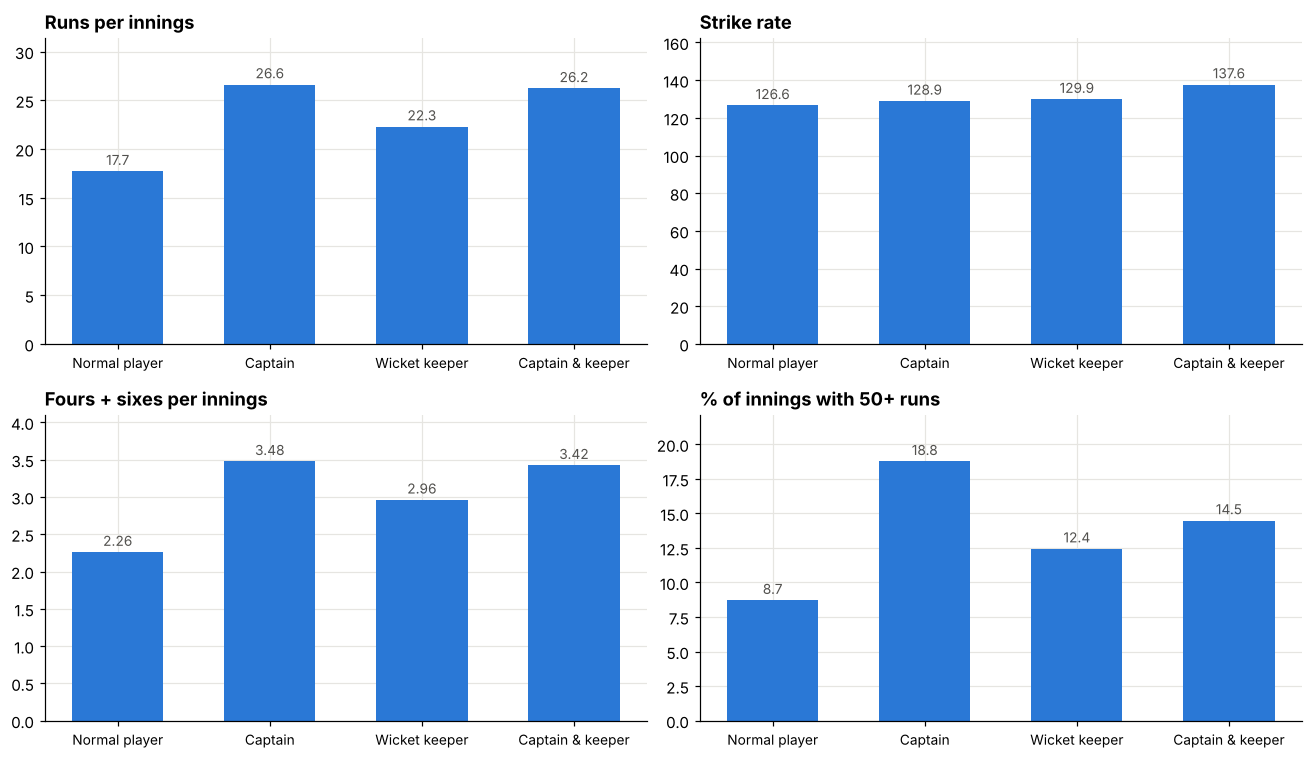

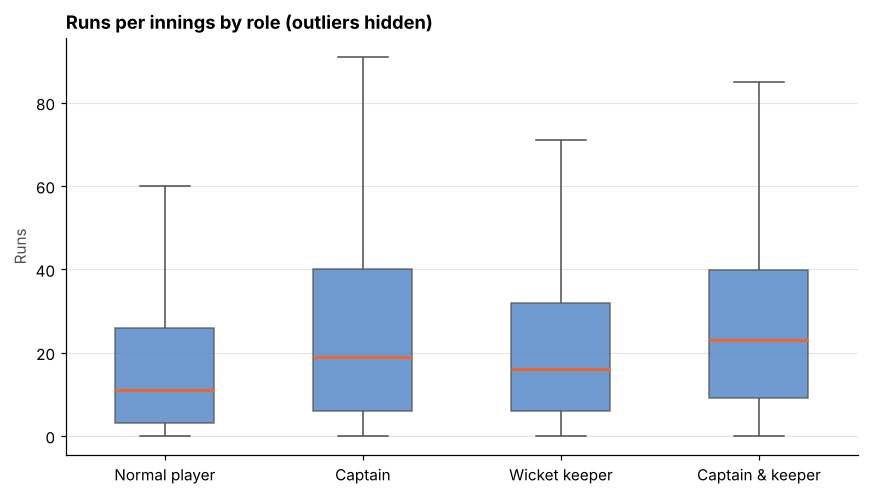

In [56]:
# Charts: How do the roles compare?

labels = [ROLE_LABEL[r] for r in ROLE_ORDER]

panels = [
    ("runs_per_innings", "Runs per innings", "%.1f"),
    ("strike_rate", "Strike rate", "%.1f"),
    ("boundaries_per_innings", "Fours + sixes per innings", "%.2f"),
    ("pct_50_plus", "% of innings with 50+ runs", "%.1f"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, (col, title, fmt) in zip(axes.ravel(), panels):
    vals = roles[col].values
    bars = ax.bar(labels, vals, color=BLUE, width=0.6)
    ax.bar_label(bars, fmt=fmt, fontsize=9, color=INK, padding=2)
    ax.set_title(title)
    ax.set_ylim(0, vals.max() * 1.18)
    ax.tick_params(axis="x", labelsize=9)
plt.tight_layout()
plt.show()

# Spread of runs per innings by role (box = middle 50% of innings, line = median)

fig, ax = plt.subplots(figsize=(8, 4.6))
tmp = bat.assign(role=bat["special_role"].map(ROLE_LABEL))
sns.boxplot(data=tmp, x="role", y="R", order=labels, color=BLUE, width=0.5, showfliers=False,
            boxprops={"alpha": 0.75}, medianprops={"color": ORANGE, "linewidth": 2}, ax=ax)
ax.set_title("Runs per innings by role (outliers hidden)")
ax.set_xlabel("")
ax.set_ylabel("Runs")
plt.tight_layout()
plt.show()

In [57]:
# Are the differences real, or just noise?

# Runs per innings are heavily skewed, so use rank-based tests instead of t-tests.

groups = {r: bat.loc[bat["special_role"] == r, "R"] for r in ROLE_ORDER}

H, p_all = stats.kruskal(*groups.values())

print(f"Kruskal-Wallis across the 4 roles: H = {H:.1f}, p = {p_all:.4g}\n")

rows = []

base = groups["normal player"]

for r in ROLE_ORDER[1:]:
    u, p = stats.mannwhitneyu(groups[r], base, alternative="two-sided")
    rows.append({
        "role vs normal player": ROLE_LABEL[r],
        "median runs (role)": groups[r].median(),
        "median runs (normal)": base.median(),
        "chance role innings > normal innings": u / (len(groups[r]) * len(base)),
        "p-value": p,
    })

tests = pd.DataFrame(rows).set_index("role vs normal player")
tests["significant (p<0.05)"] = tests["p-value"] < 0.05
tests["p-value"] = tests["p-value"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}")
display(tests.round(3))

print("'Chance role innings > normal innings' is 0.50 when the two roles score alike; above 0.50 means the role scores more.")

Kruskal-Wallis across the 4 roles: H = 265.1, p = 3.571e-57



,median runs (role),median runs (normal),chance role innings > normal innings,p-value,significant (p<0.05)
role vs normal player,,,,,
Captain,19.0,11.0,0.617,<0.001,True
Wicket keeper,16.0,11.0,0.577,<0.001,True
Captain & keeper,23.0,11.0,0.646,<0.001,True


'Chance role innings > normal innings' is 0.50 when the two roles score alike; above 0.50 means the role scores more.


Captain: 20 batters with 15+ innings both ways
  Average runs per innings: 27.3 in the role vs 25.2 otherwise
  Average strike rate     : 130.8 in the role vs 127.9 otherwise
  12 of 20 scored more per innings in the role

Wicket keeper: 10 batters with 15+ innings both ways
  Average runs per innings: 25.5 in the role vs 23.0 otherwise
  Average strike rate     : 130.0 in the role vs 128.1 otherwise
  5 of 10 scored more per innings in the role



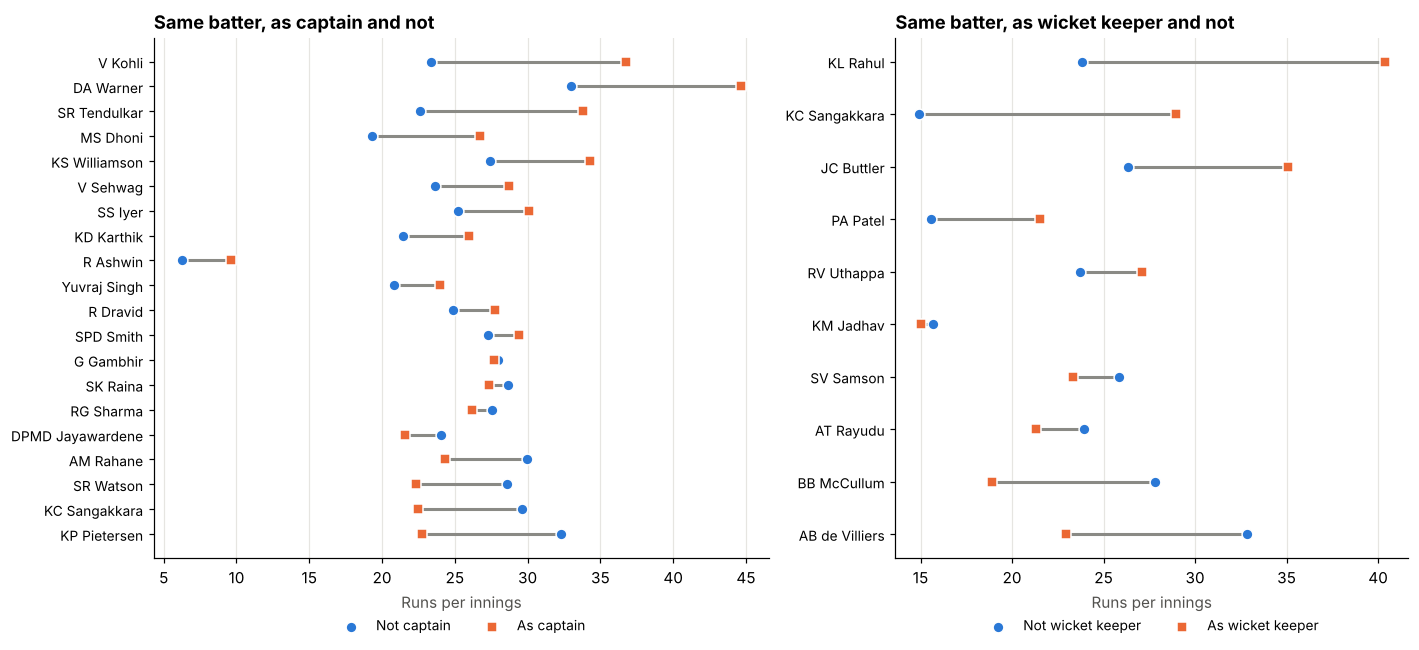

Detail (runs per innings and strike rate in the role vs not):


,innings_role,innings_other,runs_per_innings_role,runs_per_innings_other,strike_rate_role,strike_rate_other
batsmen,,,,,,
MS Dhoni,155,15,26.7,19.3,139.7,116.0
G Gambhir,127,25,27.7,28.0,122.8,129.7
V Kohli,109,60,36.8,23.4,136.5,119.4
RG Sharma,103,80,26.1,27.6,130.6,131.1
V Sehwag,53,51,28.8,23.6,167.7,142.3
SR Tendulkar,51,27,33.8,22.6,120.2,118.9
R Dravid,47,35,27.7,24.9,114.9,116.5
DA Warner,47,79,44.7,33.0,148.4,137.9
KC Sangakkara,46,22,22.5,29.6,119.0,124.9


In [58]:
# A fairer comparison: the SAME batter as captain/keeper and when not

# Captains and keepers may simply be better batters. Comparing a player with himself removes that bias.

def paired_role(flag, role_name, min_inn=15):

    yes = summarise(bat[bat[flag]], "batsmen")
    no = summarise(bat[~bat[flag]], "batsmen")
    both = yes.join(no, lsuffix="_role", rsuffix="_other", how="inner")
    both = both[(both["innings_role"] >= min_inn) & (both["innings_other"] >= min_inn)].copy()
    both["diff_runs_per_innings"] = both["runs_per_innings_role"] - both["runs_per_innings_other"]
    both["diff_strike_rate"] = both["strike_rate_role"] - both["strike_rate_other"]
    both = both.sort_values("diff_runs_per_innings")

    print(f"{role_name}: {len(both)} batters with {min_inn}+ innings both ways")
    print(f"  Average runs per innings: {both['runs_per_innings_role'].mean():.1f} in the role vs {both['runs_per_innings_other'].mean():.1f} otherwise")
    print(f"  Average strike rate     : {both['strike_rate_role'].mean():.1f} in the role vs {both['strike_rate_other'].mean():.1f} otherwise")
    print(f"  {int((both['diff_runs_per_innings'] > 0).sum())} of {len(both)} scored more per innings in the role\n")

    return both

cap_pairs = paired_role("is_captain", "Captain")

keep_pairs = paired_role("is_keeper", "Wicket keeper")

fig, axes = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1.2, 1]})

for ax, pairs, name in [(axes[0], cap_pairs, "captain"), (axes[1], keep_pairs, "wicket keeper")]:
    y = np.arange(len(pairs))
    ax.hlines(y, pairs["runs_per_innings_other"], pairs["runs_per_innings_role"], color=GREY, lw=2, zorder=1)
    ax.scatter(pairs["runs_per_innings_other"], y, color=BLUE, s=50, zorder=2, edgecolor="white", label=f"Not {name}")
    ax.scatter(pairs["runs_per_innings_role"], y, color=ORANGE, s=50, marker="s", zorder=3, edgecolor="white", label=f"As {name}")
    ax.set_yticks(y)
    ax.set_yticklabels(pairs.index, fontsize=9)
    ax.set_title(f"Same batter, as {name} and not")
    ax.set_xlabel("Runs per innings")
    ax.grid(axis="y", visible=False)
    ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2)

plt.tight_layout()
plt.show()

print("Detail (runs per innings and strike rate in the role vs not):")

display(cap_pairs[["innings_role", "innings_other", "runs_per_innings_role", "runs_per_innings_other",
                   "strike_rate_role", "strike_rate_other"]].round(1).sort_values("innings_role", ascending=False))

In [59]:
# Who plays these roles most?

def role_leaders(flag, n=8):
    t = summarise(bat[bat[flag]], "batsmen").sort_values("innings", ascending=False).head(n)
    return t[["innings", "runs", "runs_per_innings", "average", "strike_rate", "seasons"]].round(1)

print("Most innings as captain:")
display(role_leaders("is_captain"))
print("Most innings as wicket keeper:")
display(role_leaders("is_keeper"))

cap_share = bat.loc[bat["is_captain"], "batsmen"].value_counts(normalize=True)
print(f"Captain innings by the 5 most frequent captains: {cap_share.head(5).sum() * 100:.1f}% of all captain innings; "
      f"{bat.loc[bat['is_captain'], 'batsmen'].nunique()} different batters captained.")

Most innings as captain:


,innings,runs,runs_per_innings,average,strike_rate,seasons
batsmen,,,,,,
MS Dhoni,155,4142.0,26.7,44.1,139.7,11
G Gambhir,127,3518.0,27.7,31.1,122.8,10
V Kohli,109,4010.0,36.8,44.1,136.5,9
RG Sharma,103,2693.0,26.1,30.6,130.6,7
AC Gilchrist,74,1900.0,25.7,26.8,136.6,6
V Sehwag,53,1524.0,28.8,31.1,167.7,5
SR Tendulkar,51,1723.0,33.8,40.1,120.2,4
R Dravid,47,1304.0,27.7,29.0,114.9,3


Most innings as wicket keeper:


,innings,runs,runs_per_innings,average,strike_rate,seasons
batsmen,,,,,,
MS Dhoni,165,4314.0,26.1,42.7,137.8,12
KD Karthik,149,3371.0,22.6,27.4,130.0,11
PA Patel,120,2583.0,21.5,23.5,122.9,12
RV Uthappa,111,3011.0,27.1,29.0,133.5,9
NV Ojha,93,1553.0,16.7,21.0,118.6,9
WP Saha,83,1564.0,18.8,23.7,132.9,9
AC Gilchrist,80,2069.0,25.9,27.2,138.4,6
KC Sangakkara,48,1389.0,28.9,30.2,126.3,6


Captain innings by the 5 most frequent captains: 41.2% of all captain innings; 49 different batters captained.


# Key Findings and Saved Output (objective 2)

In [60]:
# Key findings, calculated from the data

n_top = top10.iloc[0]
print(f"TASK 1  Top run scorer: {top10.index[0]} with {n_top['runs']:.0f} runs in {n_top['innings']:.0f} innings; "
      f"{top10.index[1]} ({top10.iloc[1]['runs']:.0f}) and {top10.index[2]} ({top10.iloc[2]['runs']:.0f}) follow.")
best_season = orange_cap["runs"].idxmax()
print(f"        Best single season: {orange_cap.loc[best_season, 'batsmen']} with {orange_cap.loc[best_season, 'runs']} runs in {best_season}.")
print(f"        The top 10 batters scored {cum_share.iloc[9]:.1f}% of all runs; the top 50 scored {cum_share.iloc[49]:.1f}%.")

sr_leader = top_sr.index[0]
print(f"TASK 2  Fastest scorer (500+ balls): {sr_leader} at {top_sr.iloc[0]['strike_rate']:.1f}; best average: {top_avg.index[0]} at {top_avg.iloc[0]['average']:.1f}.")
print(f"        {len(best_both)} of {len(qualified)} qualified batters are above the median on both average and strike rate.")
long_inn = faced[faced["B"] >= 31]
peak = season_sr["strike_rate"].idxmax()
print(f"        League strike rate went from {season_sr['strike_rate'].iloc[0]:.1f} in {season_sr.index[0]} to {season_sr['strike_rate'].iloc[-1]:.1f} in {season_sr.index[-1]} (peak {season_sr.loc[peak, 'strike_rate']:.1f} in {peak}); "
      f"innings of 31+ balls scored at {long_inn['R'].sum() / long_inn['B'].sum() * 100:.0f} vs {by_band['strike_rate'].iloc[0]:.0f} for innings of 1-5 balls.")

print(f"TASK 3  Most fours: {top_fours.index[0]} ({top_fours.iloc[0]['fours']:.0f}); most sixes: {top_sixes.index[0]} ({top_sixes.iloc[0]['sixes']:.0f}).")
print(f"        Boundaries gave {share_50_plus:.0f}% of runs in 50+ innings vs {share_under_50:.0f}% in innings under 50; "
      f"sixes alone gave {share.loc['100+', 'Sixes']:.0f}% of runs in hundreds vs {share.loc['1-9', 'Sixes']:.0f}% in 1-9 run innings.")
print(f"        Sixes per 100 balls: {season_rates['sixes_per100'].iloc[0]:.1f} in {season_rates.index[0]} vs {season_rates['sixes_per100'].iloc[-1]:.1f} in {season_rates.index[-1]}; "
      f"fours: {season_rates['fours_per100'].iloc[0]:.1f} vs {season_rates['fours_per100'].iloc[-1]:.1f}.")

print(f"TASK 4  Runs per innings: " + ", ".join(f"{ROLE_LABEL[r]} {roles.loc[r, 'runs_per_innings']:.1f}" for r in ROLE_ORDER) + ".")
print(f"        Strike rate: " + ", ".join(f"{ROLE_LABEL[r]} {roles.loc[r, 'strike_rate']:.1f}" for r in ROLE_ORDER) + ".")
print(f"        As captain, the same batters scored {cap_pairs['runs_per_innings_role'].mean():.1f} runs per innings vs {cap_pairs['runs_per_innings_other'].mean():.1f} when not captain "
      f"({int((cap_pairs['diff_runs_per_innings'] > 0).sum())} of {len(cap_pairs)} did better as captain).")

TASK 1  Top run scorer: V Kohli with 5412 runs in 169 innings; SK Raina (5368) and RG Sharma (4898) follow.
        Best single season: V Kohli with 973.0 runs in 2016.
        The top 10 batters scored 21.2% of all runs; the top 50 scored 61.5%.
TASK 2  Fastest scorer (500+ balls): AD Russell at 186.4; best average: DA Warner at 43.2.
        27 of 92 qualified batters are above the median on both average and strike rate.
        League strike rate went from 129.0 in 2008 to 133.7 in 2019 (peak 137.9 in 2018); innings of 31+ balls scored at 139 vs 86 for innings of 1-5 balls.
TASK 3  Most fours: S Dhawan (524); most sixes: CH Gayle (326).
        Boundaries gave 64% of runs in 50+ innings vs 56% in innings under 50; sixes alone gave 37% of runs in hundreds vs 8% in 1-9 run innings.
        Sixes per 100 balls: 4.8 in 2008 vs 5.6 in 2019; fours: 13.1 vs 11.9.
TASK 4  Runs per innings: Normal player 17.7, Captain 26.6, Wicket keeper 22.3, Captain & keeper 26.2.
        Strike rate: Norm

In [61]:
# Saved Output

summary = players.copy()
summary["qualified_500_balls"] = summary["balls"] >= MIN_BALLS
summary = summary.join(qualified["style"]).sort_values("runs", ascending=False)
summary.round(2).to_csv("ipl_player_summary.csv")

print(f"Saved ipl_player_summary.csv: {summary.shape[0]} batters x {summary.shape[1]} columns")
display(summary.head(5).round(1))

Saved ipl_player_summary.csv: 518 batters x 22 columns


,innings,dismissals,runs,balls,highest,fifties,hundreds,fours,sixes,seasons,not_outs,average,strike_rate,runs_per_innings,boundary_runs,boundary_pct,balls_per_boundary,balls_per_six,fours_per100,sixes_per100,qualified_500_balls,style
batsmen,,,,,,,,,,,,,,,,,,,,,,
V Kohli,169,143,5412.0,4112.0,113.0,36,5,480.0,190.0,12,26,37.8,131.6,32.0,3060.0,56.5,6.1,21.6,11.7,4.6,True,Fast and consistent
SK Raina,189,161,5368.0,3915.0,100.0,38,1,493.0,194.0,12,28,33.3,137.1,28.4,3136.0,58.4,5.7,20.2,12.6,5.0,True,Fast and consistent
RG Sharma,183,155,4898.0,3744.0,109.0,36,1,431.0,194.0,12,28,31.6,130.8,26.8,2888.0,59.0,6.0,19.3,11.5,5.2,True,Fast and consistent
DA Warner,126,109,4706.0,3305.0,126.0,44,4,458.0,181.0,10,17,43.2,142.4,37.3,2918.0,62.0,5.2,18.3,13.9,5.5,True,Fast and consistent
S Dhawan,158,137,4579.0,3669.0,97.0,37,0,524.0,96.0,12,21,33.4,124.8,29.0,2672.0,58.4,5.9,38.2,14.3,2.6,True,Steady but slower


# Objective 3: Analyse Scoring and Dismissals

# Task 1: Understand different dismissal patterns.

,dismissals,% of dismissals
Caught,5552,63.0
Run out,850,9.6
Bowled,1578,17.9
LBW,540,6.1
Stumped,284,3.2
"Other (hit wicket, obstructing)",12,0.1


Of 5,552 catches: 864 by wicket keepers, 254 caught & bowled, 4,434 by other fielders.
The bowler is credited with 7,964 of 8,816 dismissals (90.3%); the rest are run outs and the rare 'other' cases.


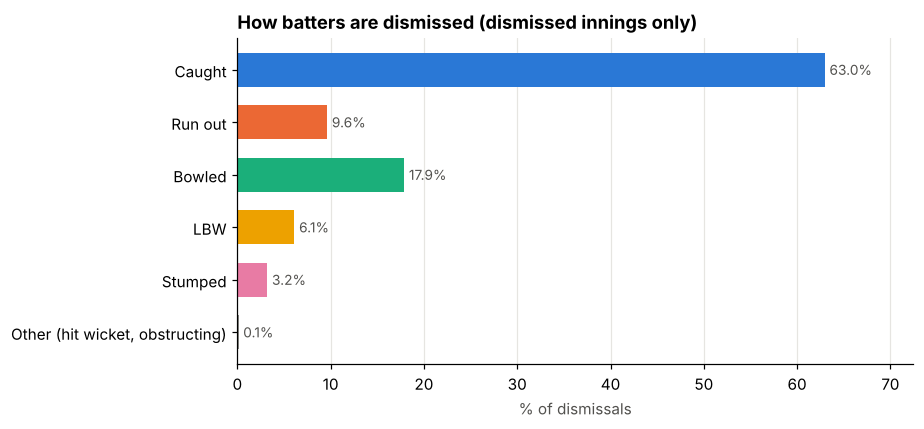

In [62]:
# How do batters get out?

# Define the dismissed dataframe 'dis' and map the modes into our standard groups

# We compute the boolean dismissal flag directly from the 'dismissal_mode' column

dismissed_mask = ~ipl_cricket["dismissal_mode"].isin(["not out", "retired", "absent hurt"])
dis = ipl_cricket[dismissed_mask].copy()
dis["mode_group"] = dis["dismissal_mode"].apply(lambda m: m if m in STACK_ORDER else "other")

mix = dis["mode_group"].value_counts().reindex(STACK_ORDER, fill_value=0)
mix_table = pd.DataFrame({"dismissals": mix, "% of dismissals": (mix / mix.sum() * 100).round(1)})
mix_table.index = [MODE_LABEL[m] for m in mix_table.index]
display(mix_table)

caught = dis[dis["dismissal_mode"] == "caught"]
n_keeper = int(caught["wicket_status"].str.contains("†", regex=False).sum())
n_cb = int(caught["wicket_status"].str.startswith("c & b").sum())
print(f"Of {len(caught):,} catches: {n_keeper} by wicket keepers, {n_cb} caught & bowled, "
      f"{len(caught) - n_keeper - n_cb:,} by other fielders.")
credited = dis["bowler_name"].notna().sum()
print(f"The bowler is credited with {credited:,} of {len(dis):,} dismissals ({credited / len(dis) * 100:.1f}%); "
      f"the rest are run outs and the rare 'other' cases.")

order = [m for m in STACK_ORDER if mix[m] > 0]
fig, ax = plt.subplots(figsize=(8.5, 4))
vals = (mix[order] / mix.sum() * 100)
bars = ax.barh([MODE_LABEL[m] for m in order], vals, color=[MODE_COLOR[m] for m in order], height=0.65)
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9, color=INK)
ax.set_xlim(0, vals.max() * 1.15)
ax.set_title("How batters are dismissed (dismissed innings only)")
ax.set_xlabel("% of dismissals")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

% of dismissals by season:


mode_group,Caught,Run out,Bowled,LBW,Stumped,"Other (hit wicket, obstructing)"
season,,,,,,
2008,61.1,12.3,19.0,5.4,1.9,0.3
2009,62.0,10.9,16.1,6.7,4.2,0.1
2010,56.9,12.9,19.4,5.7,5.0,0.0
2011,61.6,9.1,19.2,6.6,3.4,0.0
2012,62.2,9.9,19.4,4.9,3.4,0.2
2013,62.9,8.7,18.6,7.7,2.0,0.1
2014,60.1,9.7,21.2,5.4,3.7,0.0
2015,65.7,9.0,17.6,4.4,3.2,0.0
2016,62.3,11.1,16.7,6.2,3.3,0.5


% of dismissals by the score the batter was out on:


mode_group,Caught,Run out,Bowled,LBW,Stumped,"Other (hit wicket, obstructing)",dismissals
score_band,,,,,,,
0 (duck),54.1,11.7,22.0,10.1,2.0,0.0,881
1-9,60.9,11.7,18.0,6.5,2.8,0.1,2931
10-19,65.5,7.6,17.4,5.7,3.7,0.2,1818
20-29,64.0,8.6,18.6,4.6,4.0,0.2,1191
30-49,65.8,7.9,16.8,5.4,3.8,0.2,1232
50+,69.1,8.7,14.4,4.7,2.9,0.3,763


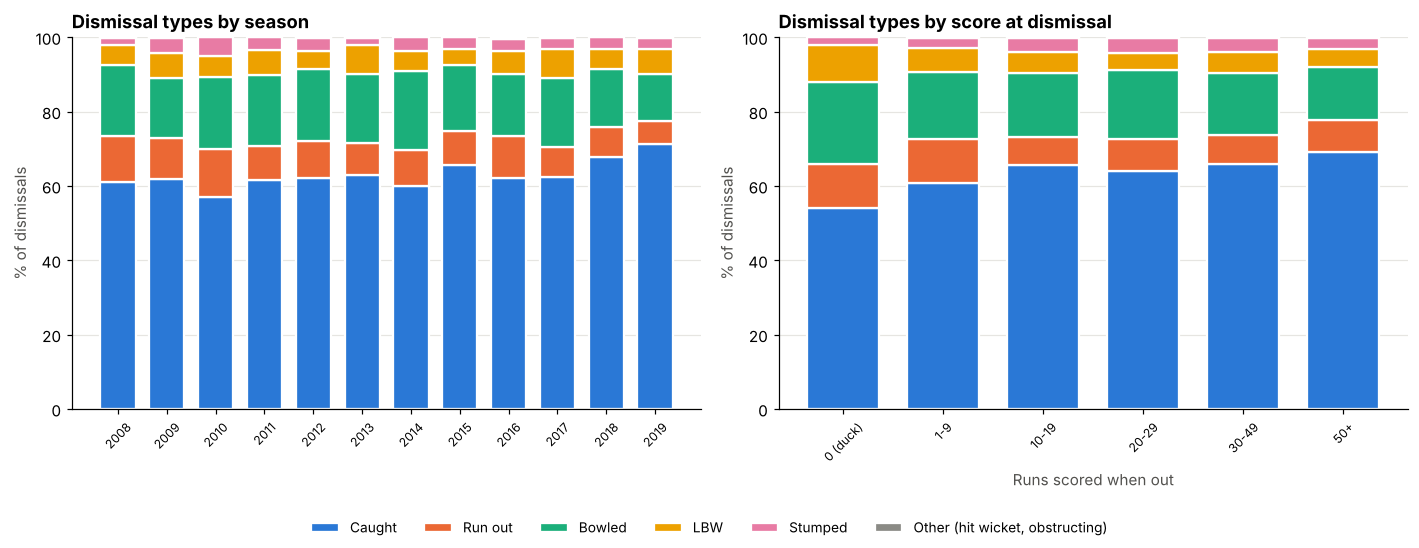

In [63]:
# Does the dismissal pattern change over the seasons, and with the size of the score?

season_mix = (pd.crosstab(dis["season"], dis["mode_group"], normalize="index") * 100).reindex(columns=STACK_ORDER, fill_value=0)

dis["score_band"] = pd.cut(dis["R"], bins=[-1, 0, 9, 19, 29, 49, 500],
                           labels=["0 (duck)", "1-9", "10-19", "20-29", "30-49", "50+"])
band_mix = (pd.crosstab(dis["score_band"], dis["mode_group"], normalize="index") * 100).reindex(columns=STACK_ORDER, fill_value=0)
band_n = dis["score_band"].value_counts().reindex(band_mix.index)

print("% of dismissals by season:")
display(season_mix.rename(columns=MODE_LABEL).round(1))
print("% of dismissals by the score the batter was out on:")
display(band_mix.rename(columns=MODE_LABEL).round(1).assign(dismissals=band_n.values))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
stacked_share(axes[0], season_mix, STACK_ORDER, "Dismissal types by season")
stacked_share(axes[1], band_mix, STACK_ORDER, "Dismissal types by score at dismissal", "Runs scored when out")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6, frameon=False, fontsize=9)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

Ducks: 881 (10.0% of dismissals, 7.6% of all innings)
  out to the first ball faced: 429; run out without facing a ball: 41


,% of ducks,% of all dismissals
Caught,54.1,63.0
Run out,11.7,9.6
Bowled,22.0,17.9
LBW,10.1,6.1
Stumped,2.0,3.2
"Other (hit wicket, obstructing)",0.0,0.1


Batters with the most ducks:


,innings,ducks,duck_pct
batsmen,,,
Harbhajan Singh,88,13,14.8
PA Patel,137,13,9.5
PP Chawla,81,12,14.8
MK Pandey,120,12,10.0
AT Rayudu,140,12,8.6
G Gambhir,152,12,7.9
RG Sharma,183,12,6.6
AM Rahane,132,11,8.3
A Mishra,56,10,17.9


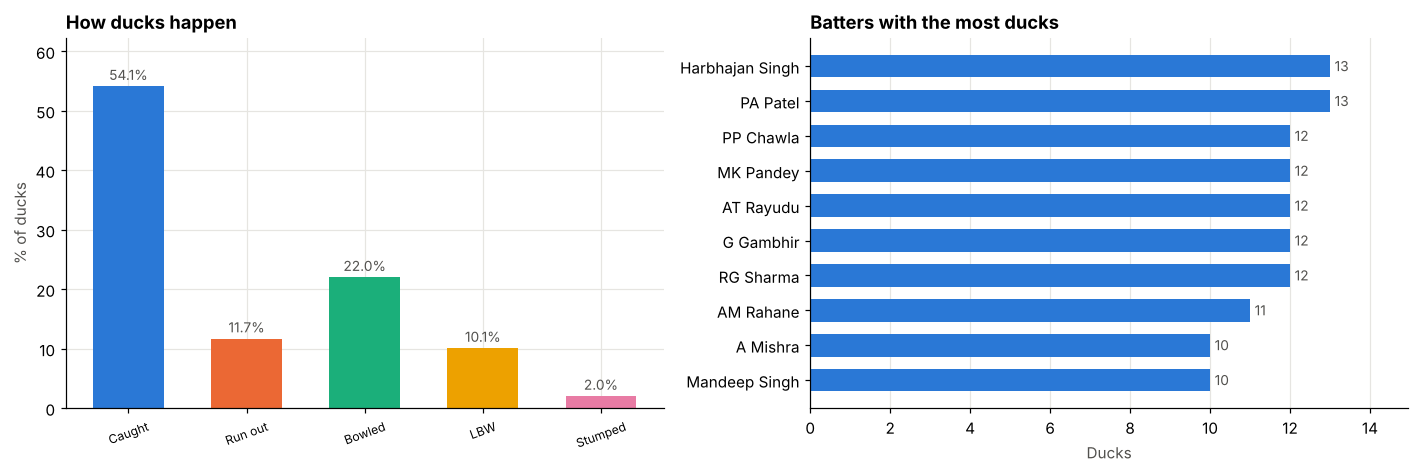

In [64]:
# Ducks: dismissed without scoring

ducks = dis[dis["R"] == 0]
golden = int(((dis["R"] == 0) & (dis["B"] == 1)).sum())
no_ball = int(((dis["R"] == 0) & (dis["B"] == 0)).sum())
print(f"Ducks: {len(ducks):,} ({len(ducks) / len(dis) * 100:.1f}% of dismissals, {len(ducks) / len(bat) * 100:.1f}% of all innings)")
print(f"  out to the first ball faced: {golden}; run out without facing a ball: {no_ball}")

duck_vs_all = pd.DataFrame({
    "% of ducks": ducks["mode_group"].value_counts(normalize=True).reindex(STACK_ORDER, fill_value=0) * 100,
    "% of all dismissals": dis["mode_group"].value_counts(normalize=True).reindex(STACK_ORDER, fill_value=0) * 100,
})
duck_vs_all.index = [MODE_LABEL[m] for m in duck_vs_all.index]
display(duck_vs_all.round(1))

by_player = bat.groupby("batsmen").size().rename("innings").to_frame()
by_player["ducks"] = ducks.groupby("batsmen").size().reindex(by_player.index, fill_value=0)
by_player["duck_pct"] = by_player["ducks"] / by_player["innings"] * 100

most_ducks = by_player.sort_values(["ducks", "innings"], ascending=[False, True]).head(10)
print("Batters with the most ducks:")
display(most_ducks.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
d = duck_vs_all["% of ducks"]
d = d[d > 0]
inv = {v: k for k, v in MODE_LABEL.items()}
bars = axes[0].bar(d.index, d.values, color=[MODE_COLOR[inv[i]] for i in d.index], width=0.6)
axes[0].bar_label(bars, fmt="%.1f%%", fontsize=9, color=INK, padding=2)
axes[0].set_title("How ducks happen")
axes[0].set_ylabel("% of ducks")
axes[0].tick_params(axis="x", labelsize=8, rotation=20)
axes[0].set_ylim(0, d.max() * 1.15)
hbar(axes[1], most_ducks.index, most_ducks["ducks"], "Batters with the most ducks", "Ducks")
plt.tight_layout()
plt.show()

In [65]:
# How do the 10 leading run scorers get out?

top_scorers = bat.groupby("batsmen")["R"].sum().nlargest(10).index
profile = (pd.crosstab(dis.loc[dis["batsmen"].isin(top_scorers), "batsmen"],
                       dis.loc[dis["batsmen"].isin(top_scorers), "mode_group"], normalize="index") * 100)
profile = profile.reindex(index=top_scorers, columns=STACK_ORDER, fill_value=0).rename(columns=MODE_LABEL)
profile.insert(0, "dismissals", dis[dis["batsmen"].isin(top_scorers)].groupby("batsmen").size().reindex(top_scorers))
print("% of each batter's dismissals by type (top 10 run scorers):")
display(profile.round(1))

% of each batter's dismissals by type (top 10 run scorers):


mode_group,dismissals,Caught,Run out,Bowled,LBW,Stumped,"Other (hit wicket, obstructing)"
batsmen,,,,,,,
V Kohli,143,67.8,4.2,21.0,4.9,2.1,0.0
SK Raina,161,73.3,8.1,9.9,3.7,5.0,0.0
RG Sharma,155,70.3,6.5,14.2,7.1,1.9,0.0
DA Warner,109,64.2,5.5,21.1,3.7,4.6,0.9
S Dhawan,137,59.1,10.2,20.4,5.8,4.4,0.0
CH Gayle,109,69.7,0.9,20.2,6.4,2.8,0.0
MS Dhoni,105,71.4,7.6,13.3,4.8,2.9,0.0
RV Uthappa,153,72.5,5.2,9.2,8.5,4.6,0.0
AB de Villiers,110,61.8,9.1,18.2,5.5,5.5,0.0


# Task 2: Identify key bowlers and fielders

In [66]:
# Which bowler and fielder labels are ambiguous?

batter_names = list(ipl_cricket["batsmen"].unique())

def shared_by(label):
    """Number of batters whose name is, or ends with, this label."""
    return sum(1 for n in batter_names if n == label or n.endswith(" " + label))

labels_needed = set(ipl_cricket["bowler_name"].dropna()) | set(ipl_cricket["fielder"].dropna())
shared = {label: shared_by(label) for label in labels_needed}

# Wickets credited to a bowler: caught, bowled, lbw, stumped, hit wicket (run outs are not credited to bowlers)
w = ipl_cricket[ipl_cricket["bowler_name"].notna()].copy()
w["kind"] = w["dismissal_mode"].where(w["dismissal_mode"].isin(["caught", "bowled", "lbw", "stumped"]), "other")

bowlers = pd.crosstab(w["bowler_name"], w["kind"]).reindex(columns=BOWLER_ORDER, fill_value=0)
bowlers["wickets"] = bowlers[BOWLER_ORDER].sum(axis=1)
bowlers["seasons"] = w.groupby("bowler_name")["season"].nunique()
bowlers["first_season"] = w.groupby("bowler_name")["season"].min()
bowlers["last_season"] = w.groupby("bowler_name")["season"].max()
bowlers["bowled_lbw_pct"] = (bowlers["bowled"] + bowlers["lbw"]) / bowlers["wickets"] * 100
bowlers["name_shared_by"] = [shared[l] for l in bowlers.index]
bowlers["ambiguous"] = bowlers["name_shared_by"] >= AMBIGUOUS_MIN

amb = bowlers[bowlers["ambiguous"]].sort_values("wickets", ascending=False)
print(f"{len(bowlers)} bowler labels, {bowlers['wickets'].sum():,} bowler-credited wickets.")
print(f"{len(amb)} labels are shared by {AMBIGUOUS_MIN}+ batters (for example {', '.join(amb.index[:6])}); "
      f"they carry {amb['wickets'].sum():,} wickets ({amb['wickets'].sum() / bowlers['wickets'].sum() * 100:.0f}%) and cannot be traced to one person.")

pool_b = bowlers[~bowlers["ambiguous"]] if EXCLUDE_AMBIGUOUS else bowlers
def mark(idx, tbl):
    """Add * to names shared by AMBIGUOUS_MIN+ batters and a dagger to names shared by exactly two."""
    out = []
    for i in idx:
        n = tbl.loc[i, "name_shared_by"]
        out.append(f"{i}*" if n >= AMBIGUOUS_MIN else (f"{i}†" if n == 2 else i))
    return out

NAME_NOTE = (f"* name shared by {AMBIGUOUS_MIN}+ batters (several players);  † name shared by two batters "
             f"(may be one player or two).")

342 bowler labels, 7,964 bowler-credited wickets.
9 labels are shared by 3+ batters (for example Sharma, Kumar, Patel, Singh, Pathan, Khan); they carry 1,087 wickets (14%) and cannot be traced to one person.


kind,wickets,caught,bowled,lbw,stumped,bowled_lbw_pct,seasons,first_season,last_season,name_shared_by
bowler_name,,,,,,,,,,
Malinga,170,96,63,11,0,43.5,9,2009,2019,1
Morkel,162,118,34,9,0,26.5,9,2008,2016,2
Mishra,154,89,25,13,27,24.7,12,2008,2019,2
Chawla,150,76,43,16,15,39.3,12,2008,2019,1
Harbhajan Singh,150,94,29,8,18,24.7,12,2008,2019,1
Bravo,147,121,20,6,0,17.7,10,2008,2019,2
Narine,122,61,35,16,10,41.8,8,2012,2019,1
Ashwin,111,73,19,12,7,27.9,10,2009,2019,2
Jadeja,108,62,27,11,8,35.2,10,2009,2019,1


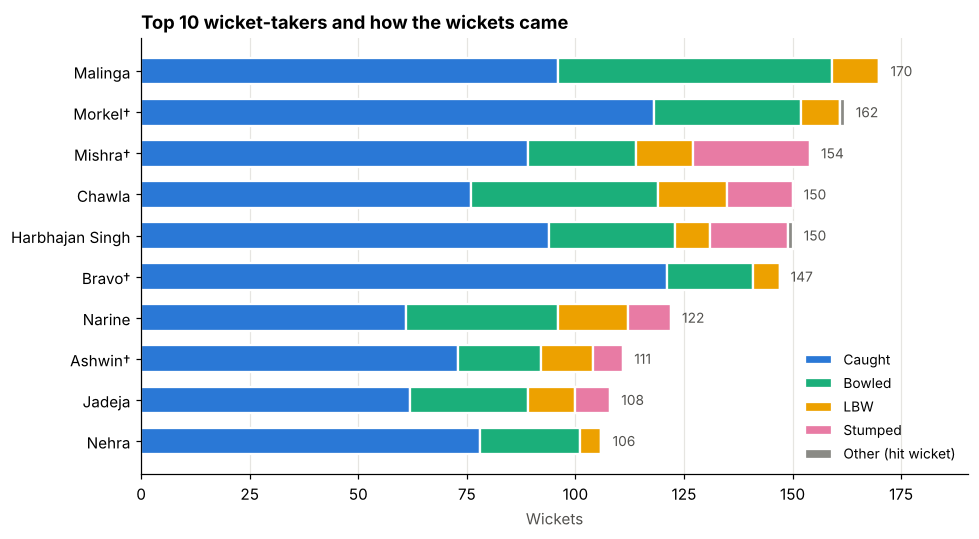

* name shared by 3+ batters (several players);  † name shared by two batters (may be one player or two).
Bowlers whose wickets come most often bowled or lbw (40+ wickets):


kind,wickets,bowled,lbw,bowled_lbw_pct
bowler_name,,,,
Rashid Khan,55,17,15,58.2
Malinga,170,63,11,43.5
Narine,122,35,16,41.8
Chawla,150,43,16,39.3
Mohammed Shami,40,12,3,37.5
Kallis,65,18,6,36.9
Bhatia,71,19,6,35.2
Jadeja,108,27,11,35.2


Most stumpings off a bowler's bowling (usually spinners):


kind,wickets,stumped
bowler_name,,
Mishra,154,27
Harbhajan Singh,150,18
Chawla,150,15
Chahal,100,12
Ojha,89,12
Narine,122,10
Jadeja,108,8
Kumble,45,8


In [67]:
# Top wicket-takers and how they get their wickets

top_bowlers = pool_b.nlargest(10, "wickets")
display(top_bowlers[["wickets", "caught", "bowled", "lbw", "stumped", "bowled_lbw_pct", "seasons",
                     "first_season", "last_season", "name_shared_by"]].round(1))

plot_b = top_bowlers.copy()
plot_b.index = mark(plot_b.index, top_bowlers)
fig, ax = plt.subplots(figsize=(9, 5))
stacked_hbar(ax, plot_b, BOWLER_ORDER, [MODE_COLOR[k] for k in BOWLER_ORDER],
             ["Caught", "Bowled", "LBW", "Stumped", "Other (hit wicket)"], "Top 10 wicket-takers and how the wickets came", "Wickets")
plt.tight_layout()
plt.show()
print(NAME_NOTE)

print("Bowlers whose wickets come most often bowled or lbw (40+ wickets):")
display(pool_b[pool_b["wickets"] >= 40].nlargest(8, "bowled_lbw_pct")[["wickets", "bowled", "lbw", "bowled_lbw_pct"]].round(1))
print("Most stumpings off a bowler's bowling (usually spinners):")
display(pool_b.nlargest(8, "stumped")[["wickets", "stumped"]])

,bowler_name,wickets,name_shared_by,biggest label (any),its wickets
season,,,,,
2008,Sohail Tanvir,22,1,Singh,26
2009,Kumble,21,1,Singh,33
2010,Ojha,21,2,Ojha,21
2011,Malinga,28,1,Malinga,28
2012,Morkel,38,2,Morkel,38
2013,Bravo,32,2,Sharma,36
2014,Narine,21,1,Sharma,36
2015,Bravo,26,2,Patel,30
2016,Chahal,21,1,Kumar,32


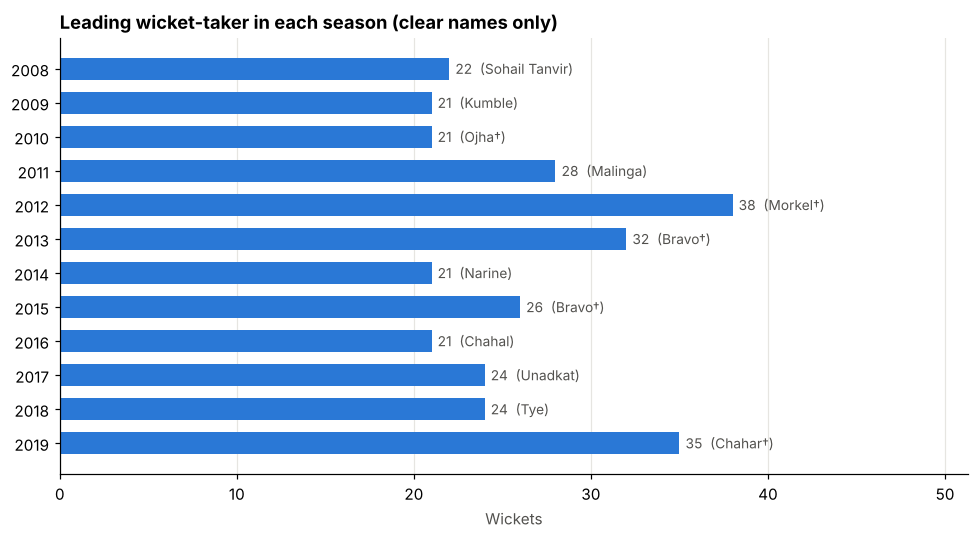

* name shared by 3+ batters (several players);  † name shared by two batters (may be one player or two).
Where 'biggest label (any)' is a shared surname with more wickets than the leader (for example Sharma, Singh, Kumar), the real leader of that season may be hidden behind the surname.
Batter and bowler pairs with the most dismissals:


,batsmen,bowler_name,dismissals,bowler_name_shared_by
1,SR Watson,Mishra,6,2
2,V Kohli,Nehra,6,1
3,AT Rayudu,Chawla,6,1
4,RG Sharma,Narine,6,1
5,V Kohli,Sandeep Sharma,6,1
6,RG Sharma,Vinay Kumar,6,1
7,MS Dhoni,Ojha,6,2
8,RG Sharma,Mishra,6,2
9,SK Raina,Harbhajan Singh,5,1
10,SR Watson,Jadeja,5,1


In [68]:
# Leading wicket-taker of every season (the 'Purple Cap')
# Ranked among bowlers with a clear name. A surname shared by many batters (Sharma, Singh, Kumar...) can add several
# bowlers together, so the table also shows the biggest label of any kind to make that visible.

season_w = w.groupby(["season", "bowler_name"]).size().rename("wickets").reset_index()
clear_w = season_w[season_w["bowler_name"].isin(pool_b.index)]
pick = lambda t: t.sort_values(["season", "wickets"], ascending=[True, False]).groupby("season").head(1).set_index("season")
purple, purple_any = pick(clear_w), pick(season_w)
purple["name_shared_by"] = purple["bowler_name"].map(shared)
purple["label"] = [f"{n}*" if k >= AMBIGUOUS_MIN else (f"{n}\u2020" if k == 2 else n)
                   for n, k in zip(purple["bowler_name"], purple["name_shared_by"])]
context = purple_any[["bowler_name", "wickets"]].rename(columns={"bowler_name": "biggest label (any)", "wickets": "its wickets"})
display(purple[["bowler_name", "wickets", "name_shared_by"]].join(context))

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(purple))
bars = ax.barh(y, purple["wickets"], color=BLUE, height=0.65)
ax.set_yticks(y)
ax.set_yticklabels(purple.index)
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{n}  ({l})" for n, l in zip(purple["wickets"], purple["label"])], padding=4, fontsize=9, color=INK)
ax.set_xlim(0, purple["wickets"].max() * 1.35)
ax.set_title("Leading wicket-taker in each season (clear names only)")
ax.set_xlabel("Wickets")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(NAME_NOTE)
print("Where 'biggest label (any)' is a shared surname with more wickets than the leader (for example Sharma, Singh, Kumar), "
      "the real leader of that season may be hidden behind the surname.")

print("Batter and bowler pairs with the most dismissals:")
pairs = (w[w["bowler_name"].isin(pool_b.index)].groupby(["batsmen", "bowler_name"]).size().rename("dismissals").reset_index()
          .sort_values("dismissals", ascending=False).head(10))
pairs["bowler_name_shared_by"] = pairs["bowler_name"].map(shared)
pairs.index = range(1, len(pairs) + 1)
display(pairs)

7,153 fielding events by 500 fielder labels (5,552 catches, 284 stumpings, 1317 run-out involvements).
Catches taken by substitute fielders: 96. A run out with two fielders named counts for both; labels shared by 3+ batters carry 10% of events.
Best fielders who were not keeping (catches + run-out involvements):


kind,catches_fielder,run_outs,catches_and_run_outs,name_shared_by
fielder,,,,
Raina,102,16,118,1
de Villiers,84,21,105,1
Pollard,82,13,95,1
Kohli,74,18,92,2
Bravo,74,15,89,2
Jadeja,63,24,87,1
Dhawan,74,8,82,2
Pandey,68,14,82,2
Tiwary,67,8,75,2


Wicket keepers (catches behind the stumps + stumpings):


kind,catches_keeper,stumpings,keeper_dismissals,name_shared_by
fielder,,,,
Dhoni,94,38,132,1
Karthik,101,30,131,2
Uthappa,58,32,90,1
Patel,63,16,79,5
Ojha,65,10,75,2
Saha,55,19,74,1
Gilchrist,51,16,67,1
Sangakkara,34,9,43,1


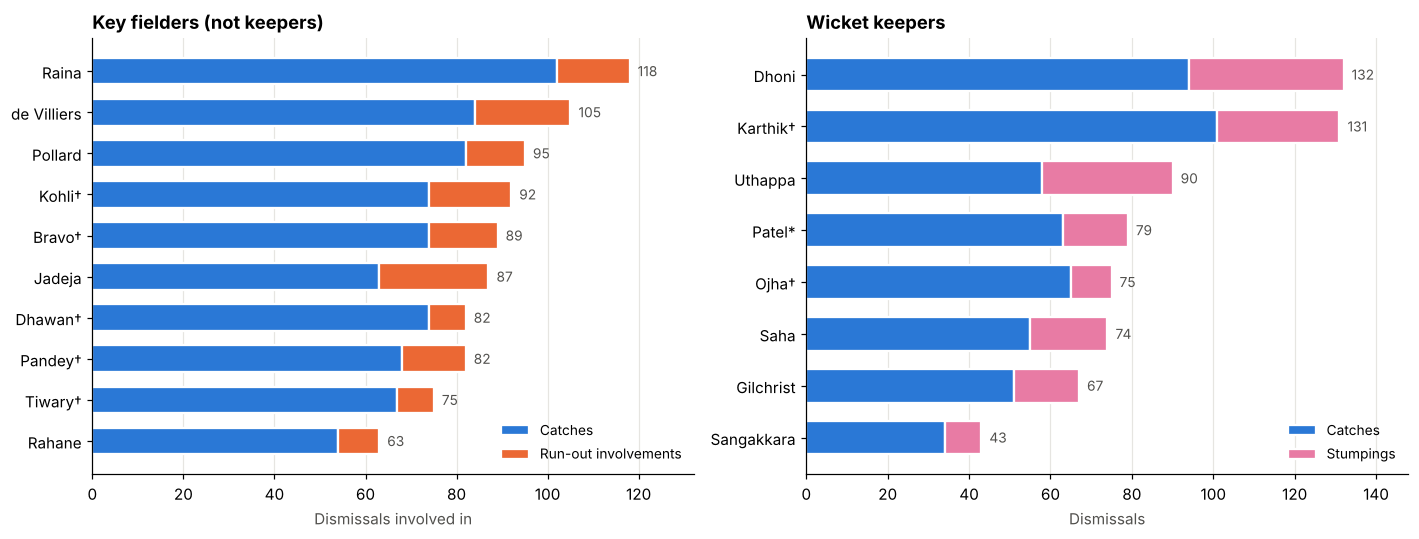

* name shared by 3+ batters (several players);  † name shared by two batters (may be one player or two).  Keepers are kept even when the name is shared, because the dagger in the scorecard marks the keeper.
Bowlers with the most caught-and-bowled dismissals: Harbhajan Singh (11), Bravo (10), Patel (7), Narine (7), Pollard (6)


In [69]:
# Fielding events: catches, stumpings and run-out involvement
# 'Catch (keeper)' = caught by the wicket keeper (marked with a dagger in the scorecard text); 'caught & bowled' counts as a fielder catch.

c = ipl_cricket[ipl_cricket["dismissal_mode"] == "caught"]
s = ipl_cricket[ipl_cricket["dismissal_mode"] == "stumped"]
ro = ipl_cricket.loc[ipl_cricket["runout_fielders"].notna(), "runout_fielders"]
ro = ro.str.replace(r"sub \((.+?)\)", r"\1", regex=True).str.split("/").explode().str.strip()

events = pd.concat([
    pd.DataFrame({"fielder": c["fielder"].values,
                  "kind": np.where(c["wicket_status"].str.contains("†", regex=False), "catches_keeper", "catches_fielder")}),
    pd.DataFrame({"fielder": s["fielder"].values, "kind": "stumpings"}),
    pd.DataFrame({"fielder": ro.values, "kind": "run_outs"}),
], ignore_index=True).dropna()

KINDS = ["catches_fielder", "catches_keeper", "stumpings", "run_outs"]
fielders = pd.crosstab(events["fielder"], events["kind"]).reindex(columns=KINDS, fill_value=0)
fielders["keeper_dismissals"] = fielders["catches_keeper"] + fielders["stumpings"]
fielders["total_involved"] = fielders[KINDS].sum(axis=1)
fielders["name_shared_by"] = [shared.get(l, shared_by(l)) for l in fielders.index]
fielders["ambiguous"] = fielders["name_shared_by"] >= AMBIGUOUS_MIN
fielders["is_keeper"] = (fielders["keeper_dismissals"] >= 20) & (fielders["keeper_dismissals"] >= fielders["catches_fielder"])

print(f"{len(events):,} fielding events by {len(fielders)} fielder labels "
      f"({int(fielders['catches_fielder'].sum() + fielders['catches_keeper'].sum()):,} catches, {int(fielders['stumpings'].sum())} stumpings, "
      f"{int(fielders['run_outs'].sum())} run-out involvements).")
print(f"Catches taken by substitute fielders: {int(ipl_cricket['is_substitute_fielder'].sum())}. "
      f"A run out with two fielders named counts for both; labels shared by {AMBIGUOUS_MIN}+ batters carry "
      f"{fielders.loc[fielders['ambiguous'], 'total_involved'].sum() / fielders['total_involved'].sum() * 100:.0f}% of events.")

pool_f = fielders[~fielders["ambiguous"]] if EXCLUDE_AMBIGUOUS else fielders
field_outfield = pool_f[~pool_f["is_keeper"]].copy()
field_outfield["catches_and_run_outs"] = field_outfield["catches_fielder"] + field_outfield["run_outs"]
top_field = field_outfield.nlargest(10, "catches_and_run_outs")
top_keepers = fielders[fielders["is_keeper"]].nlargest(8, "keeper_dismissals")

print("Best fielders who were not keeping (catches + run-out involvements):")
display(top_field[["catches_fielder", "run_outs", "catches_and_run_outs", "name_shared_by"]])
print("Wicket keepers (catches behind the stumps + stumpings):")
display(top_keepers[["catches_keeper", "stumpings", "keeper_dismissals", "name_shared_by"]])

pf, pk = top_field.copy(), top_keepers.copy()
pf.index, pk.index = mark(pf.index, top_field), mark(pk.index, top_keepers)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
stacked_hbar(axes[0], pf, ["catches_fielder", "run_outs"], [MODE_COLOR["caught"], MODE_COLOR["run out"]],
             ["Catches", "Run-out involvements"], "Key fielders (not keepers)", "Dismissals involved in")
stacked_hbar(axes[1], pk, ["catches_keeper", "stumpings"], [MODE_COLOR["caught"], MODE_COLOR["stumped"]],
             ["Catches", "Stumpings"], "Wicket keepers", "Dismissals")
plt.tight_layout()
plt.show()

print(NAME_NOTE + "  Keepers are kept even when the name is shared, because the dagger in the scorecard marks the keeper.")
cb = c[c["wicket_status"].str.startswith("c & b")]["fielder"].value_counts()
print("Bowlers with the most caught-and-bowled dismissals: " + ", ".join(f"{n} ({k})" for n, k in cb.head(5).items()))

# Task 3: Compare not-out and dismissed players.

In [70]:
# Side-by-side profile

cmp = bat[(bat["dismissal_mode"] == "not out") | bat["dismissed"]].copy()
cmp["status"] = np.where(cmp["dismissal_mode"] == "not out", "Not out", "Dismissed")
print(f"Compared: {(cmp['status'] == 'Dismissed').sum():,} dismissed and {(cmp['status'] == 'Not out').sum():,} not-out innings "
      f"(left out {len(bat) - len(cmp)} retired).")

prof = cmp.groupby("status").agg(
    innings=("R", "size"), runs=("R", "sum"), balls=("B", "sum"),
    mean_runs=("R", "mean"), median_runs=("R", "median"),
    mean_balls=("B", "mean"), median_balls=("B", "median"),
    fours_per_innings=("fours", "mean"), sixes_per_innings=("sixes", "mean"),
    pct_30_plus=("R", lambda x: (x >= 30).mean() * 100),
    pct_50_plus=("R", lambda x: (x >= 50).mean() * 100),
    pct_no_ball_faced=("B", lambda x: (x == 0).mean() * 100),
)
prof["strike_rate"] = prof["runs"] / prof["balls"] * 100
prof = prof.drop(columns=["runs", "balls"]).loc[["Dismissed", "Not out"]]
display(prof.round(2).T)

Compared: 8,816 dismissed and 2,713 not-out innings (left out 11 retired).


status,Dismissed,Not out
innings,8816.00,2713.00
mean_runs,18.48,21.52
median_runs,12.00,11.00
mean_balls,15.20,14.53
median_balls,11.00,8.00
fours_per_innings,1.75,1.80
sixes_per_innings,0.64,0.91
pct_30_plus,22.63,27.20
pct_50_plus,8.65,15.04
pct_no_ball_faced,0.47,7.63


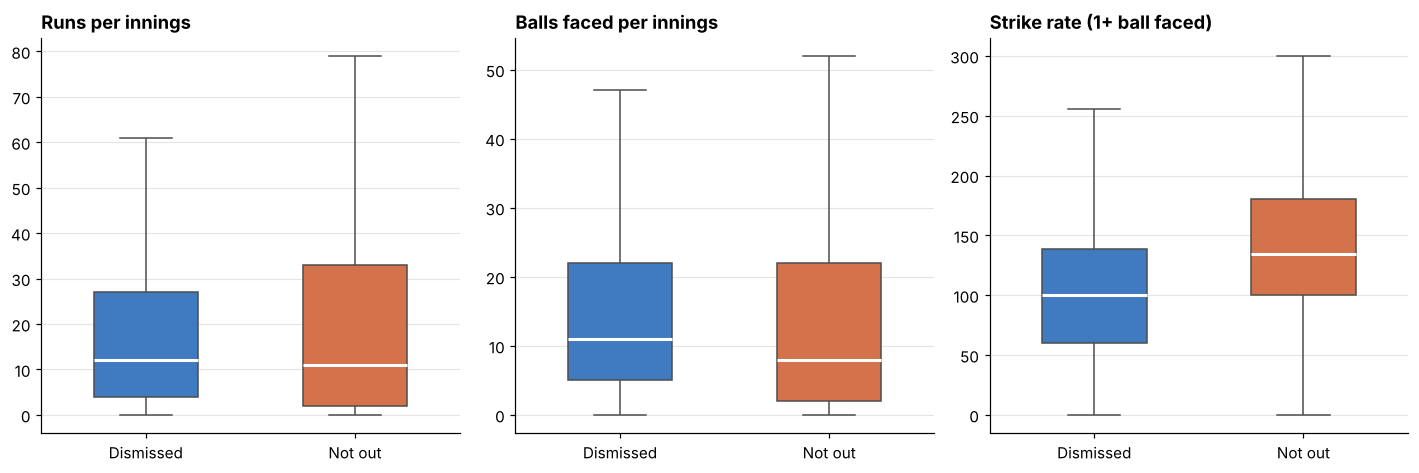

,median not out,median dismissed,chance not-out innings is higher,p-value
measure,,,,
Runs,11.00,12.0,0.498,0.769
Balls faced,8.00,11.0,0.427,<0.001
Strike rate,134.07,100.0,0.662,<0.001


'Chance' is 0.50 when the two groups look alike.


In [71]:
# Distributions: runs, balls and strike rate

STATUS_COLOR = {"Dismissed": BLUE, "Not out": ORANGE}
faced_cmp = cmp[cmp["B"] > 0]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
for ax, (data, col, title) in zip(axes, [(cmp, "R", "Runs per innings"),
                                         (cmp, "B", "Balls faced per innings"),
                                         (faced_cmp, "SR", "Strike rate (1+ ball faced)")]):
    sns.boxplot(data=data, x="status", y=col, order=["Dismissed", "Not out"], hue="status", palette=STATUS_COLOR,
                width=0.5, showfliers=False, legend=False, medianprops={"color": "white", "linewidth": 2}, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

# Rank-based tests (the data is heavily skewed). 'Chance' = probability that a random not-out innings beats a random dismissed one.

rows = []
for name, data, col in [("Runs", cmp, "R"), ("Balls faced", cmp, "B"), ("Strike rate", faced_cmp, "SR")]:
    a, b = data.loc[data["status"] == "Not out", col], data.loc[data["status"] == "Dismissed", col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"measure": name, "median not out": a.median(), "median dismissed": b.median(),
                 "chance not-out innings is higher": u / (len(a) * len(b)),
                 "p-value": "<0.001" if p < 0.001 else f"{p:.3f}"})
display(pd.DataFrame(rows).set_index("measure").round(3))
print("'Chance' is 0.50 when the two groups look alike.")

Strike rate by balls faced:


status,Dismissed,Not out
band,,
1-5,68.3,134.6
6-10,100.1,148.1
11-20,117.8,152.8
21-30,126.2,147.2
31+,135.2,148.3


Number of innings in each cell:


status,Dismissed,Not out
band,,
1-5,2242,920
6-10,1830,441
11-20,2302,439
21-30,1207,245
31+,1194,461


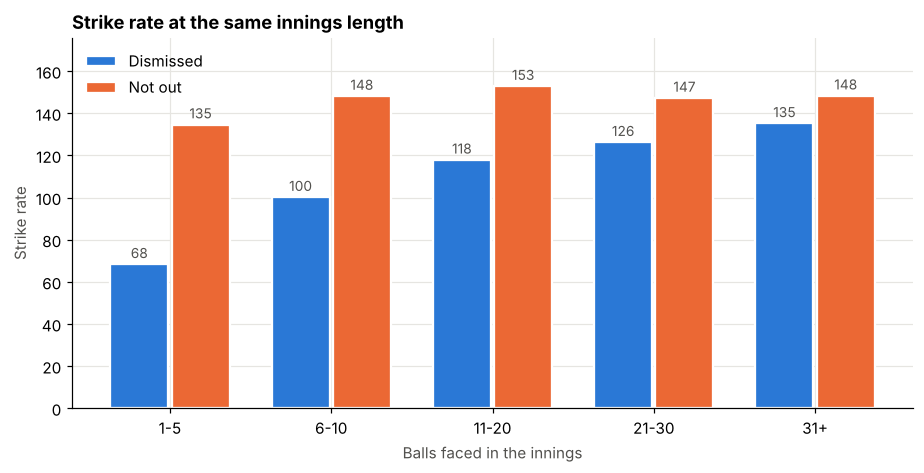

In [72]:
# Fair comparison: same innings length, not-out vs dismissed
# Not-out innings are often very short (the batter was waiting when the innings ended), so compare like with like.

faced_cmp = faced_cmp.assign(band=pd.cut(faced_cmp["B"], bins=[0, 5, 10, 20, 30, 100],
                                          labels=["1-5", "6-10", "11-20", "21-30", "31+"]))
g = faced_cmp.groupby(["band", "status"], observed=True).agg(innings=("R", "size"), runs=("R", "sum"), balls=("B", "sum"))
g["strike_rate"] = g["runs"] / g["balls"] * 100
sr_tab = g["strike_rate"].unstack()[["Dismissed", "Not out"]]
n_tab = g["innings"].unstack()[["Dismissed", "Not out"]]
print("Strike rate by balls faced:")
display(sr_tab.round(1))
print("Number of innings in each cell:")
display(n_tab)

x = np.arange(len(sr_tab))
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for i, status in enumerate(["Dismissed", "Not out"]):
    bars = ax.bar(x + (i - 0.5) * 0.38, sr_tab[status], width=0.36, color=STATUS_COLOR[status], label=status,
                  edgecolor="white", linewidth=1.5)
    ax.bar_label(bars, fmt="%.0f", fontsize=9, color=INK, padding=2)
ax.set_xticks(x)
ax.set_xticklabels(sr_tab.index)
ax.set_xlabel("Balls faced in the innings")
ax.set_ylabel("Strike rate")
ax.set_title("Strike rate at the same innings length")
ax.set_ylim(0, sr_tab.max().max() * 1.15)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

74 batters with 50+ innings. League-wide not-out rate: 23.5%.
Highest not-out rates:


,innings,not_outs,not_out_pct,strike_rate
batsmen,,,,
A Mishra,56,25,44.6,93.1
JA Morkel,68,28,41.2,142.0
PP Chawla,81,32,39.5,111.5
HH Pandya,61,24,39.3,154.8
MS Dhoni,170,65,38.2,137.9
Harbhajan Singh,88,33,37.5,138.2
RA Jadeja,128,48,37.5,122.7
DJ Bravo,102,38,37.3,128.3
P Kumar,59,21,35.6,108.3


Lowest not-out rates:


,innings,not_outs,not_out_pct,strike_rate
batsmen,,,,
Q de Kock,50,2,4.0,131.3
MA Agarwal,72,3,4.2,128.1
KC Sangakkara,68,3,4.4,121.2
BB McCullum,109,5,4.6,131.7
V Sehwag,104,5,4.8,155.4


Not-out rate by role:


,innings,not_out_pct
special_role,,
normal player,9102,25.6
captain,1087,14.3
wicket keeper,1061,14.7
captain & wicket keeper,290,25.5


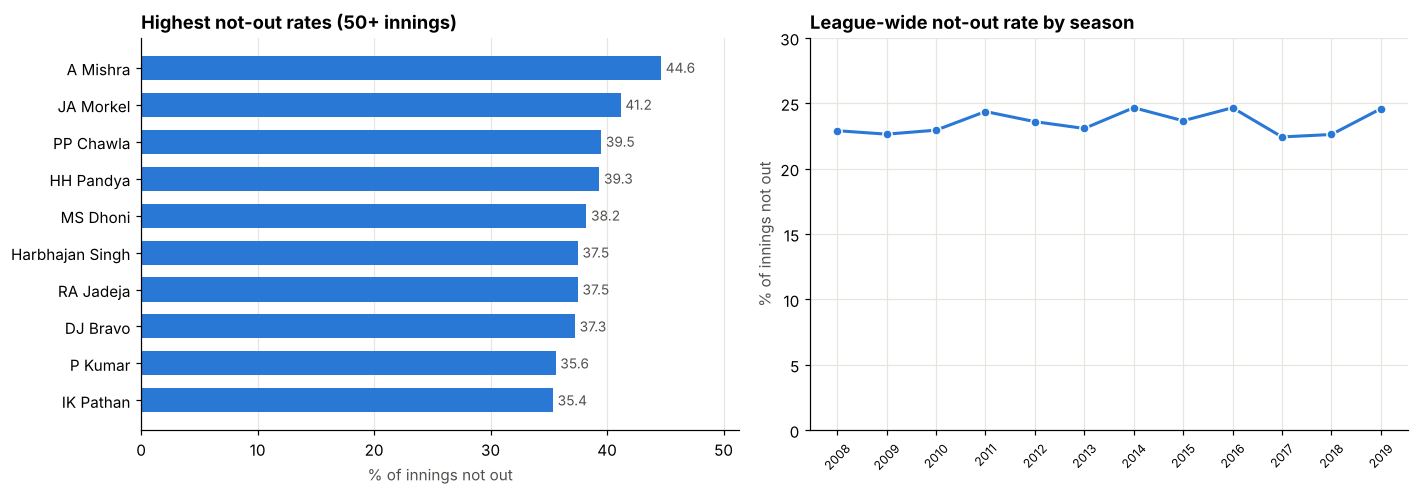

In [73]:
# Who finishes not out? By batter, role and season

by_batter = bat.groupby("batsmen").agg(innings=("R", "size"),
                                       not_outs=("dismissal_mode", lambda x: (x == "not out").sum()),
                                       runs=("R", "sum"), balls=("B", "sum"))
by_batter["not_out_pct"] = by_batter["not_outs"] / by_batter["innings"] * 100
by_batter["strike_rate"] = by_batter["runs"] / by_batter["balls"].replace(0, np.nan) * 100
MIN_INNINGS = 50
q = by_batter[by_batter["innings"] >= MIN_INNINGS]
print(f"{len(q)} batters with {MIN_INNINGS}+ innings. League-wide not-out rate: {(bat['dismissal_mode'] == 'not out').mean() * 100:.1f}%.")
print("Highest not-out rates:")
display(q.nlargest(10, "not_out_pct")[["innings", "not_outs", "not_out_pct", "strike_rate"]].round(1))
print("Lowest not-out rates:")
display(q.nsmallest(5, "not_out_pct")[["innings", "not_outs", "not_out_pct", "strike_rate"]].round(1))

role_no = bat.groupby("special_role")["dismissal_mode"].agg(innings="size", not_out_pct=lambda x: (x == "not out").mean() * 100)
print("Not-out rate by role:")
display(role_no.loc[["normal player", "captain", "wicket keeper", "captain & wicket keeper"]].round(1))

season_no = bat.groupby("season")["dismissal_mode"].apply(lambda x: (x == "not out").mean() * 100)
top_no = q.nlargest(10, "not_out_pct")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
hbar(axes[0], top_no.index, top_no["not_out_pct"], f"Highest not-out rates ({MIN_INNINGS}+ innings)", "% of innings not out", fmt="%.1f")
axes[1].plot(season_no.index, season_no.values, color=BLUE, lw=2, marker="o", ms=6, mec="white")
axes[1].set_title("League-wide not-out rate by season")
axes[1].set_ylabel("% of innings not out")
axes[1].set_ylim(0, 30)
axes[1].set_xticks(season_no.index)
axes[1].tick_params(axis="x", labelsize=8, rotation=45)
plt.tight_layout()
plt.show()

In [74]:
# The biggest innings that ended not out, against the biggest that ended in a dismissal

cols = ["season", "batsmen", "R", "B", "fours", "sixes", "SR", "dismissal_mode", "team_1", "team_2"]
print("Highest scores remaining not out:")
no_top = cmp[cmp["status"] == "Not out"].nlargest(8, "R")[cols]
no_top.index = range(1, len(no_top) + 1)
display(no_top)
print("Highest scores that ended in a dismissal:")
di_top = cmp[cmp["status"] == "Dismissed"].nlargest(8, "R")[cols]
di_top.index = range(1, len(di_top) + 1)
display(di_top)
print(f"Share of 50+ scores that stayed not out: {(cmp.loc[cmp['R'] >= 50, 'status'] == 'Not out').mean() * 100:.1f}% "
      f"(against {(cmp['status'] == 'Not out').mean() * 100:.1f}% of all innings).")

Highest scores remaining not out:


,season,batsmen,R,B,fours,sixes,SR,dismissal_mode,team_1,team_2
1,2013,CH Gayle,175.0,66.0,13.0,17.0,265.15,not out,Royal Challengers Bangalore,Pune Warriors
2,2008,BB McCullum,158.0,73.0,10.0,13.0,216.43,not out,Kolkata Knight Riders,Royal Challengers Bangalore
3,2015,AB de Villiers,133.0,59.0,19.0,4.0,225.42,not out,Royal Challengers Bangalore,Mumbai Indians
4,2016,AB de Villiers,129.0,52.0,10.0,12.0,248.07,not out,Royal Challengers Bangalore,Gujarat Lions
5,2012,CH Gayle,128.0,62.0,7.0,13.0,206.45,not out,Royal Challengers Bangalore,Delhi Daredevils
6,2018,RR Pant,128.0,63.0,15.0,7.0,203.17,not out,Delhi Daredevils,Sunrisers Hyderabad
7,2011,PC Valthaty,120.0,63.0,19.0,2.0,190.47,not out,Chennai Super Kings,Kings XI Punjab
8,2018,SR Watson,117.0,57.0,11.0,8.0,205.26,not out,Sunrisers Hyderabad,Chennai Super Kings


Highest scores that ended in a dismissal:


,season,batsmen,R,B,fours,sixes,SR,dismissal_mode,team_1,team_2
1,2010,M Vijay,127.0,56.0,8.0,11.0,226.78,caught,Chennai Super Kings,Rajasthan Royals
2,2017,DA Warner,126.0,59.0,10.0,8.0,213.55,caught,Sunrisers Hyderabad,Kolkata Knight Riders
3,2014,V Sehwag,122.0,58.0,12.0,8.0,210.34,caught,Kings XI Punjab,Chennai Super Kings
4,2011,V Sehwag,119.0,56.0,13.0,6.0,212.50,caught,Deccan Chargers,Delhi Daredevils
5,2015,CH Gayle,117.0,57.0,7.0,12.0,205.26,caught,Royal Challengers Bangalore,Kings XI Punjab
6,2008,SE Marsh,115.0,69.0,11.0,7.0,166.66,caught,Kings XI Punjab,Rajasthan Royals
7,2019,JM Bairstow,114.0,56.0,12.0,7.0,203.57,caught,Sunrisers Hyderabad,Royal Challengers Bangalore
8,2012,M Vijay,113.0,58.0,15.0,4.0,194.82,run out,Chennai Super Kings,Delhi Daredevils


Share of 50+ scores that stayed not out: 34.8% (against 23.5% of all innings).


# Task 4: Identify unusual performances and outliers.

,innings,Q1,Q3,mild fence,above mild,extreme fence,above extreme,z > 3
Runs,11540.0,3.0,28.0,65.5,512.0,103.0,39.0,184.0
Balls faced,11540.0,5.0,22.0,47.5,398.0,73.0,0.0,127.0
Fours,11540.0,0.0,3.0,7.5,370.0,12.0,25.0,228.0
Sixes,11540.0,0.0,1.0,2.5,961.0,4.0,269.0,269.0
Boundaries (4s + 6s),11540.0,0.0,4.0,10.0,306.0,16.0,37.0,229.0
Strike rate (10+ balls),6220.0,100.0,153.8,234.6,123.0,315.4,13.0,52.0


Scoring is right-skewed (many small scores, a few huge ones), so the mild fence flags a lot of innings;
the extreme fence and the runs-against-balls check below pick out the genuinely exceptional ones.

Slow end: 16 innings of 10+ balls have a strike rate below 19 (the lower fence).


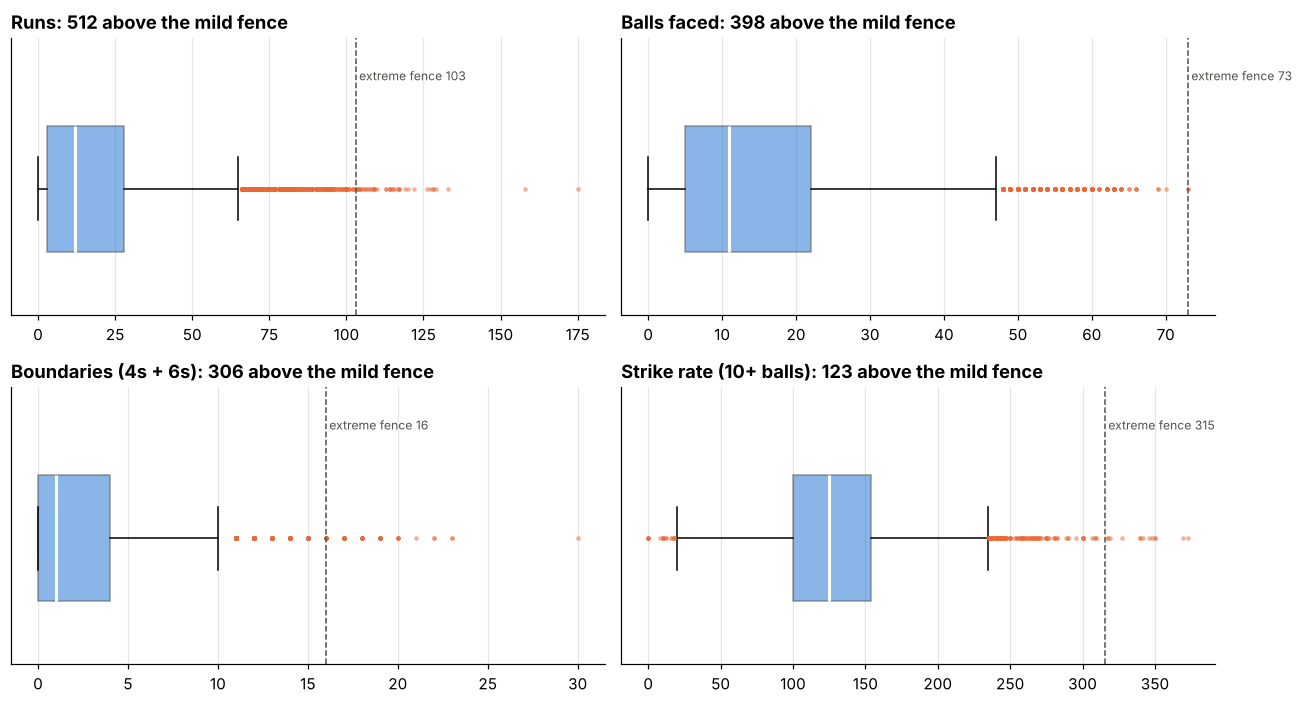

In [75]:
# IQR fences and z-scores for the main measures

bat["boundaries"] = bat["fours"] + bat["sixes"]
measures = {
    "Runs": bat["R"],
    "Balls faced": bat["B"],
    "Fours": bat["fours"],
    "Sixes": bat["sixes"],
    "Boundaries (4s + 6s)": bat["boundaries"],
    "Strike rate (10+ balls)": bat.loc[bat["B"] >= 10, "SR"],
}

def fences(x):
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    return {"innings": len(x), "Q1": q1, "Q3": q3,
            "mild fence": q3 + 1.5 * iqr, "above mild": int((x > q3 + 1.5 * iqr).sum()),
            "extreme fence": q3 + 3 * iqr, "above extreme": int((x > q3 + 3 * iqr).sum()),
            "z > 3": int(((x - x.mean()) / x.std() > 3).sum())}

fence_tbl = pd.DataFrame({k: fences(v) for k, v in measures.items()}).T
display(fence_tbl.round(1))
print("Scoring is right-skewed (many small scores, a few huge ones), so the mild fence flags a lot of innings;")
print("the extreme fence and the runs-against-balls check below pick out the genuinely exceptional ones.")

sr10 = bat.loc[bat["B"] >= 10, "SR"]
q1, q3 = sr10.quantile([0.25, 0.75])
low_sr_fence = q1 - 1.5 * (q3 - q1)
print(f"\nSlow end: {(sr10 < low_sr_fence).sum()} innings of 10+ balls have a strike rate below {low_sr_fence:.0f} (the lower fence).")

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
for ax, name in zip(axes.ravel(), ["Runs", "Balls faced", "Boundaries (4s + 6s)", "Strike rate (10+ balls)"]):
    ax.boxplot(measures[name].dropna(), vert=False, whis=1.5, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor=BLUE, alpha=0.55, edgecolor=INK),
               medianprops=dict(color="white", linewidth=2),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=ORANGE, markeredgecolor="none", alpha=0.5))
    ax.axvline(fence_tbl.loc[name, "extreme fence"], color=INK, ls="--", lw=1)
    ax.set_title(f"{name}: {int(fence_tbl.loc[name, 'above mild'])} above the mild fence")
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
    ax.text(fence_tbl.loc[name, "extreme fence"], 1.42, f" extreme fence {fence_tbl.loc[name, 'extreme fence']:.0f}",
            fontsize=8, color=INK, va="bottom")
    ax.set_ylim(0.5, 1.6)
plt.tight_layout()
plt.show()

Typical innings: runs = -2.4 + 1.44 x balls faced (about 8.6 runs per over)
Far above the pace (z > 3): 156 innings; far below (z < -3): 30 innings

Innings furthest above the usual pace:


,season,batsmen,R,B,SR,expected_runs,z_resid,dismissal_mode
1,2013,CH Gayle,175.0,66.0,265.2,92.4,10.7,not out
2,2016,AB de Villiers,129.0,52.0,248.1,72.3,7.4,not out
3,2008,BB McCullum,158.0,73.0,216.4,102.5,7.2,not out
4,2014,SK Raina,87.0,25.0,348.0,33.5,7.0,run out
5,2015,AB de Villiers,133.0,59.0,225.4,82.3,6.6,not out
6,2010,YK Pathan,100.0,37.0,270.3,50.7,6.4,run out
7,2010,M Vijay,127.0,56.0,226.8,78.0,6.4,caught
8,2013,DA Miller,101.0,38.0,265.8,52.2,6.3,not out
9,2008,ST Jayasuriya,114.0,48.0,237.5,66.5,6.2,not out
10,2019,HH Pandya,91.0,34.0,267.6,46.4,5.8,caught


Innings furthest below the usual pace (many balls, few runs):


,season,batsmen,R,B,SR,expected_runs,z_resid,dismissal_mode
1,2010,KD Karthik,17.0,35.0,48.6,47.9,-4.0,caught
2,2013,MEK Hussey,40.0,51.0,78.4,70.9,-4.0,caught
3,2019,AT Rayudu,28.0,42.0,66.7,57.9,-3.9,bowled
4,2009,JP Duminy,59.0,63.0,93.6,88.1,-3.8,caught
5,2013,DR Smith,47.0,53.0,88.7,73.7,-3.5,caught
6,2008,SC Ganguly,14.0,30.0,46.7,40.7,-3.5,bowled
7,2012,JEC Franklin,32.0,42.0,76.2,57.9,-3.4,caught
8,2008,GC Smith,35.0,44.0,79.5,60.8,-3.4,not out


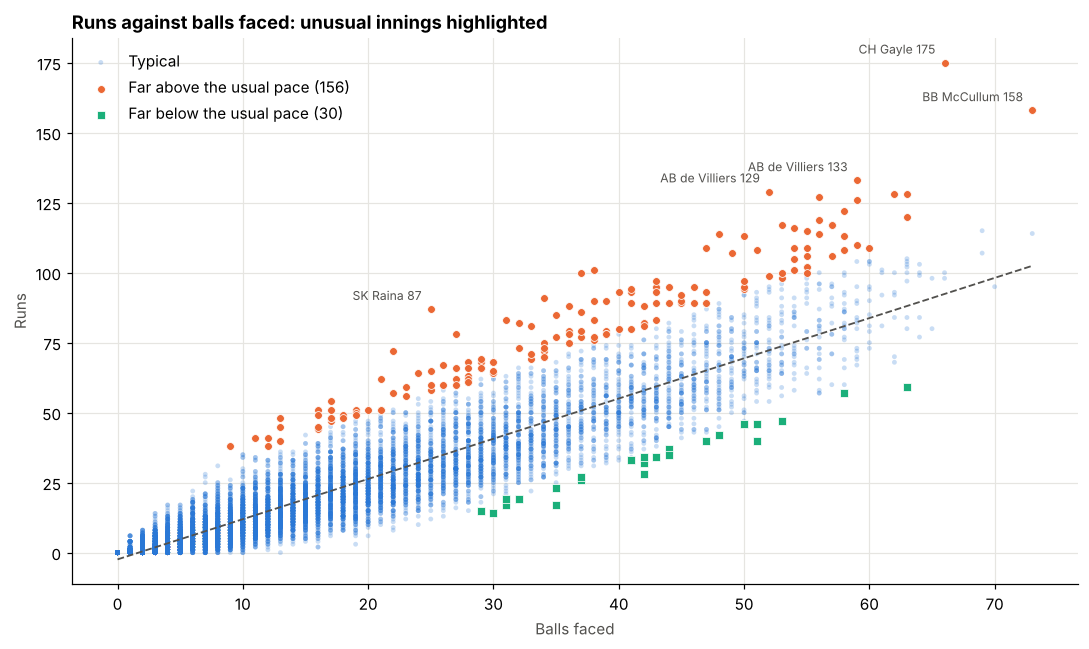

In [76]:
# Runs against balls: Which innings beat or missed the usual pace by a wide margin?

slope, intercept = np.polyfit(bat["B"], bat["R"], 1)
bat["expected_runs"] = intercept + slope * bat["B"]
bat["resid"] = bat["R"] - bat["expected_runs"]
bat["z_resid"] = bat["resid"] / bat["resid"].std()
print(f"Typical innings: runs = {intercept:.1f} + {slope:.2f} x balls faced (about {slope * 6:.1f} runs per over)")
print(f"Far above the pace (z > 3): {(bat['z_resid'] > 3).sum()} innings; far below (z < -3): {(bat['z_resid'] < -3).sum()} innings")

cols = ["season", "batsmen", "R", "B", "SR", "expected_runs", "z_resid", "dismissal_mode"]
print("\nInnings furthest above the usual pace:")
top_over = bat.nlargest(10, "z_resid")[cols]
top_over.index = range(1, 11)
display(top_over.round(1))
print("Innings furthest below the usual pace (many balls, few runs):")
top_under = bat.nsmallest(8, "z_resid")[cols]
top_under.index = range(1, 9)
display(top_under.round(1))

fig, ax = plt.subplots(figsize=(10, 6))
typical = bat[bat["z_resid"].abs() <= 3]
over, under = bat[bat["z_resid"] > 3], bat[bat["z_resid"] < -3]
ax.scatter(typical["B"], typical["R"], s=10, alpha=0.25, color=BLUE, edgecolors="none", label="Typical")
ax.scatter(over["B"], over["R"], s=26, color=ORANGE, edgecolor="white", linewidth=0.5, label=f"Far above the usual pace ({len(over)})")
ax.scatter(under["B"], under["R"], s=26, color=AQUA, edgecolor="white", linewidth=0.5, marker="s", label=f"Far below the usual pace ({len(under)})")
xs = np.array([0, bat["B"].max()])
ax.plot(xs, intercept + slope * xs, color=INK, ls="--", lw=1.2)
for _, r in bat.nlargest(5, "z_resid").iterrows():
    ax.annotate(f"{r['batsmen']} {int(r['R'])}", (r["B"], r["R"]), textcoords="offset points", xytext=(-6, 6),
                fontsize=8, color=INK, ha="right")
ax.set_title("Runs against balls faced: unusual innings highlighted")
ax.set_xlabel("Balls faced")
ax.set_ylabel("Runs")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

58 hundreds in 11,540 innings (0.50%).
Innings flagged, by reason (an innings can have several):


,innings
extreme runs,39
extreme sixes,269
extreme fours,25
extreme strike rate,13
far above usual pace,156
far below usual pace,30


359 innings flagged in total (3.1% of all innings).


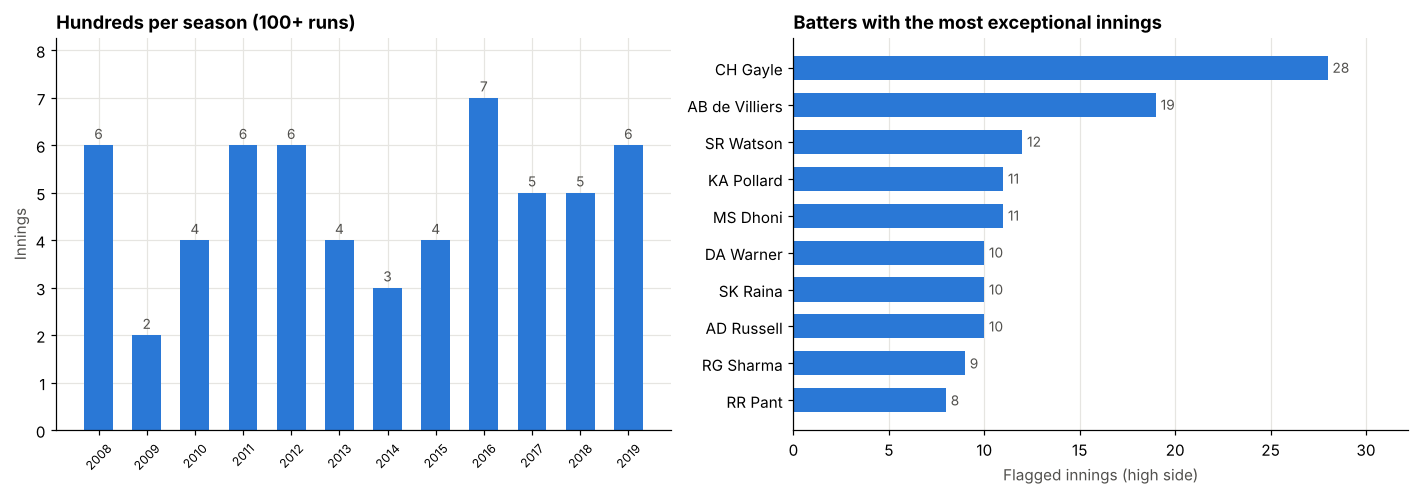

In [77]:
# Exceptional innings: how often, who, and when

HUNDRED = 100
hundreds = bat[bat["R"] >= HUNDRED]
per_season = hundreds.groupby("season").size().reindex(sorted(bat["season"].unique()), fill_value=0)
print(f"{len(hundreds)} hundreds in {len(bat):,} innings ({len(hundreds) / len(bat) * 100:.2f}%).")

flags = pd.DataFrame({
    "extreme runs": bat["R"] > fence_tbl.loc["Runs", "extreme fence"],
    "extreme sixes": bat["sixes"] > fence_tbl.loc["Sixes", "extreme fence"],
    "extreme fours": bat["fours"] > fence_tbl.loc["Fours", "extreme fence"],
    "extreme strike rate": (bat["B"] >= 10) & (bat["SR"] > fence_tbl.loc["Strike rate (10+ balls)", "extreme fence"]),
    "far above usual pace": bat["z_resid"] > 3,
    "far below usual pace": bat["z_resid"] < -3,
})
bat["outlier_reasons"] = flags.apply(lambda r: "; ".join(r.index[r.values]), axis=1)
bat["is_outlier"] = flags.any(axis=1)
bat["is_high_outlier"] = flags.drop(columns="far below usual pace").any(axis=1)
print("Innings flagged, by reason (an innings can have several):")
display(flags.sum().rename("innings").to_frame())
print(f"{bat['is_outlier'].sum()} innings flagged in total ({bat['is_outlier'].mean() * 100:.1f}% of all innings).")

repeat = (bat[bat["is_high_outlier"]].groupby("batsmen").size().sort_values(ascending=False).head(10))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
bars = axes[0].bar(per_season.index.astype(str), per_season.values, color=BLUE, width=0.6)
axes[0].bar_label(bars, fmt="%d", fontsize=9, color=INK, padding=2)
axes[0].set_title(f"Hundreds per season ({HUNDRED}+ runs)")
axes[0].set_ylabel("Innings")
axes[0].tick_params(axis="x", labelsize=8, rotation=45)
axes[0].set_ylim(0, per_season.max() * 1.18)
hbar(axes[1], repeat.index, repeat.values, "Batters with the most exceptional innings", "Flagged innings (high side)")
plt.tight_layout()
plt.show()

In [78]:
# Fastest big innings and slowest long innings

cols = ["season", "batsmen", "R", "B", "fours", "sixes", "SR", "dismissal_mode"]
print("Fastest innings of 50+ runs:")
fast = bat[bat["R"] >= 50].nlargest(10, "SR")[cols]
fast.index = range(1, 11)
display(fast)
print("Slowest innings of 30+ balls:")
slow = bat[bat["B"] >= 30].nsmallest(10, "SR")[cols]
slow.index = range(1, 11)
display(slow)
print("Highest strike rates in a short innings are not meaningful on their own, for example:")
display(bat.nlargest(3, "SR")[cols].reset_index(drop=True))

Fastest innings of 50+ runs:


,season,batsmen,R,B,fours,sixes,SR,dismissal_mode
1,2014,SK Raina,87.0,25.0,12.0,6.0,348.00,run out
2,2014,YK Pathan,72.0,22.0,5.0,7.0,327.27,caught
3,2018,KL Rahul,51.0,16.0,6.0,4.0,318.75,caught
4,2017,SP Narine,54.0,17.0,6.0,4.0,317.64,caught
5,2016,KA Pollard,51.0,17.0,2.0,6.0,300.00,not out
6,2018,Ishan Kishan,62.0,21.0,5.0,6.0,295.23,caught
7,2019,RR Pant,78.0,27.0,7.0,7.0,288.88,not out
8,2010,YK Pathan,100.0,37.0,9.0,8.0,270.27,run out
9,2014,DA Miller,51.0,19.0,0.0,6.0,268.42,not out
10,2019,KA Pollard,83.0,31.0,3.0,10.0,267.74,caught


Slowest innings of 30+ balls:


,season,batsmen,R,B,fours,sixes,SR,dismissal_mode
1,2008,SC Ganguly,14.0,30.0,1.0,0.0,46.66,bowled
2,2010,KD Karthik,17.0,35.0,1.0,0.0,48.57,caught
3,2010,ML Hayden,17.0,31.0,1.0,1.0,54.83,caught
4,2009,Yuvraj Singh,18.0,31.0,1.0,0.0,58.06,caught
5,2012,MEK Hussey,19.0,32.0,2.0,0.0,59.37,run out
6,2010,JH Kallis,19.0,32.0,3.0,0.0,59.37,caught
7,2009,BB McCullum,19.0,31.0,1.0,0.0,61.29,caught
8,2008,RT Ponting,19.0,31.0,1.0,0.0,61.29,run out
9,2011,RA Jadeja,23.0,35.0,2.0,0.0,65.71,caught
10,2014,SPD Smith,22.0,33.0,0.0,0.0,66.66,caught


Highest strike rates in a short innings are not meaningful on their own, for example:


,season,batsmen,R,B,fours,sixes,SR,dismissal_mode
0,2011,DJ Bravo,6.0,1.0,0.0,1.0,600.0,not out
1,2012,R Vinay Kumar,6.0,1.0,0.0,1.0,600.0,not out
2,2014,R Bhatia,6.0,1.0,0.0,1.0,600.0,not out


In [79]:
# Make sure the outliers are real, then record the decision

checks = pd.Series({
    "runs scored without facing a ball": int(((bat["R"] > 0) & (bat["B"] == 0)).sum()),
    "boundary runs larger than total runs": int(((bat["fours"] * 4 + bat["sixes"] * 6) > bat["R"]).sum()),
    "more than 6 runs per ball faced": int((bat["R"] > 6 * bat["B"]).sum()),
    "strike rate disagrees with runs / balls": int((((bat["R"] / bat["B"].replace(0, np.nan) * 100) - bat["SR"]).abs() > 0.1).sum()),
}, name="innings failing")
display(checks.to_frame())
print("No impossible values, so every flagged innings is a genuine performance. Decision: keep them in the data and use the flags.")

# Re-create bat from ipl_cricket using 'dismissal_mode' to filter out 'absent hurt' rows safely
bat_updated = ipl_cricket[ipl_cricket["dismissal_mode"] != "absent hurt"].copy()
bat_updated["boundaries"] = bat["boundaries"]
bat_updated["expected_runs"] = bat["expected_runs"]
bat_updated["resid"] = bat["resid"]
bat_updated["z_resid"] = bat["z_resid"]
bat_updated["outlier_reasons"] = bat["outlier_reasons"]
bat_updated["is_outlier"] = bat["is_outlier"]
bat_updated["is_high_outlier"] = bat["is_high_outlier"]

flag_cols = ["match_id", "season", "match_date", "stage", "batsmen", "R", "B", "fours", "sixes", "SR",
             "dismissal_mode", "z_resid", "outlier_reasons"]
outlier_innings = bat_updated.loc[bat_updated["is_outlier"], flag_cols].sort_values("z_resid", ascending=False)


,innings failing
runs scored without facing a ball,0
boundary runs larger than total runs,0
more than 6 runs per ball faced,0
strike rate disagrees with runs / balls,0


No impossible values, so every flagged innings is a genuine performance. Decision: keep them in the data and use the flags.


# Key Findings and Saved Output (Objective 3)

In [80]:
# Key Findings:

top_mode = mix.idxmax()
print(f"TASK 1  {mix[top_mode] / mix.sum() * 100:.1f}% of dismissals are '{top_mode}'; run outs {mix['run out'] / mix.sum() * 100:.1f}%, "
      f"bowled {mix['bowled'] / mix.sum() * 100:.1f}%, lbw {mix['lbw'] / mix.sum() * 100:.1f}%, stumped {mix['stumped'] / mix.sum() * 100:.1f}%.")
print(f"        Run outs make up {duck_vs_all.loc['Run out', '% of ducks']:.1f}% of ducks against {duck_vs_all.loc['Run out', '% of all dismissals']:.1f}% of all dismissals; "
      f"caught share is {band_mix.loc['50+', 'caught']:.0f}% when out on 50+ against {band_mix.loc['1-9', 'caught']:.0f}% when out on 1-9.")
print(f"        Run outs fell from {season_mix.iloc[0]['run out']:.1f}% of dismissals in {season_mix.index[0]} to {season_mix.iloc[-1]['run out']:.1f}% in {season_mix.index[-1]}, "
      f"while 'caught' rose from {season_mix.iloc[0]['caught']:.1f}% to {season_mix.iloc[-1]['caught']:.1f}%.")
print(f"        {len(ducks):,} ducks ({len(ducks) / len(bat) * 100:.1f}% of innings); most by {most_ducks.index[0]} ({int(most_ducks.iloc[0]['ducks'])}).")

tb = mark(top_bowlers.index[:3], top_bowlers)
print(f"TASK 2  Most wickets (clear names): {tb[0]} with {int(top_bowlers.iloc[0]['wickets'])}, then {tb[1]} ({int(top_bowlers.iloc[1]['wickets'])}) and {tb[2]} ({int(top_bowlers.iloc[2]['wickets'])}).  † = surname shared by two batters, so the count may combine two bowlers.")
print(f"        {len(amb)} surname labels ({amb['wickets'].sum() / bowlers['wickets'].sum() * 100:.0f}% of wickets) cannot be traced to one bowler.")
print(f"        Best non-keeping fielder: {top_field.index[0]} ({int(top_field.iloc[0]['catches_and_run_outs'])} catches + run-out involvements); "
      f"top keeper: {top_keepers.index[0]} ({int(top_keepers.iloc[0]['keeper_dismissals'])} dismissals, {int(top_keepers.iloc[0]['stumpings'])} stumpings).")

print(f"TASK 3  Not-out innings average {prof.loc['Not out', 'mean_runs']:.1f} runs vs {prof.loc['Dismissed', 'mean_runs']:.1f} for dismissed, "
      f"but the medians are {prof.loc['Not out', 'median_runs']:.0f} and {prof.loc['Dismissed', 'median_runs']:.0f}; "
      f"strike rate {prof.loc['Not out', 'strike_rate']:.1f} vs {prof.loc['Dismissed', 'strike_rate']:.1f}.")
print(f"        Highest not-out rate ({MIN_INNINGS}+ innings): {top_no.index[0]} at {top_no.iloc[0]['not_out_pct']:.1f}% (league {(bat['dismissal_mode'] == 'not out').mean() * 100:.1f}%).")

print(f"TASK 4  {bat['is_outlier'].sum()} innings flagged ({bat['is_outlier'].mean() * 100:.1f}%); {int(flags['extreme runs'].sum())} have extreme runs (more than {fence_tbl.loc['Runs', 'extreme fence']:.0f}), "
      f"{int(flags['far above usual pace'].sum())} are far above the usual pace for their balls faced.")
print(f"        Biggest outlier: {bat.loc[bat['z_resid'].idxmax(), 'batsmen']} {int(bat.loc[bat['z_resid'].idxmax(), 'R'])} off {int(bat.loc[bat['z_resid'].idxmax(), 'B'])}; "
      f"most exceptional innings: {repeat.index[0]} ({int(repeat.iloc[0])}).")

TASK 1  63.0% of dismissals are 'caught'; run outs 9.6%, bowled 17.9%, lbw 6.1%, stumped 3.2%.
        Run outs make up 11.7% of ducks against 9.6% of all dismissals; caught share is 69% when out on 50+ against 61% when out on 1-9.
        Run outs fell from 12.3% of dismissals in 2008 to 6.0% in 2019, while 'caught' rose from 61.1% to 71.4%.
        881 ducks (7.6% of innings); most by Harbhajan Singh (13).
TASK 2  Most wickets (clear names): Malinga with 170, then Morkel† (162) and Mishra† (154).  † = surname shared by two batters, so the count may combine two bowlers.
        9 surname labels (14% of wickets) cannot be traced to one bowler.
        Best non-keeping fielder: Raina (118 catches + run-out involvements); top keeper: Dhoni (132 dismissals, 38 stumpings).
TASK 3  Not-out innings average 21.5 runs vs 18.5 for dismissed, but the medians are 11 and 12; strike rate 148.0 vs 121.6.
        Highest not-out rate (50+ innings): A Mishra at 44.6% (league 23.5%).
TASK 4  359 inning

In [81]:
# Savd Reports

bowlers.sort_values("wickets", ascending=False).round(2).to_csv("ipl_bowler_summary.csv")
fielders.sort_values("total_involved", ascending=False).to_csv("ipl_fielder_summary.csv")
outlier_innings.round(2).to_csv("ipl_outlier_innings.csv", index=False)
print(f"ipl_bowler_summary.csv  : {len(bowlers)} bowler labels")
print(f"ipl_fielder_summary.csv : {len(fielders)} fielder labels")
print(f"ipl_outlier_innings.csv : {len(outlier_innings)} flagged innings")

ipl_bowler_summary.csv  : 342 bowler labels
ipl_fielder_summary.csv : 500 fielder labels
ipl_outlier_innings.csv : 359 flagged innings


# Objective 4: Generate Overall Insights

# Task 1: Compare team performance

In [82]:
# Work out the batting team for every row

def fielding_labels(r):
    """Names of the bowler/fielders credited in this row's dismissal (they belong to the batting team's opponents)."""

    out = []

    if isinstance(r.bowler_name, str):
        out.append(r.bowler_name)

    if isinstance(r.fielder, str):
        out.append(r.fielder)

    if isinstance(r.runout_fielders, str):
        out += [x.strip() for x in re.sub(r"sub \((.+?)\)", r"\1", r.runout_fielders).split("/")]
    return out

ipl_cricket["fielding_labels"] = [fielding_labels(r) for r in ipl_cricket.itertuples()]

# Create the missing 'batted' column
ipl_cricket["batted"] = ipl_cricket["dismissal_mode"] != "absent hurt"

# Create 'dismissed' column representing whether the batter was dismissed
ipl_cricket["dismissed"] = ~ipl_cricket["dismissal_mode"].isin(["not out", "retired", "absent hurt"])

# Create 'pos' column representing position within the match
ipl_cricket["pos"] = ipl_cricket.groupby("match_id").cumcount()

def surname_match(label, batter):
    return batter == label or batter.endswith(" " + label)

def split_scores(g, usual=None):
    """Score every possible cut of a match into two innings (higher = more plausible)."""
    n = len(g)
    names, labs, modes = g["batsmen"].tolist(), g["fielding_labels"].tolist(), g["dismissal_mode"].tolist()
    balls = np.where(g["batted"], g["B"], 0).astype(float)      # balls faced, 0 for 'absent hurt' rows
    batted = g["batted"].to_numpy().astype(int)
    t1, t2, season = g["team_1"].iloc[0], g["team_2"].iloc[0], g["season"].iloc[0]
    points = np.zeros((n, n))                     # points[i, j] = 1 if row i's bowler/fielder name matches batter j
    for i in range(n):
        for lab in labs[i]:
            for j in range(n):
                if i != j and surname_match(lab, names[j]):
                    points[i, j] += 1
    scores = {}
    for k in range(2, n - 1):                     # innings 1 = rows [0, k), innings 2 = rows [k, n)
        if k > 12 or n - k > 12:                  # an innings has at most 11 batters (+1 absent-hurt row)
            continue
        across = points[:k, k:].sum() + points[k:, :k].sum()
        same_side = points[:k, :k].sum() + points[k:, k:].sum()
        extra_not_outs = max(0, modes[:k].count("not out") - 2) + max(0, modes[k:].count("not out") - 2)
        score = across - same_side - 3 * extra_not_outs + 0.01 * (modes[k - 1] == "not out")
        for part_balls, part_batters in ((balls[:k], batted[:k]), (balls[k:], batted[k:])):
            if part_balls.sum() > 126 or part_batters.sum() > 11:   # a T20 innings has at most 120 legal balls (+ a few no-balls) and 11 batters
                score -= 20
        if usual:                                 # second pass: agree with the batter's usual team that season
            for i, name in enumerate(names):
                team = usual.get((season, name))
                if team == (t1 if i < k else t2):
                    score += 0.5
                elif team in (t1, t2):
                    score -= 0.5
        scores[k] = score
    return scores

def assign_teams(frame, split_at):
    k = frame["match_id"].map(split_at)
    innings_no = np.where(frame["pos"] < k, 1, 2)
    return (innings_no,
            np.where(innings_no == 1, frame["team_1"], frame["team_2"]),
            np.where(innings_no == 1, frame["team_2"], frame["team_1"]))

def usual_team(frame):
    c = (frame.groupby(["season", "batsmen", "bat_team"]).size().rename("n").reset_index()
              .sort_values("n", ascending=False).drop_duplicates(["season", "batsmen"]))
    return c.set_index(["season", "batsmen"])["bat_team"].to_dict()

groups = dict(list(ipl_cricket.groupby("match_id")))

split_at = {}
for mid, g in groups.items():                                          # pass 1: names only
    sc = split_scores(g)
    split_at[mid] = max(sc, key=sc.get) if sc else len(g) // 2
ipl_cricket["innings_no"], ipl_cricket["bat_team"], ipl_cricket["bowl_team"] = assign_teams(ipl_cricket, split_at)

usual = usual_team(ipl_cricket)
for mid, g in groups.items():                                          # pass 2: names + usual team
    sc = split_scores(g, usual)
    split_at[mid] = max(sc, key=sc.get) if sc else len(g) // 2
ipl_cricket["innings_no"], ipl_cricket["bat_team"], ipl_cricket["bowl_team"] = assign_teams(ipl_cricket, split_at)

usual = usual_team(ipl_cricket)
agrees = pd.Series(list(zip(ipl_cricket["season"], ipl_cricket["batsmen"]))).map(usual).values == ipl_cricket["bat_team"].values
print(f"Innings cut found for {len(split_at)} matches.")
print(f"Check: {agrees.mean() * 100:.2f}% of rows put the batter in his usual team for that season "
      f"({int((~agrees).sum())} rows in {ipl_cricket.loc[~agrees, 'match_id'].nunique()} matches differ; these are mid-season transfers or a cut that is one row off).")
display(ipl_cricket[["match_id", "season", "innings_no", "bat_team", "bowl_team", "batsmen", "R", "dismissal_mode"]].head(6))

bat = ipl_cricket[ipl_cricket["batted"]].copy()
dis = bat[bat["dismissed"]].copy()

Innings cut found for 756 matches.
Check: 99.88% of rows put the batter in his usual team for that season (14 rows in 11 matches differ; these are mid-season transfers or a cut that is one row off).


,match_id,season,innings_no,bat_team,bowl_team,batsmen,R,dismissal_mode
0,1,2009,1,Mumbai Indians,Chennai Super Kings,ST Jayasuriya,26,caught
1,1,2009,1,Mumbai Indians,Chennai Super Kings,SR Tendulkar,59,not out
2,1,2009,1,Mumbai Indians,Chennai Super Kings,S Dhawan,22,caught
3,1,2009,1,Mumbai Indians,Chennai Super Kings,JP Duminy,9,caught
4,1,2009,1,Mumbai Indians,Chennai Super Kings,DJ Bravo,5,caught
5,1,2009,1,Mumbai Indians,Chennai Super Kings,AM Nayar,35,caught


In [83]:
# One row per team innings, and flag rain-shortened matches

# Ensure the boolean helper columns are present in bat

bat["is_fifty"] = bat["R"].between(50, 99)
bat["is_hundred"] = bat["R"] >= 100

team_inn_all = (bat.groupby(["match_id", "innings_no"])
               .agg(season=("season", "first"), bat_team=("bat_team", "first"), bowl_team=("bowl_team", "first"),
                    runs=("R", "sum"), balls=("B", "sum"), wickets=("dismissed", "sum"), batters=("R", "size"),
                    fours=("fours", "sum"), sixes=("sixes", "sum"), fifties=("is_fifty", "sum"), hundreds=("is_hundred", "sum"))
               .reset_index())

team_inn_all["strike_rate"] = team_inn_all["runs"] / team_inn_all["balls"] * 100

# A full innings uses (nearly) all 120 balls or loses all 10 wickets. Short innings that did neither were cut by rain or a reduced-overs
# game, and a chase that stopped 20+ runs short of the target without being bowled out was curtailed. Both would distort team averages.

w = team_inn_all.pivot(index="match_id", columns="innings_no", values=["runs", "balls", "wickets"])

short_first = (w[("balls", 1)] < 108) & (w[("wickets", 1)] < 10)

curtailed_chase = (w[("wickets", 2)] < 10) & (w[("balls", 2)] < 114) & (w[("runs", 2)] + 20 < w[("runs", 1)])

shortened = short_first | curtailed_chase

team_inn_all["shortened"] = team_inn_all["match_id"].map(shortened)

team_inn = team_inn_all[~team_inn_all["shortened"]].copy()      # used for every team comparison below

print(f"{int(shortened.sum())} of {len(shortened)} matches look rain-shortened or curtailed and are left out of the team comparisons "
      f"(they stay in all batter statistics).")

print(f"{len(team_inn):,} team innings from {team_inn['match_id'].nunique()} full-length matches are compared.")

display(team_inn[["runs", "balls", "wickets", "fours", "sixes", "strike_rate"]].describe().T.round(1))

display(team_inn.sort_values("runs", ascending=False).head(5)[["season", "bat_team", "bowl_team", "runs", "balls", "wickets", "sixes"]])

35 of 756 matches look rain-shortened or curtailed and are left out of the team comparisons (they stay in all batter statistics).
1,442 team innings from 721 full-length matches are compared.


,count,mean,std,min,25%,50%,75%,max
runs,1442.0,148.6,29.0,42.0,130.0,150.0,168.0,252.0
balls,1442.0,116.5,9.1,34.0,117.0,120.0,120.0,125.0
wickets,1442.0,5.9,2.4,0.0,4.0,6.0,8.0,10.0
fours,1442.0,13.6,4.1,1.0,11.0,13.0,16.0,31.0
sixes,1442.0,5.5,3.2,0.0,3.0,5.0,7.0,21.0
strike_rate,1442.0,127.5,23.2,53.3,111.0,128.2,142.5,213.6


,season,bat_team,bowl_team,runs,balls,wickets,sixes
468,2013,Royal Challengers Bangalore,Pune Warriors,252,124,6,21
884,2016,Royal Challengers Bangalore,Gujarat Lions,244,121,3,20
1122,2018,Kolkata Knight Riders,Kings XI Punjab,240,120,6,15
1338,2010,Chennai Super Kings,Rajasthan Royals,240,120,5,17
1398,2008,Chennai Super Kings,Kings XI Punjab,234,121,5,16


,innings,seasons,runs_per_innings,strike_rate,runs_per_wicket,wickets_lost_per_innings,fours_per_innings,sixes_per_innings,boundary_pct,highest_total,hundreds
bat_team,,,,,,,,,,,
Gujarat Lions,30,2,154.2,134.2,24.7,6.2,15.3,5.2,59.9,203,0
Chennai Super Kings,158,10,153.0,129.8,29.2,5.2,13.4,6.0,58.8,240,8
Rising Pune Supergiant,27,2,151.3,130.4,27.8,5.4,12.6,5.6,55.6,188,2
Kings XI Punjab,169,12,150.8,128.9,24.4,6.2,14.0,5.6,59.3,221,11
Royal Challengers Bangalore,170,12,150.3,129.9,25.6,5.9,13.2,6.3,60.5,252,12
Sunrisers Hyderabad,103,7,149.8,127.9,26.7,5.6,13.5,4.9,55.8,229,3
Mumbai Indians,184,12,149.1,127.7,25.1,5.9,13.8,5.8,60.5,215,4
Kolkata Knight Riders,163,12,148.6,127.8,26.0,5.7,14.1,5.4,59.6,240,1
Delhi Capitals,165,12,146.4,126.8,24.4,6.0,13.8,5.1,58.5,215,8


Teams with fewer than 40 innings are shown but are a small sample and are not named best or weakest: Gujarat Lions, Rising Pune Supergiant, Kochi Tuskers Kerala.


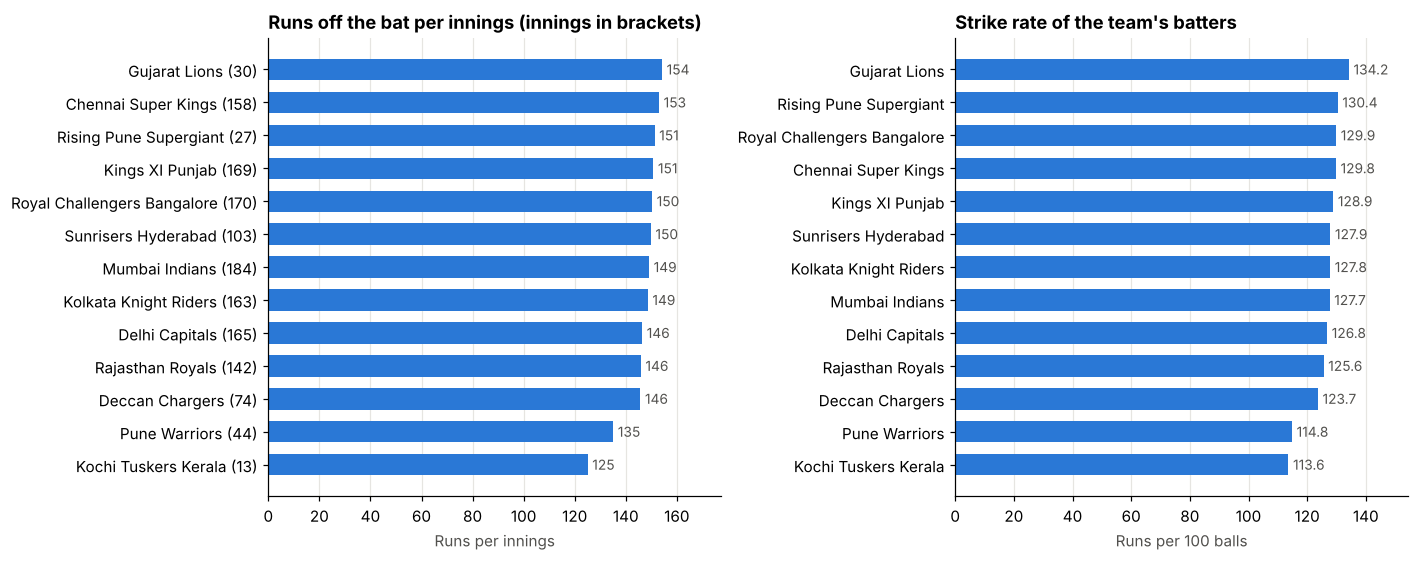

In [84]:
# Batting: how do the teams score?

batting = team_inn.groupby("bat_team").agg(
    innings=("runs", "size"), runs=("runs", "sum"), balls=("balls", "sum"), wickets=("wickets", "sum"),
    fours=("fours", "sum"), sixes=("sixes", "sum"), fifties=("fifties", "sum"), hundreds=("hundreds", "sum"),
    highest_total=("runs", "max"), seasons=("season", "nunique"), runs_std=("runs", "std"))

batting["runs_per_innings"] = batting["runs"] / batting["innings"]

batting["strike_rate"] = batting["runs"] / batting["balls"] * 100

batting["runs_per_wicket"] = batting["runs"] / batting["wickets"]

batting["wickets_lost_per_innings"] = batting["wickets"] / batting["innings"]

batting["fours_per_innings"] = batting["fours"] / batting["innings"]

batting["sixes_per_innings"] = batting["sixes"] / batting["innings"]

batting["boundary_pct"] = (batting["fours"] * 4 + batting["sixes"] * 6) / batting["runs"] * 100

batting = batting.sort_values("runs_per_innings", ascending=False)

display(batting[["innings", "seasons", "runs_per_innings", "strike_rate", "runs_per_wicket", "wickets_lost_per_innings",
                 "fours_per_innings", "sixes_per_innings", "boundary_pct", "highest_total", "hundreds"]].round(1))

small = batting.index[batting["innings"] < MIN_TEAM_INNINGS].tolist()

print(f"Teams with fewer than {MIN_TEAM_INNINGS} innings are shown but are a small sample and are not named best or weakest: {', '.join(small)}.")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

hbar(axes[0], [f"{t} ({int(n)})" for t, n in zip(batting.index, batting["innings"])], batting["runs_per_innings"],
     "Runs off the bat per innings (innings in brackets)", "Runs per innings", fmt="%.0f")

sr_order = batting.sort_values("strike_rate", ascending=False)

hbar(axes[1], sr_order.index, sr_order["strike_rate"], "Strike rate of the team's batters", "Runs per 100 balls", fmt="%.1f")

plt.tight_layout()

plt.show()

,innings,runs_per_innings,runs_conceded_per_innings,wickets_per_innings,runs_per_wicket,balls_per_wicket,net_runs_per_innings
bat_team,,,,,,,
Chennai Super Kings,158,153.0,146.4,6.3,23.2,18.5,6.6
Mumbai Indians,184,149.1,145.5,6.0,24.1,19.3,3.6
Rising Pune Supergiant,27,151.3,149.8,6.4,23.4,18.2,1.5
Kolkata Knight Riders,163,148.6,147.6,5.8,25.4,20.0,1.0
Rajasthan Royals,142,145.9,145.2,5.8,25.0,19.9,0.7
Sunrisers Hyderabad,103,149.8,149.4,6.1,24.4,19.2,0.4
Deccan Chargers,74,145.7,146.8,5.9,24.9,19.8,-1.1
Royal Challengers Bangalore,170,150.3,151.6,5.8,26.2,20.2,-1.3
Kings XI Punjab,169,150.8,152.9,5.7,26.9,20.4,-2.1


net_runs_per_innings = runs scored minus runs conceded off the bat, per innings. It is a rough guide to strength, not a win record.


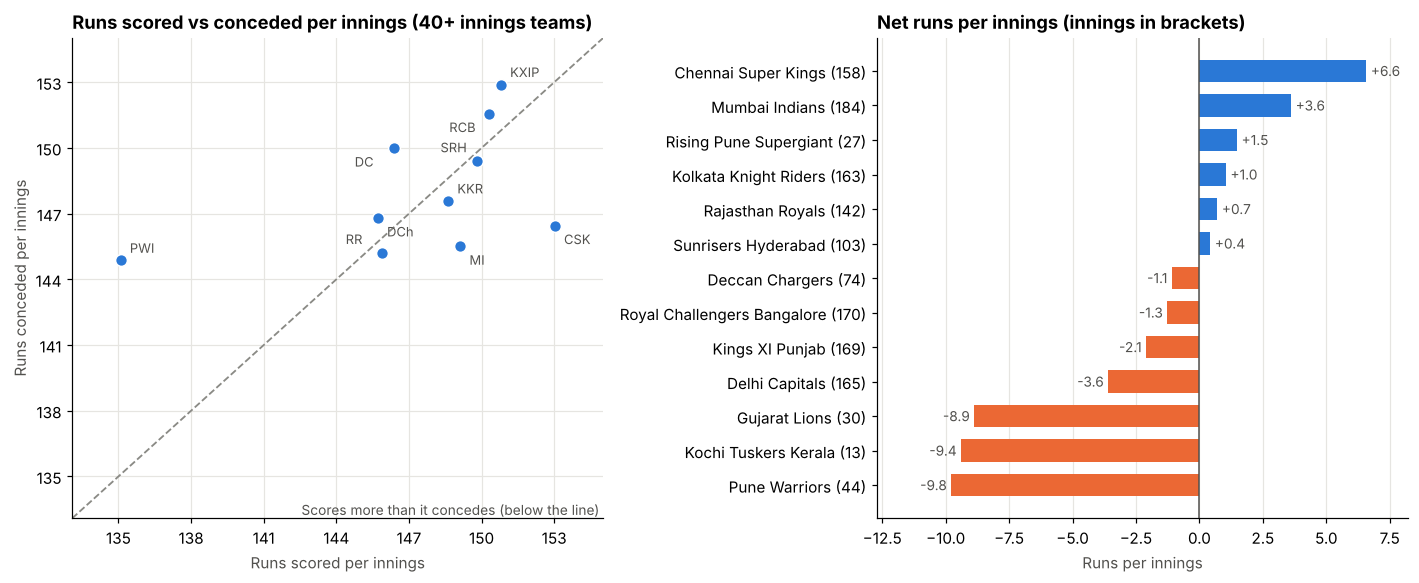

Abbreviations: CSK Chennai, MI Mumbai, RCB Bangalore, KKR Kolkata, KXIP Punjab, DC Delhi, RR Rajasthan, SRH Sunrisers, DCh Deccan, PWI Pune Warriors, GL Gujarat, KTK Kochi, RPS Rising Pune


In [85]:
# Defence: runs conceded and wickets taken, and the net result

bowling = team_inn.groupby("bowl_team").agg(
    innings=("runs", "size"), runs_conceded=("runs", "sum"), balls=("balls", "sum"), wickets_taken=("wickets", "sum"))

bowling["runs_conceded_per_innings"] = bowling["runs_conceded"] / bowling["innings"]

bowling["wickets_per_innings"] = bowling["wickets_taken"] / bowling["innings"]

bowling["runs_per_wicket"] = bowling["runs_conceded"] / bowling["wickets_taken"]

bowling["balls_per_wicket"] = bowling["balls"] / bowling["wickets_taken"]

teams = batting[["innings", "runs_per_innings"]].join(
    bowling[["runs_conceded_per_innings", "wickets_per_innings", "runs_per_wicket", "balls_per_wicket"]])

teams["net_runs_per_innings"] = teams["runs_per_innings"] - teams["runs_conceded_per_innings"]

teams = teams.sort_values("net_runs_per_innings", ascending=False)

display(teams.round(1))

print("net_runs_per_innings = runs scored minus runs conceded off the bat, per innings. It is a rough guide to strength, not a win record.")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))

ax = axes[0]

sc = teams[teams["innings"] >= MIN_TEAM_INNINGS]                 # the three small-sample teams would only crowd the picture

ax.scatter(sc["runs_per_innings"], sc["runs_conceded_per_innings"], s=60, color=BLUE, edgecolor="white", zorder=3)

lo = min(sc["runs_per_innings"].min(), sc["runs_conceded_per_innings"].min()) - 2

hi = max(sc["runs_per_innings"].max(), sc["runs_conceded_per_innings"].max()) + 2

ax.plot([lo, hi], [lo, hi], color=GREY, ls="--", lw=1.2)

ABBR = {"Royal Challengers Bangalore": "RCB", "Kolkata Knight Riders": "KKR", "Chennai Super Kings": "CSK", "Mumbai Indians": "MI",
        "Sunrisers Hyderabad": "SRH", "Rajasthan Royals": "RR", "Kings XI Punjab": "KXIP", "Delhi Capitals": "DC", "Deccan Chargers": "DCh",
        "Pune Warriors": "PWI", "Gujarat Lions": "GL", "Kochi Tuskers Kerala": "KTK", "Rising Pune Supergiant": "RPS"}

offsets = [(6, 5), (6, -12), (-24, 6), (-26, -12)]            # alternate label positions so neighbours do not overlap

for i, (name, r) in enumerate(sc.sort_values("runs_per_innings").iterrows()):
    ax.annotate(ABBR.get(name, name), (r["runs_per_innings"], r["runs_conceded_per_innings"]), textcoords="offset points",
                xytext=offsets[i % len(offsets)], fontsize=8.5, color=INK)

ax.set_xlim(lo, hi)

ax.set_ylim(lo, hi)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax.yaxis.set_major_locator(MaxNLocator(integer=True))

ax.text(hi, lo, "Scores more than it concedes (below the line) ", ha="right", va="bottom", fontsize=9, color=INK)

ax.set_title(f"Runs scored vs conceded per innings ({MIN_TEAM_INNINGS}+ innings teams)")

ax.set_xlabel("Runs scored per innings")

ax.set_ylabel("Runs conceded per innings")

net = teams["net_runs_per_innings"]

y = np.arange(len(net))

bars = axes[1].barh(y, net.values, color=np.where(net.values >= 0, BLUE, ORANGE), height=0.65)

axes[1].set_yticks(y)

axes[1].set_yticklabels([f"{t} ({int(n)})" for t, n in zip(teams.index, teams["innings"])])

axes[1].invert_yaxis()

axes[1].bar_label(bars, fmt="%+.1f", padding=3, fontsize=9, color=INK)

axes[1].axvline(0, color=INK, lw=1)

axes[1].set_title("Net runs per innings (innings in brackets)")

axes[1].set_xlabel("Runs per innings")

axes[1].grid(axis="y", visible=False)

axes[1].set_xlim(net.min() * 1.3 if net.min() < 0 else -1, net.max() * 1.25)

plt.tight_layout()

plt.show()

print("Abbreviations: " + ", ".join(["CSK Chennai", "MI Mumbai", "RCB Bangalore", "KKR Kolkata", "KXIP Punjab", "DC Delhi", "RR Rajasthan",
                                      "SRH Sunrisers", "DCh Deccan", "PWI Pune Warriors", "GL Gujarat", "KTK Kochi", "RPS Rising Pune"]))

,innings,runs,strike_rate,wickets,sixes
Batting first,721,154.2,128.3,6.1,5.7
Chasing,721,142.9,126.8,5.7,5.2


Batting first scores +11.3 runs more off the bat than chasing on average (p < 0.001). Chasing sides stop as soon as the target is reached, so fewer runs does not mean worse batting.


,batting_first,chasing,difference
bat_team,,,
Gujarat Lions,155.2,153.3,1.9
Chennai Super Kings,158.9,146.2,12.7
Rising Pune Supergiant,159.3,142.7,16.6
Kings XI Punjab,153.3,148.1,5.2
Royal Challengers Bangalore,159.7,141.7,18.0
Sunrisers Hyderabad,155.6,142.0,13.6
Mumbai Indians,155.4,141.8,13.5
Kolkata Knight Riders,154.3,143.7,10.6
Delhi Capitals,151.0,142.9,8.1


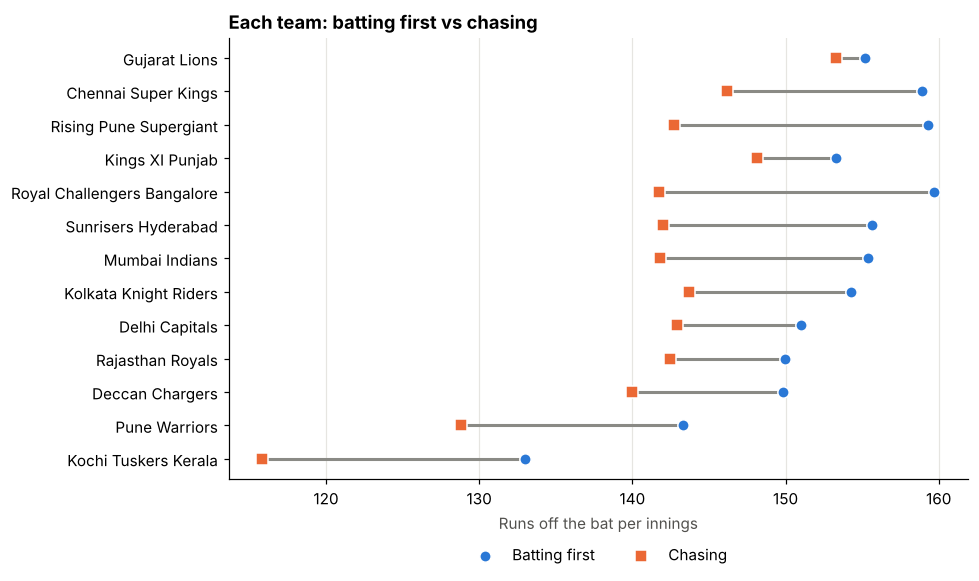

In [86]:
# Batting first or chasing?

by_inn = team_inn.groupby("innings_no").agg(innings=("runs", "size"), runs=("runs", "mean"), strike_rate=("strike_rate", "mean"),
                                           wickets=("wickets", "mean"), sixes=("sixes", "mean"))
by_inn.index = ["Batting first", "Chasing"]
display(by_inn.round(1))
a = team_inn.loc[team_inn["innings_no"] == 1, "runs"]
b = team_inn.loc[team_inn["innings_no"] == 2, "runs"]
u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
print(f"Batting first scores {a.mean() - b.mean():+.1f} runs more off the bat than chasing on average (p {'< 0.001' if p < 0.001 else f'= {p:.3f}'}). "
      "Chasing sides stop as soon as the target is reached, so fewer runs does not mean worse batting.")

split = team_inn.pivot_table(index="bat_team", columns="innings_no", values="runs", aggfunc="mean")
split.columns = ["batting_first", "chasing"]
split["difference"] = split["batting_first"] - split["chasing"]
split = split.loc[batting.index]
display(split.round(1))

ys = np.arange(len(split))
fig, ax = plt.subplots(figsize=(9, 5.4))
ax.hlines(ys, split["chasing"], split["batting_first"], color=GREY, lw=2, zorder=1)
ax.scatter(split["batting_first"], ys, color=BLUE, s=55, zorder=2, edgecolor="white", label="Batting first")
ax.scatter(split["chasing"], ys, color=ORANGE, s=55, marker="s", zorder=3, edgecolor="white", label="Chasing")
ax.set_yticks(ys)
ax.set_yticklabels(split.index)
ax.invert_yaxis()
ax.set_xlabel("Runs off the bat per innings")
ax.set_title("Each team: batting first vs chasing")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout()
plt.show()

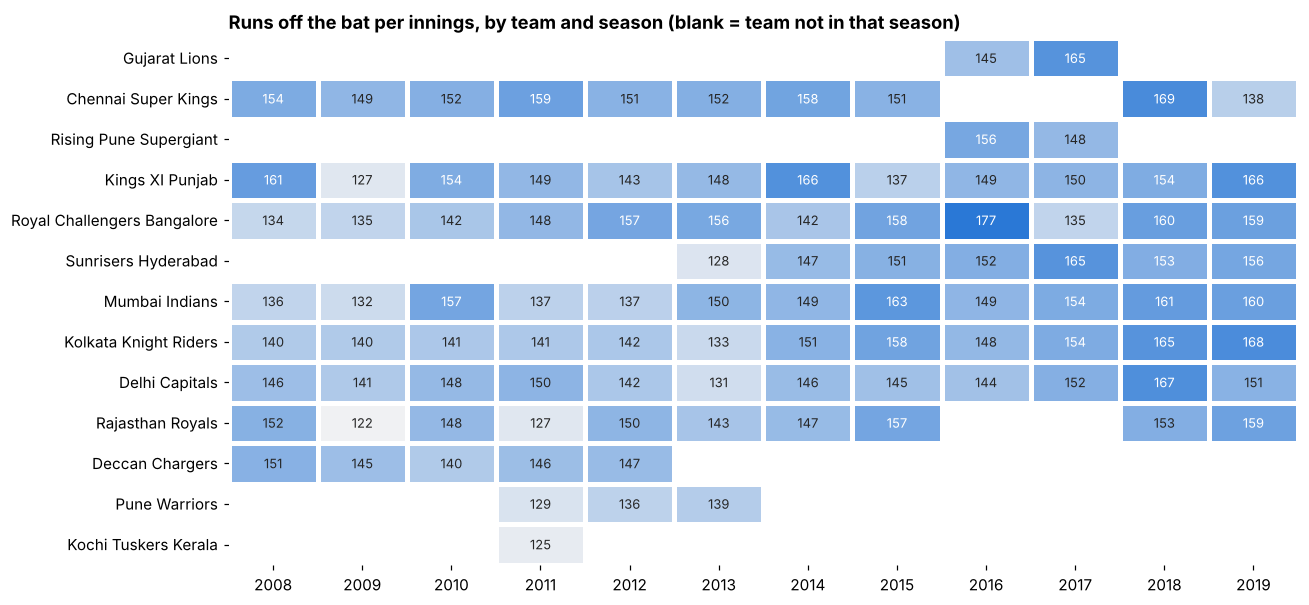

Strongest team-seasons by net runs per innings (10+ innings):


,season,bat_team,innings,scored,conceded,net
0,2011,Chennai Super Kings,14,158.9,142.1,16.8
1,2015,Royal Challengers Bangalore,11,157.7,141.5,16.3
2,2016,Royal Challengers Bangalore,15,177.3,162.7,14.7
3,2010,Mumbai Indians,15,156.8,142.8,14.0
4,2012,Chennai Super Kings,18,150.9,137.7,13.3
5,2008,Kolkata Knight Riders,11,140.1,127.0,13.1
6,2013,Chennai Super Kings,17,152.4,140.0,12.4
7,2009,Chennai Super Kings,14,148.9,137.5,11.4


Weakest team-seasons:


,season,bat_team,innings,scored,conceded,net
0,2015,Kings XI Punjab,13,137.5,161.2,-23.7
1,2013,Pune Warriors,15,139.1,153.7,-14.6
2,2013,Delhi Capitals,16,131.4,145.6,-14.2
3,2008,Royal Challengers Bangalore,13,134.4,148.4,-14.0
4,2017,Royal Challengers Bangalore,13,135.4,148.4,-13.0


In [87]:
# Team strength map: runs per innings, every team and season

grid = team_inn.pivot_table(index="bat_team", columns="season", values="runs", aggfunc="mean").loc[batting.index]
fig, ax = plt.subplots(figsize=(12, 5.6))
sns.heatmap(grid, annot=True, fmt=".0f", cmap=sns.light_palette(BLUE, as_cmap=True), cbar=False, linewidths=2, linecolor="white",
            mask=grid.isna(), annot_kws={"fontsize": 8.5}, ax=ax)
ax.set_title("Runs off the bat per innings, by team and season (blank = team not in that season)")
ax.set_xlabel("")
ax.set_ylabel("")
ax.grid(False)
plt.tight_layout()
plt.show()

ts = team_inn.groupby(["season", "bat_team"]).agg(innings=("runs", "size"), scored=("runs", "mean")).reset_index()
conc = team_inn.groupby(["season", "bowl_team"])["runs"].mean().rename("conceded").reset_index().rename(columns={"bowl_team": "bat_team"})
ts = ts.merge(conc, on=["season", "bat_team"])
ts["net"] = ts["scored"] - ts["conceded"]
ts = ts[ts["innings"] >= 10]

print("Strongest team-seasons by net runs per innings (10+ innings):")
display(ts.nlargest(8, "net").round(1).reset_index(drop=True))

print("Weakest team-seasons:")
display(ts.nsmallest(5, "net").round(1).reset_index(drop=True))

# Task 2: Identify strong and weak performers

92 batters rated (>= 500 balls). {'Average': 46, 'Strong': 23, 'Weak': 23}
Strongest batters:


,innings,runs,average,strike_rate,pct_30_plus,perf_index
batsmen,,,,,,
AD Russell,52,1400,33.33,186.42,44.23,2.07
RR Pant,54,1736,36.17,162.70,48.15,1.71
DA Warner,126,4706,43.17,142.39,53.17,1.68
CH Gayle,124,4484,41.14,151.03,44.35,1.55
AB de Villiers,142,4395,39.95,151.24,39.44,1.36
KL Rahul,58,1977,42.06,138.16,44.83,1.28
SE Marsh,69,2477,39.95,132.74,53.62,1.28
LMP Simmons,29,1079,39.96,126.64,58.62,1.26
ML Hayden,32,1107,36.90,137.52,53.12,1.23


Weakest rated batters:


,innings,runs,average,strike_rate,pct_30_plus,perf_index
batsmen,,,,,,
PP Chawla,81,584,11.92,111.45,0.00,-2.23
AM Nayar,50,672,17.68,116.46,12.00,-1.47
MS Bisla,39,798,21.00,113.68,15.38,-1.27
NV Ojha,94,1554,20.72,118.35,11.70,-1.27
IK Pathan,82,1139,21.49,120.40,10.98,-1.20
TL Suman,40,676,21.12,117.57,15.00,-1.18
AR Patel,63,796,18.95,126.35,11.11,-1.17
Harbhajan Singh,88,829,15.64,138.17,6.82,-1.15
STR Binny,68,880,19.13,128.84,14.71,-0.99


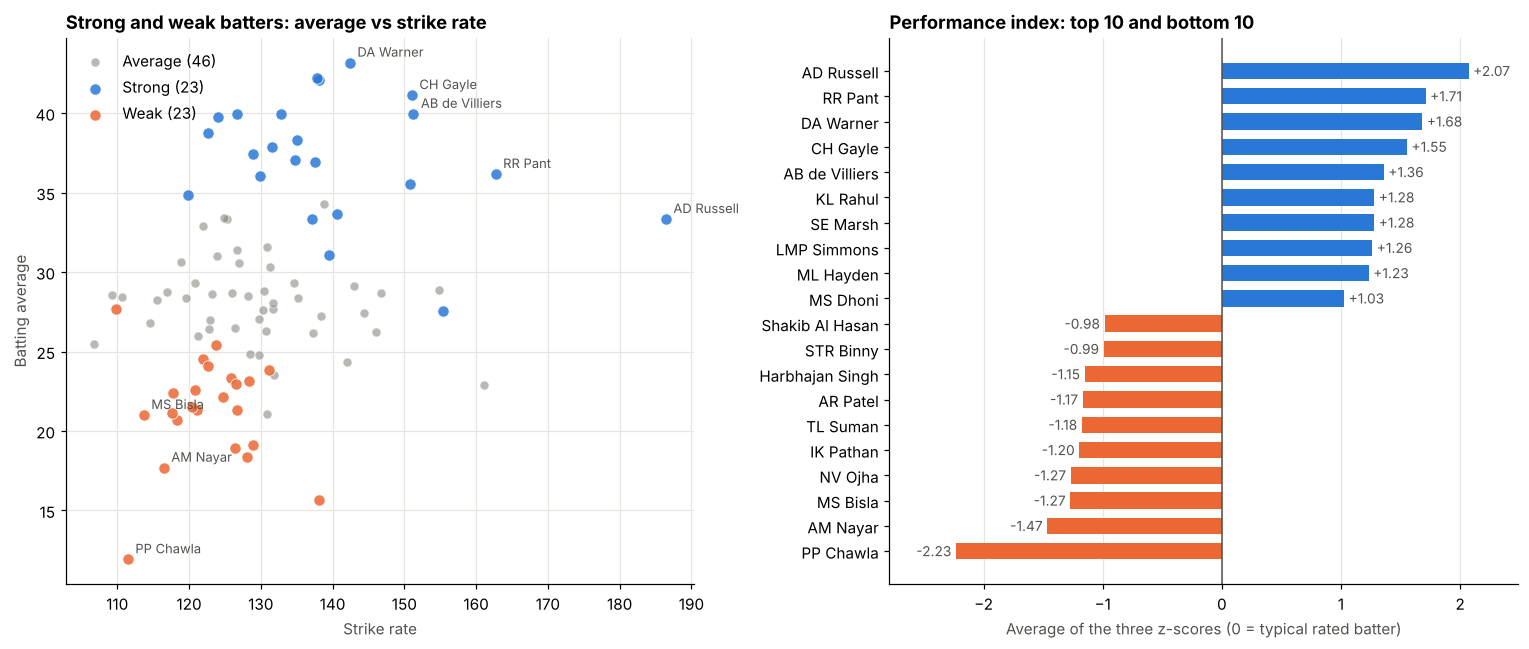

In [88]:
# Performance index for batters

players = summarise(bat, "batsmen")
qual = players[players["balls"] >= MIN_BALLS].copy()
parts = ["average", "strike_rate", "pct_30_plus"]

for c in parts:
    qual["z_" + c] = (qual[c] - qual[c].mean()) / qual[c].std()

qual["perf_index"] = qual[["z_" + c for c in parts]].mean(axis=1)

q75, q25 = qual["perf_index"].quantile([0.75, 0.25])

qual["rating"] = np.select([qual["perf_index"] >= q75, qual["perf_index"] <= q25], ["Strong", "Weak"], default="Average")

print(f"{len(qual)} batters rated (>= {MIN_BALLS} balls). {qual['rating'].value_counts().to_dict()}")

cols = ["innings", "runs", "average", "strike_rate", "pct_30_plus", "perf_index"]

print("Strongest batters:")
display(qual.nlargest(10, "perf_index")[cols].round(2))

print("Weakest rated batters:")
display(qual.nsmallest(10, "perf_index")[cols].round(2))

top10, bottom10 = qual.nlargest(10, "perf_index"), qual.nsmallest(10, "perf_index")
rank_view = pd.concat([top10, bottom10.iloc[::-1]])
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
ax = axes[0]

for label, color, size in [("Average", GREY, 35), ("Strong", BLUE, 55), ("Weak", ORANGE, 55)]:
    s = qual[qual["rating"] == label]
    ax.scatter(s["strike_rate"], s["average"], s=size, color=color, edgecolor="white", linewidth=0.6, alpha=0.85 if label != "Average" else 0.6,
               label=f"{label} ({len(s)})", zorder=3 if label != "Average" else 2)

for name, r in pd.concat([qual.nlargest(5, "perf_index"), qual.nsmallest(3, "perf_index")]).iterrows():
    ax.annotate(name, (r["strike_rate"], r["average"]), textcoords="offset points", xytext=(5, 4), fontsize=8.5, color=INK)

ax.set_title("Strong and weak batters: average vs strike rate")
ax.set_xlabel("Strike rate")
ax.set_ylabel("Batting average")
ax.legend(frameon=False, loc="upper left")

ax = axes[1]
y = np.arange(len(rank_view))
vals = rank_view["perf_index"].values
bars = ax.barh(y, vals, color=np.where(vals >= 0, BLUE, ORANGE), height=0.65)

ax.set_yticks(y)
ax.set_yticklabels(rank_view.index)
ax.invert_yaxis()

ax.bar_label(bars, fmt="%+.2f", padding=3, fontsize=9, color=INK)
ax.axvline(0, color=INK, lw=1)

ax.set_title("Performance index: top 10 and bottom 10")
ax.set_xlabel("Average of the three z-scores (0 = typical rated batter)")

ax.grid(axis="y", visible=False)
ax.set_xlim(vals.min() * 1.25, vals.max() * 1.2)

plt.tight_layout()
plt.show()

Early: 2008-2013   Late: 2014-2019
37 batters with 20+ innings in both halves. Most improved:


,innings_early,innings_late,average_early,average_late,strike_rate_early,strike_rate_late,change_score
batsmen,,,,,,,
DA Warner,55,71,28.7,55.4,133.1,146.9,2.1
AB de Villiers,66,76,34.6,44.1,134.9,163.3,1.6
V Kohli,85,84,31.6,44.2,124.1,137.6,1.2
PA Patel,65,72,20.8,24.1,109.1,131.0,1.0
MK Pandey,44,76,24.9,32.2,114.0,124.5,0.8
JP Duminy,38,39,36.2,43.8,119.3,128.8,0.8
RV Uthappa,86,84,27.0,30.5,124.0,136.3,0.6
KD Karthik,81,82,25.2,29.0,123.9,135.7,0.6


Biggest decline:


,innings_early,innings_late,average_early,average_late,strike_rate_early,strike_rate_late,change_score
batsmen,,,,,,,
CH Gayle,58,66,52.3,32.3,160.2,140.8,-2.0
STR Binny,25,43,28.5,14.6,141.7,118.6,-1.8
Harbhajan Singh,53,35,17.1,13.5,150.4,119.4,-1.5
SR Watson,54,76,39.7,25.6,145.6,134.0,-1.4
V Sehwag,79,25,29.4,22.2,160.3,138.8,-1.3
SE Marsh,49,20,44.3,30.2,133.3,131.1,-1.0
SK Raina,95,94,35.0,31.7,141.4,132.7,-0.6
M Vijay,64,39,26.7,26.0,127.9,115.4,-0.6


League strike rate of these batters: 130.1 early vs 131.0 late.


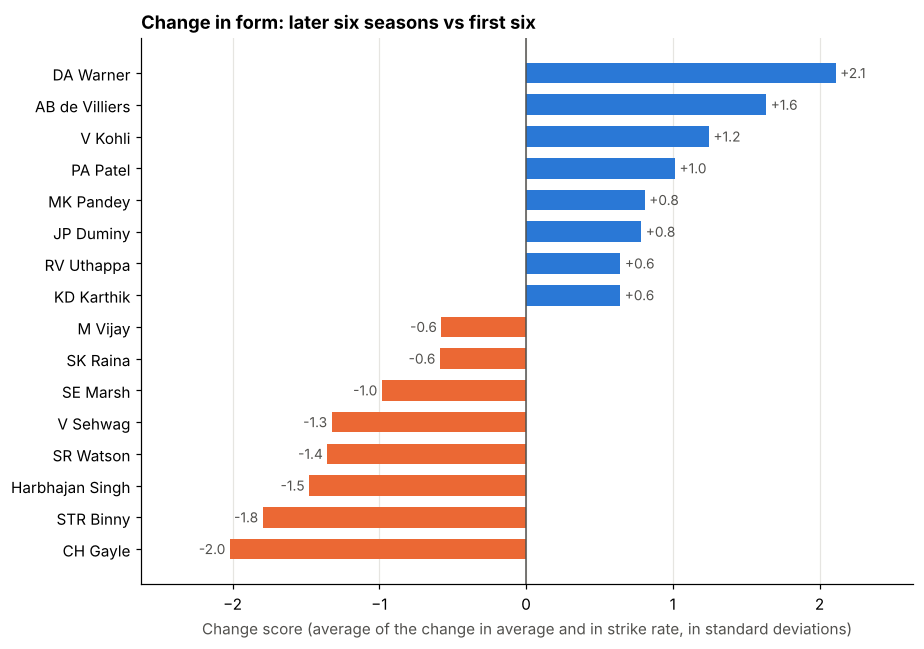

In [89]:
# Who is improving and who is fading? First six seasons against the last six

early_seasons = sorted(bat["season"].unique())[:6]

late_seasons = sorted(bat["season"].unique())[6:]

print(f"Early: {early_seasons[0]}-{early_seasons[-1]}   Late: {late_seasons[0]}-{late_seasons[-1]}")

early = summarise(bat[bat["season"].isin(early_seasons)], "batsmen")

late = summarise(bat[bat["season"].isin(late_seasons)], "batsmen")

both = early.join(late, lsuffix="_early", rsuffix="_late", how="inner")

both = both[(both["innings_early"] >= 20) & (both["innings_late"] >= 20)].copy()

both["d_average"] = both["average_late"] - both["average_early"]

both["d_strike_rate"] = both["strike_rate_late"] - both["strike_rate_early"]

both["change_score"] = ((both["d_average"] - both["d_average"].mean()) / both["d_average"].std()
                        + (both["d_strike_rate"] - both["d_strike_rate"].mean()) / both["d_strike_rate"].std()) / 2

show = ["innings_early", "innings_late", "average_early", "average_late", "strike_rate_early", "strike_rate_late", "change_score"]

print(f"{len(both)} batters with 20+ innings in both halves. Most improved:")
display(both.nlargest(8, "change_score")[show].round(1))

print("Biggest decline:")
display(both.nsmallest(8, "change_score")[show].round(1))

print(f"League strike rate of these batters: {both['strike_rate_early'].mean():.1f} early vs {both['strike_rate_late'].mean():.1f} late.")

movers = pd.concat([both.nlargest(8, "change_score"), both.nsmallest(8, "change_score").iloc[::-1]])

fig, ax = plt.subplots(figsize=(8.5, 6))

y = np.arange(len(movers))

vals = movers["change_score"].values

bars = ax.barh(y, vals, color=np.where(vals >= 0, BLUE, ORANGE), height=0.65)

ax.set_yticks(y)
ax.set_yticklabels(movers.index)
ax.invert_yaxis()
ax.bar_label(bars, fmt="%+.1f", padding=3, fontsize=9, color=INK)
ax.axvline(0, color=INK, lw=1)
ax.set_title("Change in form: later six seasons vs first six")
ax.set_xlabel("Change score (average of the change in average and in strike rate, in standard deviations)")
ax.grid(axis="y", visible=False)
ax.set_xlim(vals.min() * 1.3, vals.max() * 1.25)
plt.tight_layout()
plt.show()

In [90]:
# Strong performers in every discipline

bowler_file, fielder_file = "ipl_bowler_summary.csv", "ipl_fielder_summary.csv"

leaders = {"Best batter (performance index)": f"{qual['perf_index'].idxmax()}  ({qual['perf_index'].max():+.2f})"}

if os.path.exists(bowler_file) and os.path.exists(fielder_file):
    bowlers = pd.read_csv(bowler_file, index_col=0)
    fielders = pd.read_csv(fielder_file, index_col=0)
    clear_b = bowlers[~bowlers["ambiguous"]].nlargest(5, "wickets")
    clear_f = fielders[(~fielders["ambiguous"]) & (~fielders["is_keeper"])].assign(
        catches_and_run_outs=lambda d: d["catches_fielder"] + d["run_outs"]).nlargest(5, "catches_and_run_outs")
    keepers = fielders[fielders["is_keeper"]].nlargest(5, "keeper_dismissals")
    table = pd.DataFrame({
        "Top wicket-takers": [f"{n} ({int(r.wickets)})" for n, r in clear_b.iterrows()],
        "Top fielders (catches + run outs)": [f"{n} ({int(r.catches_and_run_outs)})" for n, r in clear_f.iterrows()],
        "Top wicket keepers (dismissals)": [f"{n} ({int(r.keeper_dismissals)})" for n, r in keepers.iterrows()],
    }, index=range(1, 6))
    display(table)
    leaders["Top wicket-taker (clear name)"] = f"{clear_b.index[0]}  ({int(clear_b.iloc[0]['wickets'])} wickets)"
    leaders["Best fielder (not keeping)"] = f"{clear_f.index[0]}  ({int(clear_f.iloc[0]['catches_and_run_outs'])})"
    leaders["Top wicket keeper"] = f"{keepers.index[0]}  ({int(keepers.iloc[0]['keeper_dismissals'])} dismissals)"
    print("Bowlers can only be ranked by wickets (no overs or runs conceded in the file), so there is no 'weak bowler' list.")

else:
    print("Objective 3 files not found; run Objective 3 first to add bowlers and fielders here. Batters are covered above.")

display(pd.Series(leaders, name="leader").to_frame())

,Top wicket-takers,Top fielders (catches + run outs),Top wicket keepers (dismissals)
1,Malinga (170),Raina (118),Dhoni (132)
2,Morkel (162),de Villiers (105),Karthik (131)
3,Mishra (154),Pollard (95),Uthappa (90)
4,Chawla (150),Kohli (92),Patel (79)
5,Harbhajan Singh (150),Bravo (89),Ojha (75)


Bowlers can only be ranked by wickets (no overs or runs conceded in the file), so there is no 'weak bowler' list.


,leader
Best batter (performance index),AD Russell (+2.07)
Top wicket-taker (clear name),Malinga (170 wickets)
Best fielder (not keeping),Raina (118)
Top wicket keeper,Dhoni (132 dismissals)


# Task 3: Understand relationships between runs, balls, boundaries, and strike rate #

Pearson correlation:


,R,B,fours,sixes,SR
R,1.00,0.93,0.86,0.75,0.49
B,0.93,1.00,0.80,0.58,0.29
fours,0.86,0.80,1.00,0.44,0.43
sixes,0.75,0.58,0.44,1.00,0.49
SR,0.49,0.29,0.43,0.49,1.00


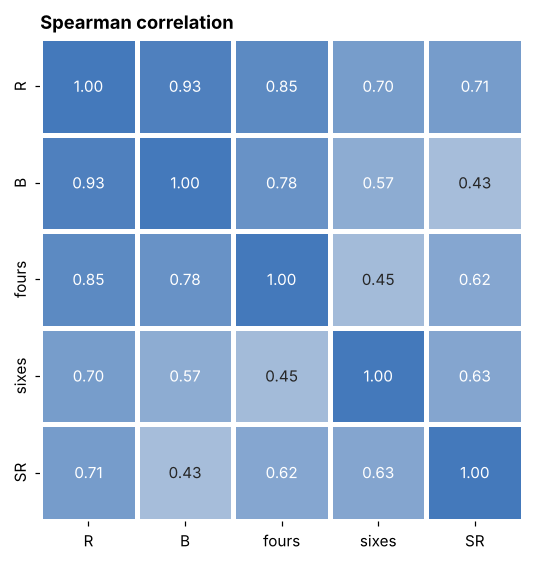

In [91]:
# How strongly are they linked? (Spearman = rank correlation, suited to skewed data)

bat["boundaries"] = bat["fours"] + bat["sixes"]

bat["boundary_rate"] = np.where(bat["B"] > 0, bat["boundaries"] / bat["B"].replace(0, np.nan) * 100, np.nan)   # boundaries per 100 balls

cols = ["R", "B", "fours", "sixes", "SR"]

corr_s = bat[cols].corr(method="spearman")

corr_p = bat[cols].corr(method="pearson")

print("Pearson correlation:")
display(corr_p.round(2))

fig, ax = plt.subplots(figsize=(6.5, 5.2))

sns.heatmap(corr_s, annot=True, fmt=".2f", cmap=sns.diverging_palette(25, 250, as_cmap=True), center=0, vmin=-1, vmax=1,
            square=True, cbar=False, linewidths=2, linecolor="white", ax=ax)

ax.set_title("Spearman correlation")
ax.grid(False)

plt.tight_layout()
plt.show()

In [92]:
# What is a ball, a four and a six worth? (regression of runs on balls, fours and sixes)

def ols(X, y):
    X = np.column_stack([np.ones(len(X)), X])
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    pred = X @ coef
    r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return coef, r2

y = bat["R"].values.astype(float)
c1, r2_balls = ols(bat[["B"]].values.astype(float), y)
c3, r2_all = ols(bat[["B", "fours", "sixes"]].values.astype(float), y)

print(f"Runs on balls faced only          : R-squared {r2_balls:.2f}   (each ball adds {c1[1]:.2f} runs)")
print(f"Runs on balls, fours and sixes    : R-squared {r2_all:.2f}")
print(f"   each ball faced adds {c3[1]:.2f} runs, each four adds {c3[2]:.2f}, each six adds {c3[3]:.2f} (on top of the balls it used)")
print("A four is worth 4 runs and a six 6, but the ball used to hit it is also counted, so the extra from a boundary is roughly 4 (or 6) minus the usual runs per ball.")

# Typical pace, used again in Task 4: how many runs does an innings of this many balls normally make?

slope, intercept = np.polyfit(bat["B"], bat["R"], 1)
bat["z_pace"] = (bat["R"] - (intercept + slope * bat["B"])) / (bat["R"] - (intercept + slope * bat["B"])).std()
print(f"\nTypical innings: runs = {intercept:.1f} + {slope:.2f} x balls (about {slope * 6:.1f} runs an over). "
      f"{int((bat['z_pace'] > 3).sum())} innings are 3+ standard deviations above that pace.")

Runs on balls faced only          : R-squared 0.87   (each ball adds 1.44 runs)
Runs on balls, fours and sixes    : R-squared 0.98
   each ball faced adds 0.70 runs, each four adds 3.21, each six adds 5.44 (on top of the balls it used)
A four is worth 4 runs and a six 6, but the ball used to hit it is also counted, so the extra from a boundary is roughly 4 (or 6) minus the usual runs per ball.

Typical innings: runs = -2.4 + 1.44 x balls (about 8.6 runs an over). 156 innings are 3+ standard deviations above that pace.


Innings of 10+ balls: correlation between boundaries per 100 balls and strike rate = 0.88


,innings,runs,balls,strike_rate
boundary_rate,,,,
none,438,3900,6284,62.1
0-10,1307,24718,26554,93.1
10-20,2619,87165,69738,125.0
20-30,1310,57169,35629,160.5
30-40,442,20821,10295,202.2
40+,104,4788,1856,258.0


Strike rate by innings length and sixes hit (blank = under 15 innings):


sixes_band,0,1,2,3+
balls_band,,,,
1-5,72.0,231.0,338.0,NaN
6-10,87.0,159.0,230.0,294.0
11-20,97.0,134.0,173.0,214.0
21-30,103.0,126.0,147.0,183.0
31+,112.0,125.0,136.0,165.0


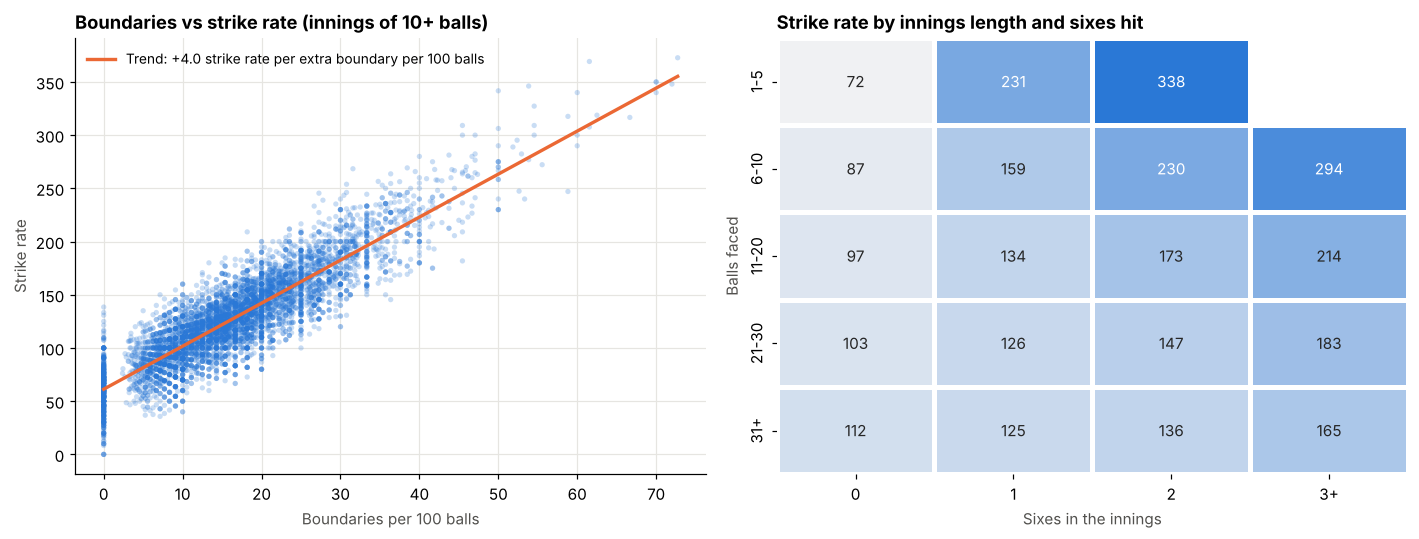

In [93]:
# Boundary frequency and strike rate, and the 'set batter' effect

f10 = bat[bat["B"] >= 10].copy()
r_pearson, _ = stats.pearsonr(f10["boundary_rate"], f10["SR"])

print(f"Innings of 10+ balls: correlation between boundaries per 100 balls and strike rate = {r_pearson:.2f}")

bins = pd.cut(f10["boundary_rate"], bins=[-0.1, 0, 10, 20, 30, 40, 100], labels=["none", "0-10", "10-20", "20-30", "30-40", "40+"])
by_bin = f10.groupby(bins, observed=True).agg(innings=("R", "size"), runs=("R", "sum"), balls=("B", "sum"))
by_bin["strike_rate"] = by_bin["runs"] / by_bin["balls"] * 100

display(by_bin.round(1))

# Strike rate by innings length and number of sixes

f1 = bat[bat["B"] > 0].copy()
f1["balls_band"] = pd.cut(f1["B"], bins=[0, 5, 10, 20, 30, 100], labels=["1-5", "6-10", "11-20", "21-30", "31+"])
f1["sixes_band"] = pd.cut(f1["sixes"], bins=[-1, 0, 1, 2, 30], labels=["0", "1", "2", "3+"])
cell = f1.groupby(["balls_band", "sixes_band"], observed=True).agg(n=("R", "size"), runs=("R", "sum"), balls=("B", "sum"))
cell["sr"] = np.where(cell["n"] >= 15, cell["runs"] / cell["balls"] * 100, np.nan)       # hide cells with under 15 innings
heat = cell["sr"].unstack()

print("Strike rate by innings length and sixes hit (blank = under 15 innings):")
display(heat.round(0))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.scatter(f10["boundary_rate"], f10["SR"], s=12, alpha=0.25, color=BLUE, edgecolors="none")
m, c0 = np.polyfit(f10["boundary_rate"], f10["SR"], 1)
xs = np.array([0, f10["boundary_rate"].max()])
ax.plot(xs, c0 + m * xs, color=ORANGE, lw=2.2, label=f"Trend: +{m:.1f} strike rate per extra boundary per 100 balls")
ax.set_title("Boundaries vs strike rate (innings of 10+ balls)")
ax.set_xlabel("Boundaries per 100 balls")
ax.set_ylabel("Strike rate")
ax.legend(frameon=False, loc="upper left", fontsize=9)

sns.heatmap(heat, annot=True, fmt=".0f", cmap=sns.light_palette(BLUE, as_cmap=True), cbar=False, linewidths=2, linecolor="white",
            mask=heat.isna(), annot_kws={"fontsize": 10}, ax=axes[1])
axes[1].set_title("Strike rate by innings length and sixes hit")
axes[1].set_xlabel("Sixes in the innings")
axes[1].set_ylabel("Balls faced")
axes[1].grid(False)

plt.tight_layout()
plt.show()

Across the 12 seasons: strike rate vs sixes per 100 balls r = 0.93; vs fours per 100 balls r = 0.61  (only 12 points, so read with care)
Spearman correlation of a team's total with:


,correlation
balls,0.30
wickets,-0.35
fours,0.65
sixes,0.72


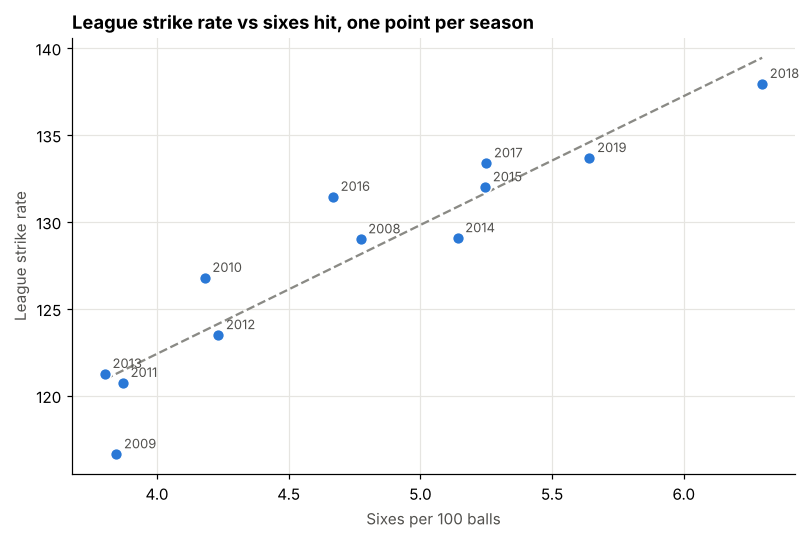

In [94]:
# Across seasons: did more sixes lift the league strike rate?

season = bat.groupby("season").agg(runs=("R", "sum"), balls=("B", "sum"), fours=("fours", "sum"), sixes=("sixes", "sum"))
season["strike_rate"] = season["runs"] / season["balls"] * 100
season["fours_per100"] = season["fours"] / season["balls"] * 100
season["sixes_per100"] = season["sixes"] / season["balls"] * 100
r_six = season["strike_rate"].corr(season["sixes_per100"])
r_four = season["strike_rate"].corr(season["fours_per100"])

print(f"Across the {len(season)} seasons: strike rate vs sixes per 100 balls r = {r_six:.2f}; vs fours per 100 balls r = {r_four:.2f}  (only {len(season)} points, so read with care)")

# Team innings: what goes with a high total?

tc = team_inn[["runs", "balls", "wickets", "fours", "sixes"]].corr(method="spearman")["runs"].drop("runs")
print("Spearman correlation of a team's total with:")
display(tc.rename("correlation").round(2).to_frame())

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(season["sixes_per100"], season["strike_rate"], s=60, color=BLUE, edgecolor="white", zorder=3)
mm, cc = np.polyfit(season["sixes_per100"], season["strike_rate"], 1)
xs = np.array([season["sixes_per100"].min(), season["sixes_per100"].max()])
ax.plot(xs, cc + mm * xs, color=GREY, ls="--", lw=1.5)

for yr, r in season.iterrows():
    ax.annotate(str(yr), (r["sixes_per100"], r["strike_rate"]), textcoords="offset points", xytext=(5, 4), fontsize=8.5, color=INK)

ax.set_title("League strike rate vs sixes hit, one point per season")
ax.set_xlabel("Sixes per 100 balls")
ax.set_ylabel("League strike rate")

plt.tight_layout()
plt.show()

# Task 4: Summarize key IPL performance insights using visualization

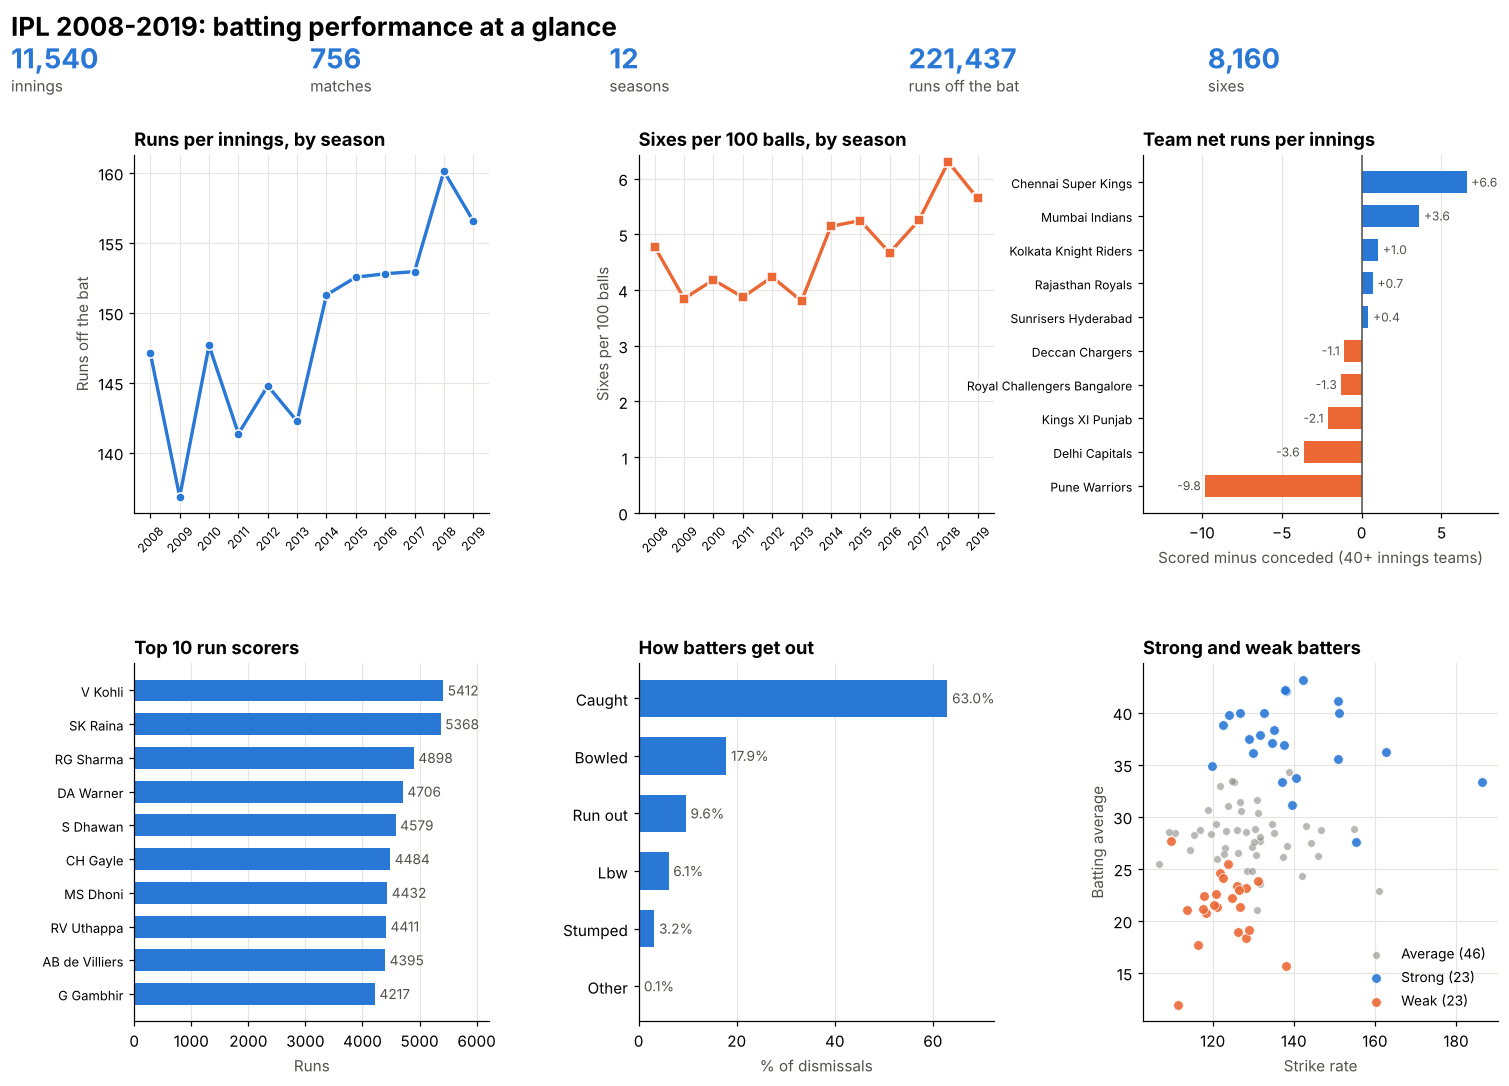

Saved ipl_key_insights.png (download it from the Colab file panel).


In [95]:
# 4.1 One-page dashboard
season_runs = team_inn.groupby("season")["runs"].mean()
top_runs = players["runs"].nlargest(10)
mix = dis["dismissal_mode"].where(dis["dismissal_mode"].isin(["caught", "bowled", "run out", "lbw", "stumped"]), "other")
mix = (mix.value_counts(normalize=True) * 100).sort_values(ascending=False)

fig = plt.figure(figsize=(16, 10.5))
gs = fig.add_gridspec(2, 3, hspace=0.42, wspace=0.42, top=0.86)
axes = [fig.add_subplot(gs[i, j]) for i in range(2) for j in range(3)]

fig.suptitle("IPL 2008-2019: batting performance at a glance", x=0.055, ha="left", fontsize=17, fontweight="bold", y=0.985)
kpis = [(f"{len(bat):,}", "innings"), (f"{bat['match_id'].nunique()}", "matches"),
        (f"{bat['season'].nunique()}", "seasons"), (f"{bat['R'].sum():,}", "runs off the bat"), (f"{int(bat['sixes'].sum()):,}", "sixes")]
for i, (v, lab) in enumerate(kpis):
    fig.text(0.055 + i * 0.17, 0.935, v, fontsize=18, fontweight="bold", color=BLUE, ha="left")
    fig.text(0.055 + i * 0.17, 0.915, lab, fontsize=10, color=INK, ha="left")

ax = axes[0]
ax.plot(season_runs.index, season_runs.values, color=BLUE, lw=2.2, marker="o", ms=6, mec="white")
ax.set_title("Runs per innings, by season")
ax.set_ylabel("Runs off the bat")
ax.set_xticks(season_runs.index)
ax.tick_params(axis="x", labelsize=8, rotation=45)

ax = axes[1]
ax.plot(season.index, season["sixes_per100"], color=ORANGE, lw=2.2, marker="s", ms=6, mec="white")
ax.set_title("Sixes per 100 balls, by season")
ax.set_ylabel("Sixes per 100 balls")
ax.set_xticks(season.index)
ax.tick_params(axis="x", labelsize=8, rotation=45)
ax.set_ylim(0, None)

ax = axes[2]
net = teams.loc[teams["innings"] >= MIN_TEAM_INNINGS, "net_runs_per_innings"]
y = np.arange(len(net))
bars = ax.barh(y, net.values, color=np.where(net.values >= 0, BLUE, ORANGE), height=0.65)
ax.set_yticks(y)
ax.set_yticklabels(net.index, fontsize=8)
ax.invert_yaxis()
ax.bar_label(bars, fmt="%+.1f", padding=3, fontsize=8, color=INK)
ax.axvline(0, color=INK, lw=1)
ax.set_title("Team net runs per innings")
ax.set_xlabel(f"Scored minus conceded ({MIN_TEAM_INNINGS}+ innings teams)")
ax.grid(axis="y", visible=False)
ax.set_xlim(net.min() * 1.4 if net.min() < 0 else -1, net.max() * 1.3)

hbar(axes[3], top_runs.index, top_runs.values, "Top 10 run scorers", "Runs")
axes[3].tick_params(axis="y", labelsize=8.5)

hbar(axes[4], [m.capitalize() for m in mix.index], mix.values, "How batters get out", "% of dismissals", fmt="%.1f%%")

ax = axes[5]
for label, color, size in [("Average", GREY, 25), ("Strong", BLUE, 40), ("Weak", ORANGE, 40)]:
    s = qual[qual["rating"] == label]
    ax.scatter(s["strike_rate"], s["average"], s=size, color=color, edgecolor="white", linewidth=0.5,
               alpha=0.9 if label != "Average" else 0.6, label=f"{label} ({len(s)})")
ax.set_title("Strong and weak batters")
ax.set_xlabel("Strike rate")
ax.set_ylabel("Batting average")
ax.legend(frameon=False, fontsize=9, loc="lower right")

fig.savefig("ipl_key_insights.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved ipl_key_insights.png (download it from the Colab file panel).")

In [96]:
# Key insights, with the numbers behind them (all calculated from the data)

# Ensure the boolean column helper is defined on bat
if "is_captain" not in bat.columns:
    bat["is_captain"] = bat["special_role"].str.contains("captain")

first, last = season_runs.index.min(), season_runs.index.max()
cum = players["runs"].sort_values(ascending=False).cumsum() / players["runs"].sum() * 100
modes_share = dis["dismissal_mode"].value_counts(normalize=True) * 100
season_dis = pd.crosstab(dis["season"], dis["dismissal_mode"], normalize="index") * 100
strong, weak = qual[qual["rating"] == "Strong"], qual[qual["rating"] == "Weak"]
not_out = bat[bat["dismissal_mode"] == "not out"]
gone = bat[bat["dismissed"]]

# Captains: all innings, then the same batters in both roles

yes, no = summarise(bat[bat["is_captain"]], "batsmen"), summarise(bat[~bat["is_captain"]], "batsmen")
pair = yes.join(no, lsuffix="_cap", rsuffix="_other", how="inner")
pair = pair[(pair["innings_cap"] >= 15) & (pair["innings_other"] >= 15)]
cap_rpi, norm_rpi = bat.loc[bat["is_captain"], "R"].mean(), bat.loc[~bat["is_captain"], "R"].mean()

main_teams = teams[teams["innings"] >= MIN_TEAM_INNINGS]                 # small-sample teams are not named best or weakest
top_team, low_team = main_teams.index[0], main_teams.index[-1]
best_bat_team = batting.loc[main_teams.index, "runs_per_innings"].idxmax()
ro_first, ro_last = season_dis["run out"].iloc[0], season_dis["run out"].iloc[-1]
ro_word = "fell" if ro_last < ro_first else "rose"

insights = pd.DataFrame([
    ("Scoring power has grown",
     f"Runs off the bat per innings went from {season_runs.loc[first]:.0f} ({first}) to {season_runs.loc[last]:.0f} ({last}). "
     f"Sixes per 100 balls rose from {season.loc[first, 'sixes_per100']:.1f} to {season.loc[last, 'sixes_per100']:.1f}; fours stayed near {season['fours_per100'].mean():.0f}.",
     "The extra scoring lines up with more sixes, not more fours. Six-hitting rate is worth tracking when judging batting."),
    ("Run scoring is concentrated in a small group",
     f"The top 10 batters scored {cum.iloc[9]:.0f}% of all runs and the top 50 scored {cum.iloc[49]:.0f}%. "
     f"{players['runs'].idxmax()} leads with {players['runs'].max():,} runs.",
     "A small group of batters supplies a large share of the runs, so squad planning should protect them."),
    ("Strong batters are fast and consistent",
     f"{len(strong)} of {len(qual)} rated batters are 'Strong' on average, strike rate and 30+ starts "
     f"(best: {', '.join(qual.nlargest(3, 'perf_index').index)}). Lowest rated: {', '.join(qual.nsmallest(3, 'perf_index').index)}.",
     "Rate batters on several measures together; total runs alone favours long careers. The lowest group can include bowlers and lower-order batters."),
    ("Teams differ in both scoring and defending",
     f"Highest scoring side: {best_bat_team} ({batting.loc[best_bat_team, 'runs_per_innings']:.0f} runs per innings). "
     f"Best net run difference: {top_team} ({teams.loc[top_team, 'net_runs_per_innings']:+.1f}); weakest: {low_team} ({teams.loc[low_team, 'net_runs_per_innings']:+.1f}). "
     f"Teams with {MIN_TEAM_INNINGS}+ innings only; rain-shortened matches left out.",
     "Team strength shows in runs conceded as much as runs scored. Results are not in the file, so net runs is a proxy."),
    ("Batting first scores more, but chasing is not weaker batting",
     f"Teams make {by_inn.loc['Batting first', 'runs']:.0f} runs batting first and {by_inn.loc['Chasing', 'runs']:.0f} chasing, "
     f"because chasers stop at the target.",
     "Compare teams on rates (strike rate, boundaries), not on chasing totals."),
    ("Caught is the main way out",
     f"{modes_share['caught']:.0f}% of dismissals are caught. Run outs {ro_word} from {ro_first:.1f}% of dismissals in {season_dis.index[0]} "
     f"to {ro_last:.1f}% in {season_dis.index[-1]} (first and last season only; see Objective 3 for the full trend).",
     "Catching is the main route to a wicket, so fielders who take catches matter."),
    ("Boundaries drive strike rate",
     f"Boundaries per 100 balls and strike rate correlate at r = {r_pearson:.2f} (10+ ball innings). "
     f"Across seasons, league strike rate tracks sixes per 100 balls at r = {r_six:.2f}.",
     "Part of this link is built in (boundaries are runs), but boundary frequency is a quick read on how fast a batter scores."),
    ("Roles and not-outs need context",
     f"Captains score {cap_rpi:.1f} runs per innings against {norm_rpi:.1f} for others, but the same batters make "
     f"{pair['runs_per_innings_cap'].mean():.1f} as captain and {pair['runs_per_innings_other'].mean():.1f} otherwise. "
     f"Not-out innings have a strike rate of {not_out['R'].sum() / not_out['B'].sum() * 100:.0f} against {gone['R'].sum() / gone['B'].sum() * 100:.0f} for dismissed.",
     "The captain gap is mostly about which batters become captain. Compare captains with themselves, and keep not-out innings separate from dismissed ones."),
    ("Exceptional innings are rare and real",
     f"{int((bat['z_pace'] > 3).sum())} innings ({(bat['z_pace'] > 3).mean() * 100:.1f}%) are 3+ standard deviations above the usual pace for their balls faced; "
     f"there are {int((bat['R'] >= 100).sum())} hundreds in {len(bat):,} innings.",
     "Big scores are real performances, not errors, so keep them in the data and flag them rather than removing them."),
], columns=["theme", "what the data shows", "so what"])

insights.index = range(1, len(insights) + 1)
display(insights)

,theme,what the data shows,so what
1,Scoring power has grown,Runs off the bat per innings went from 147 (20...,"The extra scoring lines up with more sixes, no..."
2,Run scoring is concentrated in a small group,The top 10 batters scored 21% of all runs and ...,A small group of batters supplies a large shar...
3,Strong batters are fast and consistent,23 of 92 rated batters are 'Strong' on average...,Rate batters on several measures together; tot...
4,Teams differ in both scoring and defending,Highest scoring side: Chennai Super Kings (153...,Team strength shows in runs conceded as much a...
5,"Batting first scores more, but chasing is not ...",Teams make 154 runs batting first and 143 chas...,"Compare teams on rates (strike rate, boundarie..."
6,Caught is the main way out,63% of dismissals are caught. Run outs fell fr...,"Catching is the main route to a wicket, so fie..."
7,Boundaries drive strike rate,Boundaries per 100 balls and strike rate corre...,Part of this link is built in (boundaries are ...
8,Roles and not-outs need context,Captains score 26.5 runs per innings against 1...,The captain gap is mostly about which batters ...
9,Exceptional innings are rare and real,156 innings (1.4%) are 3+ standard deviations ...,"Big scores are real performances, not errors, ..."


In [97]:
# Recommendations and data gaps

print("What to act on")
print(f" 1. Rate batters on average, strike rate and 30+ starts together (the performance index), not on totals: {len(strong)} batters qualify as strong.")
print(f" 2. Track six-hitting rate as a scouting measure; it moves closely with league strike rate across seasons (r = {r_six:.2f}; {season.loc[first, 'sixes_per100']:.1f} to {season.loc[last, 'sixes_per100']:.1f} sixes per 100 balls).")
print(f" 3. Read captain and not-out statistics with context: the same batters average {pair['runs_per_innings_cap'].mean():.1f} runs as captain and {pair['runs_per_innings_other'].mean():.1f} otherwise.")
print(f" 4. Compare teams on net runs and rates, since results and extras are not in the file.")

print()

print("What the file cannot tell us (worth collecting)")
print(" - batting team and innings number per row (derived here; 99.9% of rows agree with the batter's usual team),")
print(" - match result, toss and venue, so wins and losses cannot be analysed,")
print(" - overs bowled and runs conceded by each bowler, so economy rates and bowling averages are not possible,")
print(" - extras, so team totals here are runs off the bat only.")

What to act on
 1. Rate batters on average, strike rate and 30+ starts together (the performance index), not on totals: 23 batters qualify as strong.
 2. Track six-hitting rate as a scouting measure; it moves closely with league strike rate across seasons (r = 0.93; 4.8 to 5.6 sixes per 100 balls).
 3. Read captain and not-out statistics with context: the same batters average 27.3 runs as captain and 25.2 otherwise.
 4. Compare teams on net runs and rates, since results and extras are not in the file.

What the file cannot tell us (worth collecting)
 - batting team and innings number per row (derived here; 99.9% of rows agree with the batter's usual team),
 - match result, toss and venue, so wins and losses cannot be analysed,
 - overs bowled and runs conceded by each bowler, so economy rates and bowling averages are not possible,
 - extras, so team totals here are runs off the bat only.


In [98]:
# Save the outputs

ipl_cricket.drop(columns=["fielding_labels"]).to_csv("ipl_batting_with_teams.csv", index=False)

team_inn_all.round(2).to_csv("ipl_team_innings.csv", index=False)     # includes the 'shortened' flag

qual.round(3).to_csv("ipl_batter_index.csv")

insights.to_csv("ipl_key_insights.csv")

for f in ["ipl_batting_with_teams.csv", "ipl_team_innings.csv", "ipl_batter_index.csv", "ipl_key_insights.csv", "ipl_key_insights.png"]:
    print(f"{f:30s} {os.path.getsize(f) / 1024:8.0f} KB")

ipl_batting_with_teams.csv         2609 KB
ipl_team_innings.csv                121 KB
ipl_batter_index.csv                 11 KB
ipl_key_insights.csv                  3 KB
ipl_key_insights.png                291 KB
